# Formula 1 Podium Prediction — Milestone 1

Predict whether a driver finishes in the top three using information available after qualifying and before the race. Each modeling row represents one driver in one race.

This section inspects and cleans the source data. Missing model inputs will be handled later using training data only.

## 1. Data Inspection and Cleaning

### 1.1 Load the data without changing the originals

Import the libraries and load all 14 CSV files. Keep missing-value markers unchanged so we can count them, and store the original tables in `raw_tables` for comparison.


In [1]:
# Path helps us locate dataset files.
from pathlib import Path

# Pandas handles tables; NumPy supports numerical operations.
import pandas as pd
import numpy as np

# These libraries will help us visualize the data.
import matplotlib.pyplot as plt
import seaborn as sns

# Show all columns when displaying a small table.
pd.set_option("display.max_columns", None)

# Use a consistent appearance for our plots.
sns.set_theme(style="whitegrid")

# We will reuse this seed for reproducible random operations.
RANDOM_STATE = 42

In [2]:
# The folder containing the 14 Formula 1 CSV files.
data_folder = Path(
    "/kaggle/input/datasets/rohanrao/formula-1-world-championship-1950-2020"
)

# Load each CSV into a dictionary using its filename as the key.
# Keep missing-value placeholders unchanged for our initial audit.
raw_tables = {}

for file in sorted(data_folder.glob("*.csv")):
    raw_tables[file.stem] = pd.read_csv(file, keep_default_na=False)

# Show the number of rows and columns in each table.
table_summary = pd.DataFrame([
    {
        "Table": name,
        "Rows": table.shape[0],
        "Columns": table.shape[1]
    }
    for name, table in raw_tables.items()
])

print("Number of tables loaded:", len(raw_tables))
display(table_summary)

Number of tables loaded: 14


,Table,Rows,Columns
0,circuits,77,9
1,constructor_results,12625,5
2,constructor_standings,13391,7
3,constructors,212,5
4,driver_standings,34863,7
5,drivers,861,9
6,lap_times,589081,6
7,pit_stops,11371,7
8,qualifying,10494,9
9,races,1125,18


### 1.2 Check which seasons have results

The dataset name may not reflect its full coverage. Count listed races and races with at least one result per year; this does not verify every individual entry. The saved output covers 1950–2024.


In [3]:
# Use the raw tables for inspection without changing them.
races_raw = raw_tables["races"]
results_raw = raw_tables["results"]

# Find which races have at least one recorded result.
race_has_results = races_raw["raceId"].isin(results_raw["raceId"])

# Create a separate table summarizing coverage for each season.
season_coverage = (
    races_raw.assign(has_results=race_has_results)
    .groupby("year")
    .agg(
        races_listed=("raceId", "nunique"),
        races_with_results=("has_results", "sum")
    )
    .reset_index()
)

print("Earliest season listed:", races_raw["year"].min())
print("Latest season listed:", races_raw["year"].max())

# Check the latest season represented in the results table.
print(
    "Latest season with results:",
    races_raw.loc[race_has_results, "year"].max()
)

# Display recent seasons to check the assignment's required coverage.
display(season_coverage.tail(12))

Earliest season listed: 1950
Latest season listed: 2024
Latest season with results: 2024


,year,races_listed,races_with_results
63,2013,19,19
64,2014,19,19
65,2015,19,19
66,2016,21,21
67,2017,20,20
68,2018,21,21
69,2019,21,21
70,2020,17,17
71,2021,22,22
72,2022,22,22


### 1.3 Find missing values before cleaning

Missing data can appear as `\N`, empty text, or an actual null. Count all three forms and plot the most affected columns before deciding how to handle them. A high missing percentage alone does not justify deleting rows.


,Table,Column,Sentinel count,Empty count,Null count,Missing count,Missing percent
13,constructor_results,status,12608,0,0,12608,99.87
81,races,sprint_time,1110,0,0,1110,98.67
80,races,sprint_date,1107,0,0,1107,98.40
77,races,fp3_time,1072,0,0,1072,95.29
73,races,fp1_time,1057,0,0,1057,93.96
75,races,fp2_time,1057,0,0,1057,93.96
79,races,quali_time,1057,0,0,1057,93.96
76,races,fp3_date,1053,0,0,1053,93.60
35,drivers,number,802,0,0,802,93.15
72,races,fp1_date,1035,0,0,1035,92.00


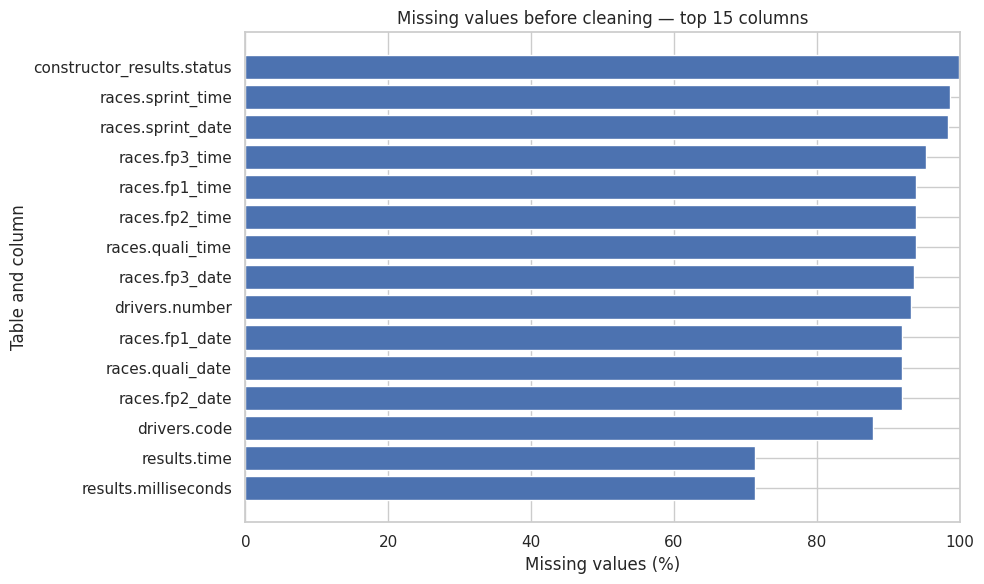

In [4]:
# Collect missing-value counts for every column in every table.
missing_records = []

for table_name, table in raw_tables.items():
    for column in table.columns:

        # These CSV files use the text \N to represent missing values.
        sentinel_count = table[column].eq("\\N").sum()

        # Empty fields were also preserved when we loaded the files.
        empty_count = table[column].eq("").sum()

        # Check for actual pandas missing values as well.
        null_count = table[column].isna().sum()

        total_missing = sentinel_count + empty_count + null_count

        missing_records.append({
            "Table": table_name,
            "Column": column,
            "Sentinel count": sentinel_count,
            "Empty count": empty_count,
            "Null count": null_count,
            "Missing count": total_missing,
            "Missing percent": (
                100 * total_missing / len(table) if len(table) > 0 else 0
            )
        })

# Save the complete audit, including columns with no missing values.
missing_audit_before = pd.DataFrame(missing_records)

# Display only affected columns, starting with the highest percentage.
missing_columns = (
    missing_audit_before[
        missing_audit_before["Missing count"] > 0
    ]
    .sort_values("Missing percent", ascending=False)
)

display(missing_columns.round(2))

# Visualize the 15 columns with the highest missing percentages.
top_missing = missing_columns.head(15)

if not top_missing.empty:
    plt.figure(figsize=(10, 6))

    plt.barh(
        top_missing["Table"] + "." + top_missing["Column"],
        top_missing["Missing percent"]
    )

    plt.gca().invert_yaxis()
    plt.xlabel("Missing values (%)")
    plt.ylabel("Table and column")
    plt.title("Missing values before cleaning — top 15 columns")
    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()

### 1.4 Give missing values one consistent format

Create `clean_tables` as copies and replace missing-value markers with `NaN`. Check that the missing counts match and every row is preserved. This standardizes missing data; it does not fill it.


In [5]:
# Create independent copies so the original tables stay unchanged.
clean_tables = {
    name: table.copy(deep=True)
    for name, table in raw_tables.items()
}

missing_check = []

for name, table in clean_tables.items():

    # Replace literal \N and empty strings with pandas missing values.
    # mask replaces only cells that match these conditions.
    placeholder_mask = table.eq("\\N") | table.eq("")
    clean_tables[name] = table.mask(placeholder_mask)

    # Get the missing count measured in our original audit.
    expected_missing = missing_audit_before.loc[
        missing_audit_before["Table"] == name,
        "Missing count"
    ].sum()

    # Pandas can now recognize the missing values using isna().
    actual_missing = clean_tables[name].isna().sum().sum()

    missing_check.append({
        "Table": name,
        "Missing before": int(expected_missing),
        "Missing after": int(actual_missing),
        "Row count unchanged": len(table) == len(raw_tables[name])
    })

missing_check = pd.DataFrame(missing_check)
display(missing_check)

# Verify that we changed the representation, not the missing count.
assert (
    missing_check["Missing before"] == missing_check["Missing after"]
).all(), "Missing counts do not match. Investigate before continuing."

assert missing_check["Row count unchanged"].all(), (
    "A table's row count changed unexpectedly."
)

print("Checks passed: missing values standardized and all rows preserved.")

,Table,Missing before,Missing after,Row count unchanged
0,circuits,0,0,True
1,constructor_results,12608,12608,True
2,constructor_standings,0,0,True
3,constructors,0,0,True
4,driver_standings,0,0,True
5,drivers,1559,1559,True
6,lap_times,0,0,True
7,pit_stops,0,0,True
8,qualifying,11668,11668,True
9,races,11349,11349,True


Checks passed: missing values standardized and all rows preserved.


### 1.5 Check IDs and repeated driver–race entries

A primary key identifies a record; it should be present and unique. We also check driver–race pairs because different result IDs can still describe the same driver in the same race. The audit found 85 repeated pairs across 176 rows.


In [6]:
# Define the column(s) that should uniquely identify each table's rows.
# Lap times and pit stops need multiple columns to identify one record.
primary_keys = {
    "circuits": ["circuitId"],
    "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"],
    "constructors": ["constructorId"],
    "driver_standings": ["driverStandingsId"],
    "drivers": ["driverId"],
    "lap_times": ["raceId", "driverId", "lap"],
    "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": ["qualifyId"],
    "races": ["raceId"],
    "results": ["resultId"],
    "seasons": ["year"],
    "sprint_results": ["resultId"],
    "status": ["statusId"]
}

key_records = []

for name, keys in primary_keys.items():
    table = clean_tables[name]

    key_records.append({
        "Table": name,
        "Key columns": ", ".join(keys),

        # Count rows missing any part of their key.
        "Rows with missing keys": int(
            table[keys].isna().any(axis=1).sum()
        ),

        # Count additional rows sharing a key with an earlier row.
        "Extra duplicate keys": int(
            table.duplicated(subset=keys).sum()
        )
    })

key_audit = pd.DataFrame(key_records)
display(key_audit)

# A unique resultId does not guarantee a unique driver–race pair.
# Our modeling table requires one row per driver in each race.
results = clean_tables["results"]

duplicate_mask = results.duplicated(
    subset=["raceId", "driverId"],
    keep=False
)

# Keep all rows involved in repeated pairs so we can inspect them.
duplicate_driver_races = (
    results.loc[duplicate_mask]
    .sort_values(["raceId", "driverId", "resultId"])
)

print(
    "\nNumber of repeated driver–race pairs:",
    duplicate_driver_races[["raceId", "driverId"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Total rows involved in those pairs:",
    len(duplicate_driver_races)
)

# Show a manageable sample, including the fields needed to compare rows.
display(
    duplicate_driver_races[
        ["resultId", "raceId", "driverId", "constructorId",
         "grid", "positionOrder", "points"]
    ].head(20)
)

,Table,Key columns,Rows with missing keys,Extra duplicate keys
0,circuits,circuitId,0,0
1,constructor_results,constructorResultsId,0,0
2,constructor_standings,constructorStandingsId,0,0
3,constructors,constructorId,0,0
4,driver_standings,driverStandingsId,0,0
5,drivers,driverId,0,0
6,lap_times,"raceId, driverId, lap",0,0
7,pit_stops,"raceId, driverId, stop",0,0
8,qualifying,qualifyId,0,0
9,races,raceId,0,0



Number of repeated driver–race pairs: 85
Total rows involved in those pairs: 176


,resultId,raceId,driverId,constructorId,grid,positionOrder,points
13188,13189,540,229,54,0,26,0.0
13191,13192,540,229,57,0,29,0.0
17362,17363,717,373,172,1,7,0.0
24298,24304,717,373,172,1,12,0.0
17740,17741,733,465,172,0,22,0.0
17743,17744,733,465,97,0,25,0.0
17961,17962,742,475,102,20,19,0.0
17963,17964,742,475,172,5,21,0.0
18062,18063,745,418,172,11,17,0.0
24297,24303,745,418,172,15,11,0.0


### 1.6 Investigate repeated entries before selecting rows

Add driver names and race years to understand the repeated entries. Check whether exactly one row has a positive grid position. None of the repeated pairs meets that rule, so grid alone cannot choose a reliable record.


,Repeated driver–race pairs
year,
1950,4
1951,4
1952,3
1953,14
1954,16
1955,15
1956,12
1957,8
1958,3


,year,race_name,forename,surname,resultId,constructorId,grid,positionOrder
170,1950,French Grand Prix,Louis,Rosier,20143,154,6,12
171,1950,French Grand Prix,Louis,Rosier,20182,154,15,6
168,1950,Indianapolis 500,Tony,Bettenhausen,20097,150,8,31
169,1950,Indianapolis 500,Tony,Bettenhausen,20179,113,9,5
174,1950,Italian Grand Prix,Alberto,Ascari,20166,6,2,17
175,1950,Italian Grand Prix,Alberto,Ascari,20183,6,6,2
172,1950,Italian Grand Prix,Juan,Fangio,20164,51,1,15
173,1950,Italian Grand Prix,Juan,Fangio,20184,51,7,13
162,1951,French Grand Prix,Alberto,Ascari,19919,6,6,2
163,1951,French Grand Prix,Alberto,Ascari,19935,6,3,18


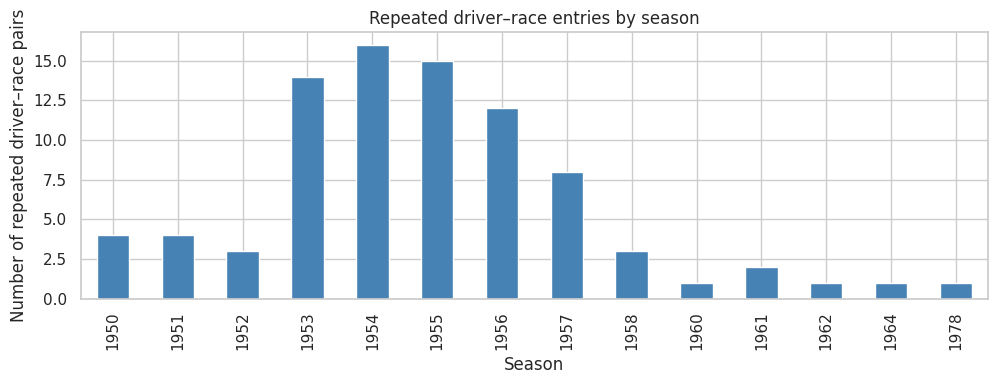

In [7]:
# Add race information to the repeated driver–race records.
# many_to_one verifies that each raceId matches only one race.
duplicate_details = duplicate_driver_races.merge(
    clean_tables["races"][["raceId", "year", "name"]],
    on="raceId",
    how="left",
    validate="many_to_one"
).rename(columns={"name": "race_name"})

# Add driver names so the records are easier to understand.
duplicate_details = duplicate_details.merge(
    clean_tables["drivers"][["driverId", "forename", "surname"]],
    on="driverId",
    how="left",
    validate="many_to_one"
)

# Count repeated driver–race pairs in each season.
# Count each pair once, even if it contains several result records.
duplicate_pairs_by_year = (
    duplicate_details[["year", "raceId", "driverId"]]
    .drop_duplicates()
    .groupby("year")
    .size()
    .rename("Repeated driver–race pairs")
)

display(duplicate_pairs_by_year.to_frame())

# Show the actual records with their historical context.
display(
    duplicate_details[
        ["year", "race_name", "forename", "surname",
         "resultId", "constructorId", "grid", "positionOrder"]
    ]
    .sort_values(["year", "race_name", "surname", "resultId"])
    .head(20)
)

# Visualize which seasons contain repeated entries.
if not duplicate_pairs_by_year.empty:
    duplicate_pairs_by_year.plot(
        kind="bar",
        figsize=(10, 4),
        color="steelblue"
    )

    plt.xlabel("Season")
    plt.ylabel("Number of repeated driver–race pairs")
    plt.title("Repeated driver–race entries by season")
    plt.tight_layout()
    plt.show()

In [8]:
# Work on a separate inspection table.
duplicate_review = duplicate_details.copy()

# Convert grid values to numbers for this check.
duplicate_review["grid_numeric"] = pd.to_numeric(
    duplicate_review["grid"],
    errors="raise"
)

# A positive grid gives a recorded starting position.
# This alone does not prove which car the driver originally started in.
duplicate_review["positive_grid"] = (
    duplicate_review["grid_numeric"] > 0
)

# Count how many rows in each repeated pair have a positive grid.
duplicate_grid_check = (
    duplicate_review
    .groupby(["raceId", "driverId"])
    .agg(
        year=("year", "first"),
        records=("resultId", "size"),
        positive_grid_rows=("positive_grid", "sum")
    )
    .reset_index()
)

# Summarize whether a "keep the positive grid" rule is unambiguous.
print("Repeated pairs grouped by number of positive-grid rows:")
display(
    duplicate_grid_check
    .groupby("positive_grid_rows")
    .size()
    .rename("Number of driver–race pairs")
    .to_frame()
)

# Inspect the later repeated entries separately.
# Add the recorded status to help understand these cases.
later_duplicates = duplicate_review.loc[
    duplicate_review["year"] > 1957
].merge(
    clean_tables["status"][["statusId", "status"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

display(
    later_duplicates[
        ["year", "race_name", "forename", "surname",
         "resultId", "constructorId", "grid",
         "positionOrder", "status"]
    ].sort_values(
        ["year", "race_name", "surname", "resultId"]
    )
)

Repeated pairs grouped by number of positive-grid rows:


,Number of driver–race pairs
positive_grid_rows,
0,3
2,76
3,6


,year,race_name,forename,surname,resultId,constructorId,grid,positionOrder,status
14,1958,French Grand Prix,Tony,Brooks,18612,118,5,18,Engine
15,1958,French Grand Prix,Tony,Brooks,20296,118,10,14,Engine
16,1958,Italian Grand Prix,Carroll,Shelby,18694,105,17,18,Handling
17,1958,Italian Grand Prix,Carroll,Shelby,20297,105,11,4,+1 Lap
12,1958,Monaco Grand Prix,Ron,Flockhart,18510,87,0,17,Did not qualify
13,1958,Monaco Grand Prix,Ron,Flockhart,18520,66,0,27,Did not qualify
10,1960,Argentine Grand Prix,Stirling,Moss,18083,170,1,17,Suspension
11,1960,Argentine Grand Prix,Stirling,Moss,22372,170,8,3,Finished
6,1961,British Grand Prix,Stirling,Moss,17962,102,20,19,Disqualified
7,1961,British Grand Prix,Stirling,Moss,17964,172,5,21,Brakes


### 1.7 Create one row per driver and race

For historical summaries, retain the best recorded finish, breaking ties with the smallest result ID. Flag all 85 ambiguous pairs for exclusion from modeling: choosing pre-race features using the eventual finish could bias predictions. This removes 91 extra rows from the separate driver–race table; the full results table is retained.


In [9]:
# Create a separate driver–race table.
# Keep clean_tables["results"] unchanged for reference and other analyses.
results_for_selection = clean_tables["results"].copy()

# Ensure finishing positions are sorted numerically.
results_for_selection["positionOrder"] = pd.to_numeric(
    results_for_selection["positionOrder"],
    errors="raise"
)

assert results_for_selection["positionOrder"].notna().all(), (
    "Missing finishing ranks need investigation before selecting records."
)

# Flag every record belonging to a repeated driver–race pair.
results_for_selection["ambiguous_driver_race"] = (
    results_for_selection.duplicated(
        subset=["raceId", "driverId"],
        keep=False
    )
)

# Keep the best recorded finish for each driver–race pair.
# resultId provides a consistent tie-breaker.
results_driver_race = (
    results_for_selection
    .sort_values(["raceId", "driverId", "positionOrder", "resultId"])
    .drop_duplicates(subset=["raceId", "driverId"], keep="first")
    .reset_index(drop=True)
)

# Verify that every driver–race pair is now unique.
assert not results_driver_race.duplicated(
    subset=["raceId", "driverId"]
).any(), "Repeated driver–race pairs remain."

# Record the effect of this cleaning decision.
duplicate_handling_summary = pd.DataFrame({
    "Measure": [
        "Original result rows",
        "Unique driver–race rows",
        "Extra records removed from this table",
        "Ambiguous pairs flagged",
        "Unambiguous rows available before further checks"
    ],
    "Count": [
        len(results_for_selection),
        len(results_driver_race),
        len(results_for_selection) - len(results_driver_race),
        int(results_driver_race["ambiguous_driver_race"].sum()),
        int((~results_driver_race["ambiguous_driver_race"]).sum())
    ]
})

display(duplicate_handling_summary)

,Measure,Count
0,Original result rows,26759
1,Unique driver–race rows,26668
2,Extra records removed from this table,91
3,Ambiguous pairs flagged,85
4,Unambiguous rows available before further checks,26583


### 1.8 Check that references match existing records

Before joining tables, check that each referenced driver, race, constructor, circuit, status, and season exists in its parent table. Missing or unmatched references could cause incomplete joins. All checked references matched.


In [10]:
# Define where each reference column should point.
# Example: driverId should reference drivers.driverId.
reference_tables = {
    "raceId": ("races", "raceId"),
    "driverId": ("drivers", "driverId"),
    "constructorId": ("constructors", "constructorId"),
    "circuitId": ("circuits", "circuitId"),
    "statusId": ("status", "statusId")
}

foreign_key_records = []

for table_name, table in clean_tables.items():
    for column, (parent_name, parent_key) in reference_tables.items():

        # Check tables containing this reference column.
        # Skip the parent table itself.
        if column in table.columns and table_name != parent_name:

            # Get the valid IDs from the referenced table.
            valid_ids = clean_tables[parent_name][parent_key]

            # Separate missing references from IDs that do not exist.
            missing_mask = table[column].isna()

            unmatched_mask = (
                table[column].notna()
                & ~table[column].isin(valid_ids)
            )

            foreign_key_records.append({
                "Table": table_name,
                "Reference": column,
                "Parent table": parent_name,
                "Missing references": int(missing_mask.sum()),
                "Unmatched references": int(unmatched_mask.sum())
            })

# Check that each race's year also exists in the seasons table.
foreign_key_records.append({
    "Table": "races",
    "Reference": "year",
    "Parent table": "seasons",
    "Missing references": int(clean_tables["races"]["year"].isna().sum()),
    "Unmatched references": int(
        (
            clean_tables["races"]["year"].notna()
            & ~clean_tables["races"]["year"].isin(
                clean_tables["seasons"]["year"]
            )
        ).sum()
    )
})

foreign_key_audit = pd.DataFrame(foreign_key_records)
display(foreign_key_audit)

# Summarize the findings without changing any data.
print(
    "Total missing references:",
    foreign_key_audit["Missing references"].sum()
)

print(
    "Total unmatched references:",
    foreign_key_audit["Unmatched references"].sum()
)

,Table,Reference,Parent table,Missing references,Unmatched references
0,constructor_results,raceId,races,0,0
1,constructor_results,constructorId,constructors,0,0
2,constructor_standings,raceId,races,0,0
3,constructor_standings,constructorId,constructors,0,0
4,driver_standings,raceId,races,0,0
5,driver_standings,driverId,drivers,0,0
6,lap_times,raceId,races,0,0
7,lap_times,driverId,drivers,0,0
8,pit_stops,raceId,races,0,0
9,pit_stops,driverId,drivers,0,0


Total missing references: 0
Total unmatched references: 0


### 1.9 Convert date text into dates

Convert race, session, and birth dates so we can sort events and calculate time differences. Check that no existing date fails conversion. Dates already missing remain missing.


In [11]:
# Race dates, session dates, and driver birth dates should be dates,
# rather than ordinary text.
date_columns = {
    "races": [
        "date", "fp1_date", "fp2_date",
        "fp3_date", "quali_date", "sprint_date"
    ],
    "drivers": ["dob"]
}

date_conversion_records = []

for table_name, columns in date_columns.items():
    for column in columns:

        original = clean_tables[table_name][column].copy()

        # Read dates in year-month-day format.
        # Unreadable values become NaT (pandas' missing-date value).
        converted = pd.to_datetime(
            original,
            format="%Y-%m-%d",
            errors="coerce"
        )

        # Detect values that were present but could not be parsed.
        failed_mask = original.notna() & converted.isna()

        date_conversion_records.append({
            "Table": table_name,
            "Column": column,
            "Missing before": int(original.isna().sum()),
            "Missing after": int(converted.isna().sum()),
            "Conversion failures": int(failed_mask.sum())
        })

        # Stop if conversion would silently lose a recorded value.
        if failed_mask.any():
            print(f"Unrecognized dates in {table_name}.{column}:")
            display(original.loc[failed_mask].head(10))
            raise ValueError("Review these dates before continuing.")

        # Update only the working table.
        clean_tables[table_name][column] = converted

date_conversion_audit = pd.DataFrame(date_conversion_records)
display(date_conversion_audit)

# Show a few converted race dates.
display(clean_tables["races"][["raceId", "year", "date"]].head())

print("Race date type:", clean_tables["races"]["date"].dtype)
print("Driver birth-date type:", clean_tables["drivers"]["dob"].dtype)

,Table,Column,Missing before,Missing after,Conversion failures
0,races,date,0,0,0
1,races,fp1_date,1035,1035,0
2,races,fp2_date,1035,1035,0
3,races,fp3_date,1053,1053,0
4,races,quali_date,1035,1035,0
5,races,sprint_date,1107,1107,0
6,drivers,dob,0,0,0


,raceId,year,date
0,1,2009,2009-03-29
1,2,2009,2009-04-05
2,3,2009,2009-04-19
3,4,2009,2009-04-26
4,5,2009,2009-05-10


Race date type: datetime64[ns]
Driver birth-date type: datetime64[ns]


### 1.10 Convert qualifying times into seconds

Text such as `1:26.572` becomes `86.572` seconds so we can compare and calculate with it. Preserve the original text and missing values, and check for invalid times. Missing Q2 or Q3 times are not automatically errors.


In [12]:
# Convert a qualifying time from "minutes:seconds" to total seconds.
def qualifying_time_to_seconds(value):

    # Keep missing times missing.
    if pd.isna(value):
        return np.nan

    parts = str(value).strip().split(":")

    # Expect two parts, such as "1" and "23.456".
    if len(parts) != 2:
        raise ValueError(f"Unexpected qualifying time: {value}")

    minutes = int(parts[0])
    seconds = float(parts[1])

    # Reject invalid time components instead of silently accepting them.
    if minutes < 0 or not np.isfinite(seconds) or not 0 <= seconds < 60:
        raise ValueError(f"Invalid qualifying time: {value}")

    return minutes * 60 + seconds


qualifying = clean_tables["qualifying"]
time_conversion_records = []

for column in ["q1", "q2", "q3"]:

    # Create a numeric column while preserving the original time text.
    seconds_column = column + "_seconds"

    qualifying[seconds_column] = qualifying[column].apply(
        qualifying_time_to_seconds
    )

    # Verify that conversion did not introduce additional missing values.
    assert qualifying[column].isna().equals(
        qualifying[seconds_column].isna()
    ), f"Missing values changed during conversion of {column}."

    time_conversion_records.append({
        "Original column": column,
        "New column": seconds_column,
        "Missing before": int(qualifying[column].isna().sum()),
        "Missing after": int(qualifying[seconds_column].isna().sum()),
        "Non-positive times": int(
            (qualifying[seconds_column] <= 0).sum()
        )
    })

display(pd.DataFrame(time_conversion_records))

# Compare the original text with the converted numbers.
display(
    qualifying[
        ["q1", "q1_seconds", "q2", "q2_seconds", "q3", "q3_seconds"]
    ].head(10)
)

,Original column,New column,Missing before,Missing after,Non-positive times
0,q1,q1_seconds,156,156,0
1,q2,q2_seconds,4647,4647,0
2,q3,q3_seconds,6865,6865,0


,q1,q1_seconds,q2,q2_seconds,q3,q3_seconds
0,1:26.572,86.572,1:25.187,85.187,1:26.714,86.714
1,1:26.103,86.103,1:25.315,85.315,1:26.869,86.869
2,1:25.664,85.664,1:25.452,85.452,1:27.079,87.079
3,1:25.994,85.994,1:25.691,85.691,1:27.178,87.178
4,1:25.960,85.960,1:25.518,85.518,1:27.236,87.236
5,1:26.427,86.427,1:26.101,86.101,1:28.527,88.527
6,1:26.295,86.295,1:26.059,86.059,1:28.687,88.687
7,1:26.381,86.381,1:26.063,86.063,1:29.041,89.041
8,1:26.919,86.919,1:26.164,86.164,1:29.593,89.593
9,1:26.702,86.702,1:25.842,85.842,NaN,NaN


### 1.11 Check qualifying coverage by season

A result row does not always have a matching qualifying record or Q1 time. Measure both separately. Coverage is inconsistent before 2003 and nearly complete afterward, supporting 2003–2024 as a candidate modeling period while retaining older data for analysis.


First season with matching qualifying records: 1994


,year,driver_race_rows,qualifying_record_percent,q1_time_percent
40,1990,542,0.00,0.00
41,1991,539,0.00,0.00
42,1992,478,0.00,0.00
43,1993,412,0.00,0.00
44,1994,444,88.29,88.06
45,1995,418,100.00,94.26
46,1996,340,43.53,42.65
47,1997,376,58.51,58.24
48,1998,349,43.84,43.27
49,1999,352,18.47,18.18


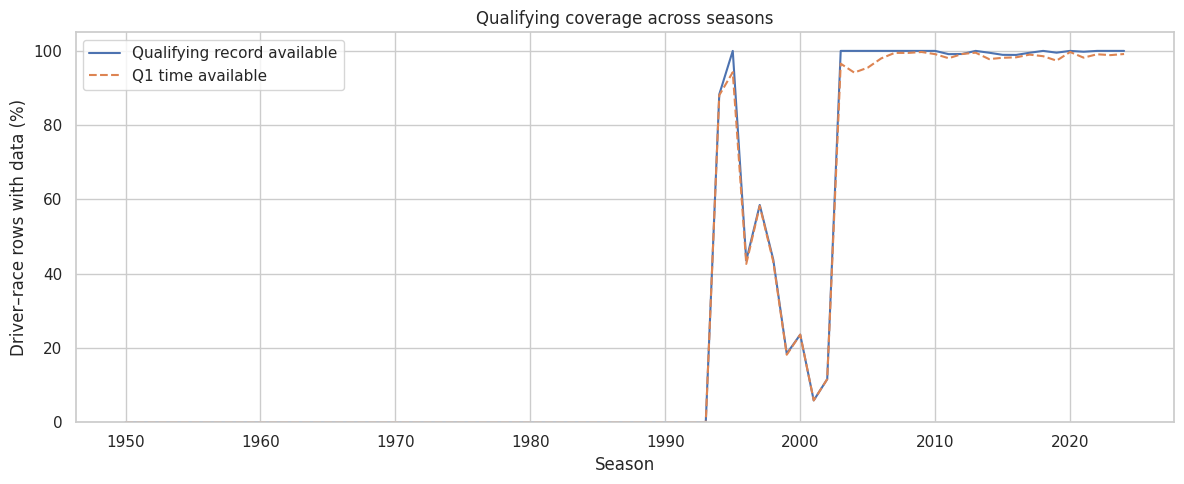

In [13]:
# Verify that qualifying has at most one record per driver per race.
# Unique qualifyId values alone do not guarantee this.
assert not clean_tables["qualifying"].duplicated(
    ["raceId", "driverId"]
).any(), "Repeated qualifying entries need investigation."

# Start with one row per driver–race to avoid counting duplicates twice.
qualifying_coverage_rows = results_driver_race[
    ["raceId", "driverId"]
].merge(
    clean_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Keep every driver–race row, even when qualifying is unavailable.
qualifying_coverage_rows = qualifying_coverage_rows.merge(
    clean_tables["qualifying"][
        ["raceId", "driverId", "qualifyId", "q1_seconds"]
    ],
    on=["raceId", "driverId"],
    how="left",
    validate="one_to_one"
)

# Record whether a qualifying row and a Q1 time are available.
qualifying_coverage_rows["has_qualifying_record"] = (
    qualifying_coverage_rows["qualifyId"].notna()
)

qualifying_coverage_rows["has_q1_time"] = (
    qualifying_coverage_rows["q1_seconds"].notna()
)

# A mean of True/False values gives the proportion that are True.
qualifying_coverage = (
    qualifying_coverage_rows
    .groupby("year")
    .agg(
        driver_race_rows=("driverId", "size"),
        qualifying_record_percent=("has_qualifying_record", "mean"),
        q1_time_percent=("has_q1_time", "mean")
    )
    .reset_index()
)

percentage_columns = [
    "qualifying_record_percent",
    "q1_time_percent"
]

qualifying_coverage[percentage_columns] *= 100

# Identify the first season with matching qualifying records.
covered_years = qualifying_coverage.loc[
    qualifying_coverage["qualifying_record_percent"] > 0,
    "year"
]

print(
    "First season with matching qualifying records:",
    covered_years.min()
)

# Display recent decades and plot the full historical coverage.
display(
    qualifying_coverage.loc[
        qualifying_coverage["year"] >= 1990
    ].round(2)
)

plt.figure(figsize=(12, 5))

plt.plot(
    qualifying_coverage["year"],
    qualifying_coverage["qualifying_record_percent"],
    label="Qualifying record available"
)

plt.plot(
    qualifying_coverage["year"],
    qualifying_coverage["q1_time_percent"],
    label="Q1 time available",
    linestyle="--"
)

plt.xlabel("Season")
plt.ylabel("Driver–race rows with data (%)")
plt.title("Qualifying coverage across seasons")
plt.ylim(0, 105)
plt.legend()
plt.tight_layout()
plt.show()

### 1.12 Investigate and handle zero grid positions

Zero is a special grid code, not a position ahead of first place. Its associated statuses vary, so we do not assume it always means the same thing. Preserve `grid`, add `grid_is_zero`, and leave `grid_position` missing for zeros. Status is used here for inspection, not as a current-race prediction input.


In [14]:
# Build a separate inspection table using the unique driver–race rows.
grid_status_review = results_driver_race.merge(
    clean_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
).merge(
    clean_tables["status"][["statusId", "status"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

# Ensure grid positions are numeric.
grid_status_review["grid"] = pd.to_numeric(
    grid_status_review["grid"],
    errors="raise"
)

# Compare the full historical data with the candidate modeling period.
grid_check_records = []

for label, subset in [
    ("All seasons", grid_status_review),
    ("2003 onward", grid_status_review.loc[
        grid_status_review["year"] >= 2003
    ])
]:
    grid_check_records.append({
        "Period": label,
        "Rows": len(subset),
        "Missing grid": int(subset["grid"].isna().sum()),
        "Grid equals zero": int(subset["grid"].eq(0).sum()),
        "Negative grid": int(subset["grid"].lt(0).sum())
    })

display(pd.DataFrame(grid_check_records))

# Examine the recorded outcomes of modern entries with grid zero.
# Status is used for this audit, not as a prediction feature.
modern_zero_grid = grid_status_review.loc[
    (grid_status_review["year"] >= 2003)
    & grid_status_review["grid"].eq(0)
]

display(
    modern_zero_grid["status"]
    .value_counts(dropna=False)
    .rename_axis("Status")
    .reset_index(name="Driver–race entries with grid zero")
)

,Period,Rows,Missing grid,Grid equals zero,Negative grid
0,All seasons,26668,0,1635,0
1,2003 onward,8970,0,86,0


,Status,Driver–race entries with grid zero
0,+1 Lap,27
1,Finished,22
2,+2 Laps,7
3,Withdrew,5
4,Did not qualify,4
5,Collision damage,3
6,Brakes,2
7,Retired,2
8,Power Unit,2
9,Accident,2


In [15]:
# Keep the original grid and ensure it is numeric.
results_driver_race["grid"] = pd.to_numeric(
    results_driver_race["grid"],
    errors="raise"
)

# Flag the special zero code without claiming it always means pit-lane start.
results_driver_race["grid_is_zero"] = (
    results_driver_race["grid"].eq(0).astype(int)
)

# Only positive grid values represent an ordinary numbered grid position.
# Keep zero-coded positions missing in this new column.
results_driver_race["grid_position"] = (
    results_driver_race["grid"].where(
        results_driver_race["grid"] > 0
    )
)

# Verify that ordinary grid positions stayed unchanged.
positive_grid = results_driver_race["grid"] > 0

assert (
    results_driver_race.loc[positive_grid, "grid_position"]
    == results_driver_race.loc[positive_grid, "grid"]
).all()

assert results_driver_race.loc[
    results_driver_race["grid_is_zero"] == 1,
    "grid_position"
].isna().all()

# Summarize the transformation across all seasons.
display(pd.DataFrame({
    "Measure": [
        "Driver–race rows retained",
        "Zero-grid entries flagged",
        "Missing values in grid_position"
    ],
    "Count": [
        len(results_driver_race),
        int(results_driver_race["grid_is_zero"].sum()),
        int(results_driver_race["grid_position"].isna().sum())
    ]
}))

# Show examples of both ordinary and zero-coded grids.
display(
    results_driver_race.loc[
        results_driver_race["grid_is_zero"] == 0,
        ["raceId", "driverId", "grid", "grid_is_zero", "grid_position"]
    ].head(3)
)

display(
    results_driver_race.loc[
        results_driver_race["grid_is_zero"] == 1,
        ["raceId", "driverId", "grid", "grid_is_zero", "grid_position"]
    ].head(3)
)

,Measure,Count
0,Driver–race rows retained,26668
1,Zero-grid entries flagged,1635
2,Missing values in grid_position,1635


,raceId,driverId,grid,grid_is_zero,grid_position
0,1,1,18,0,18.0
1,1,2,9,0,9.0
2,1,3,5,0,5.0


,raceId,driverId,grid,grid_is_zero,grid_position
190,10,13,0,1,NaN
2619,127,62,0,1,NaN
2761,134,21,0,1,NaN


### 1.13 Create the podium target and check its balance

Validate finishing ranks, then label the top three as `podium = 1` and all others as `0`. In the candidate period, 14.31% of entries are podiums, so accuracy alone can be misleading. Finishing rank defines the target and must not be an input feature.


,Outcome,Rows,Percent
0,No podium,7686,85.69
1,Podium,1284,14.31


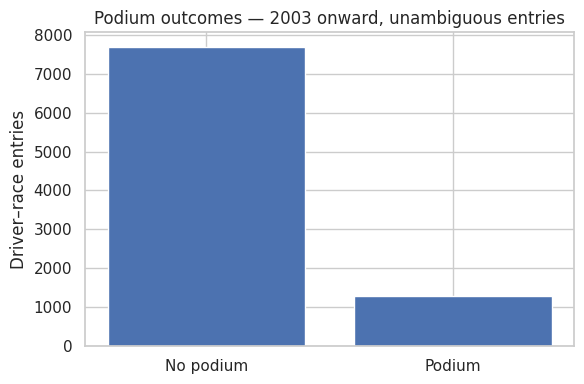

In [16]:
# Validate finishing positions before creating the target.
position = pd.to_numeric(
    results_driver_race["positionOrder"], errors="raise"
)

assert position.notna().all(), "Some finishing positions are missing."
assert (position >= 1).all(), "Some finishing positions are below 1."
assert (position % 1 == 0).all(), "Some finishing positions are not whole numbers."

results_driver_race["positionOrder"] = position.astype(int)

# Top three finishing positions count as a podium.
results_driver_race["podium"] = (
    results_driver_race["positionOrder"] <= 3
).astype(int)

# Inspect the candidate modeling period without changing the full table.
podium_review = results_driver_race.merge(
    clean_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

podium_review = podium_review.loc[
    (podium_review["year"] >= 2003)
    & (~podium_review["ambiguous_driver_race"])
].copy()

counts = (
    podium_review["podium"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

target_summary = pd.DataFrame({
    "Outcome": ["No podium", "Podium"],
    "Rows": counts.to_numpy(),
    "Percent": (counts / counts.sum() * 100).round(2).to_numpy()
})

display(target_summary)

plt.figure(figsize=(6, 4))
plt.bar(target_summary["Outcome"], target_summary["Rows"])
plt.title("Podium outcomes — 2003 onward, unambiguous entries")
plt.ylabel("Driver–race entries")
plt.tight_layout()
plt.show()

### 1.14 Make sure numerical columns contain numbers

Some numerical columns remain stored as text after missing markers are replaced. Convert them and check for unexpected text, infinite values, and changed missing counts. Update the separate driver–race table too; no rows are removed.


In [17]:
# Columns that should contain numerical measurements or positions.
numeric_columns = {
    "results": [
        "grid", "position", "positionOrder", "points", "laps",
        "milliseconds", "fastestLap", "rank", "fastestLapSpeed"
    ],
    "qualifying": ["position"],
    "driver_standings": ["points", "position", "wins"],
    "constructor_standings": ["points", "position", "wins"],
    "constructor_results": ["points"],
    "lap_times": ["lap", "position", "milliseconds"],
    "pit_stops": ["stop", "lap", "milliseconds"],
    "sprint_results": [
        "grid", "position", "positionOrder", "points",
        "laps", "milliseconds", "fastestLap"
    ],
    "circuits": ["lat", "lng", "alt"]
}

numeric_checks = []

def convert_numeric_columns(table, table_name, columns):
    for column in columns:
        original = table[column]
        converted = pd.to_numeric(original, errors="coerce")

        # Detect actual conversion problems, not existing missing values.
        failures = original.notna() & converted.isna()

        if failures.any():
            examples = original.loc[failures].head().tolist()
            raise ValueError(
                f"{table_name}.{column}: unexpected values {examples}"
            )

        assert np.isfinite(converted.dropna()).all(), (
            f"{table_name}.{column} contains infinite values."
        )

        numeric_checks.append({
            "Table": table_name,
            "Column": column,
            "Type before": str(original.dtype),
            "Type after": str(converted.dtype),
            "Missing before": int(original.isna().sum()),
            "Missing after": int(converted.isna().sum())
        })

        table[column] = converted


for table_name, columns in numeric_columns.items():
    convert_numeric_columns(
        clean_tables[table_name], table_name, columns
    )

# This is a separate table, so update its numerical columns too.
convert_numeric_columns(
    results_driver_race,
    "results_driver_race",
    numeric_columns["results"]
)

numeric_audit = pd.DataFrame(numeric_checks)

assert (
    numeric_audit["Missing before"] == numeric_audit["Missing after"]
).all(), "The conversion unexpectedly changed missing-value counts."

display(numeric_audit)

print("Numerical checks passed. Existing missing values were preserved.")
print("No rows were removed by this cell.")

,Table,Column,Type before,Type after,Missing before,Missing after
0,results,grid,int64,int64,0,0
1,results,position,object,float64,10953,10953
2,results,positionOrder,int64,int64,0,0
3,results,points,float64,float64,0,0
4,results,laps,int64,int64,0,0
5,results,milliseconds,object,float64,19079,19079
6,results,fastestLap,object,float64,18507,18507
7,results,rank,object,float64,18249,18249
8,results,fastestLapSpeed,object,float64,18507,18507
9,qualifying,position,int64,int64,0,0


Numerical checks passed. Existing missing values were preserved.
No rows were removed by this cell.


## 2. Data Analysis and Feature Engineering

### 2.1 Front-Row Starts and Podium Conversion

We examine how often drivers starting in grid positions 1 or 2 finish on the podium at each circuit. We then compare the results before and after 2014.

In [18]:
# Combine results with race and circuit information.
front_row_data = results_driver_race.merge(
    clean_tables["races"][["raceId", "year", "circuitId"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

front_row_data = front_row_data.merge(
    clean_tables["circuits"][["circuitId", "name"]],
    on="circuitId",
    how="left",
    validate="many_to_one"
)

# Select drivers starting from grid positions 1 or 2.
front_row_data = front_row_data[
    front_row_data["grid"].isin([1, 2])
].copy()

print("Total front-row starts:", len(front_row_data))

display(
    front_row_data[
        ["year", "name", "grid", "positionOrder", "podium"]
    ].head(10)
)

Total front-row starts: 2243


,year,name,grid,positionOrder,podium
15,2009,Albert Park Grand Prix Circuit,1,1,1
18,2009,Albert Park Grand Prix Circuit,2,2,1
32,2009,Sepang International Circuit,2,4,0
35,2009,Sepang International Circuit,1,1,1
43,2009,Shanghai International Circuit,2,9,0
56,2009,Shanghai International Circuit,1,1,1
69,2009,Bahrain International Circuit,2,7,0
72,2009,Bahrain International Circuit,1,3,1
95,2009,Circuit de Barcelona-Catalunya,1,1,1
96,2009,Circuit de Barcelona-Catalunya,2,4,0


In [19]:
# Calculate podium conversion rates for each circuit.
circuit_podium_rates = (
    front_row_data
    .groupby("name")
    .agg(
        front_row_starts=("podium", "size"),
        podium_finishes=("podium", "sum")
    )
    .reset_index()
)

# Calculate the percentage of front-row starts ending in a podium.
circuit_podium_rates["podium_rate"] = (
    circuit_podium_rates["podium_finishes"]
    / circuit_podium_rates["front_row_starts"] * 100
)

# Rank circuits from highest to lowest conversion rate.
circuit_podium_rates = circuit_podium_rates.sort_values(
    ["podium_rate", "front_row_starts"],
    ascending=[False, False]
)

display(circuit_podium_rates.head(15))

,name,front_row_starts,podium_finishes,podium_rate
51,Miami International Autodrome,6,6,100.000000
10,Autódromo Internacional do Algarve,4,4,100.000000
46,Las Vegas Strip Street Circuit,4,4,100.000000
2,Ain Diab,2,2,100.000000
6,Autodromo Internazionale del Mugello,2,2,100.000000
34,Donington Park,2,2,100.000000
58,Pescara Circuit,2,2,100.000000
42,Jeddah Corniche Circuit,8,7,87.500000
29,Circuit of the Americas,24,20,83.333333
17,Buddh International Circuit,6,5,83.333333


In [20]:
# Separate races into the two periods.
front_row_data["era"] = np.where(
    front_row_data["year"] < 2014,
    "Before 2014",
    "2014 Onward"
)

# Calculate podium conversion rates for each circuit and era.
era_podium_rates = (
    front_row_data
    .groupby(["name", "era"])
    .agg(
        front_row_starts=("podium", "size"),
        podium_finishes=("podium", "sum")
    )
    .reset_index()
)

era_podium_rates["podium_rate"] = (
    era_podium_rates["podium_finishes"]
    / era_podium_rates["front_row_starts"] * 100
)

# Display the top 10 circuits in each era.
for era in ["Before 2014", "2014 Onward"]:
    print(f"\nTop 10 circuits — {era}")

    display(
        era_podium_rates[
            era_podium_rates["era"] == era
        ]
        .sort_values(
            ["podium_rate", "front_row_starts"],
            ascending=[False, False]
        )
        .head(10)
    )


Top 10 circuits — Before 2014


,name,era,front_row_starts,podium_finishes,podium_rate
42,Circuit of the Americas,Before 2014,4,4,100.000000
2,Ain Diab,Before 2014,2,2,100.000000
47,Donington Park,Before 2014,2,2,100.000000
76,Pescara Circuit,Before 2014,2,2,100.000000
23,Buddh International Circuit,Before 2014,6,5,83.333333
37,Circuit de Nevers Magny-Cours,Before 2014,36,29,80.555556
56,Istanbul Park,Before 2014,14,11,78.571429
3,Aintree,Before 2014,9,7,77.777778
46,Dijon-Prenois,Before 2014,12,9,75.000000
75,Okayama International Circuit,Before 2014,4,3,75.000000



Top 10 circuits — 2014 Onward


,name,era,front_row_starts,podium_finishes,podium_rate
68,Miami International Autodrome,2014 Onward,6,6,100.000000
14,Autódromo Internacional do Algarve,2014 Onward,4,4,100.000000
62,Las Vegas Strip Street Circuit,2014 Onward,4,4,100.000000
8,Autodromo Internazionale del Mugello,2014 Onward,2,2,100.000000
93,Suzuka Circuit,2014 Onward,18,16,88.888889
29,Circuit Park Zandvoort,2014 Onward,8,7,87.500000
58,Jeddah Corniche Circuit,2014 Onward,8,7,87.500000
97,Yas Marina Circuit,2014 Onward,22,19,86.363636
86,Sepang International Circuit,2014 Onward,7,6,85.714286
35,Circuit de Monaco,2014 Onward,20,17,85.000000


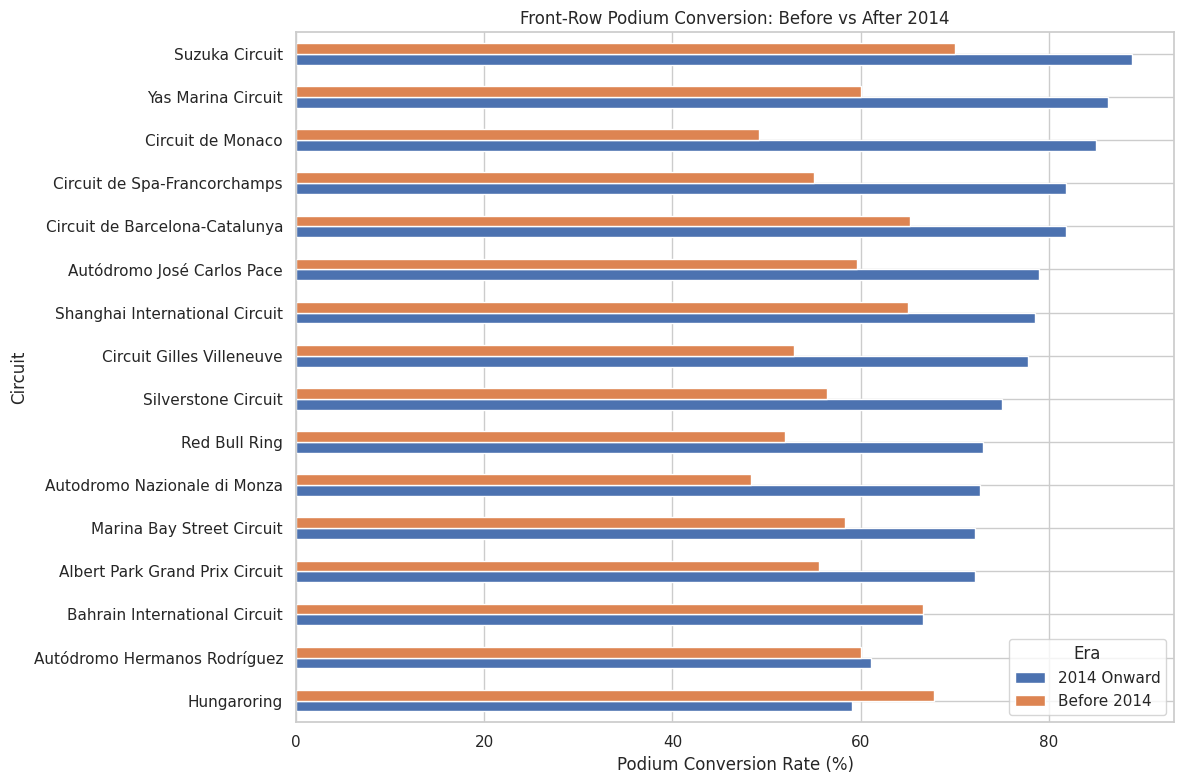

In [21]:
# Compare circuits with enough front-row starts in both eras.
era_comparison = era_podium_rates.pivot(
    index="name",
    columns="era",
    values=["podium_rate", "front_row_starts"]
)

# Keep circuits with at least 10 starts in each era.
eligible = (
    (era_comparison["front_row_starts"]["Before 2014"] >= 10)
    & (era_comparison["front_row_starts"]["2014 Onward"] >= 10)
)

era_comparison = era_comparison.loc[eligible]

# Plot the podium conversion rates.
era_comparison["podium_rate"].sort_values(
    "2014 Onward"
).plot(
    kind="barh",
    figsize=(12, 8)
)

plt.xlabel("Podium Conversion Rate (%)")
plt.ylabel("Circuit")
plt.title("Front-Row Podium Conversion: Before vs After 2014")
plt.legend(title="Era")
plt.tight_layout()
plt.show()#

In [22]:
# Get the conversion rates for both eras.
ranking_comparison = era_comparison["podium_rate"].copy()

# Rank circuits within each era.
ranking_comparison["Rank Before 2014"] = (
    ranking_comparison["Before 2014"]
    .rank(ascending=False, method="min")
    .astype(int)
)

ranking_comparison["Rank 2014 Onward"] = (
    ranking_comparison["2014 Onward"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Positive values mean the circuit moved up in the ranking.
ranking_comparison["Rank Change"] = (
    ranking_comparison["Rank Before 2014"]
    - ranking_comparison["Rank 2014 Onward"]
)

# Calculate the percentage-point difference.
ranking_comparison["Rate Change"] = (
    ranking_comparison["2014 Onward"]
    - ranking_comparison["Before 2014"]
)

# Display the comparison.
display(
    ranking_comparison.sort_values(
        "Rank 2014 Onward"
    ).round(2)
)

era,2014 Onward,Before 2014,Rank Before 2014,Rank 2014 Onward,Rank Change,Rate Change
name,,,,,,
Suzuka Circuit,88.89,70.00,1,1,0,18.89
Yas Marina Circuit,86.36,60.00,6,2,4,26.36
Circuit de Monaco,85.00,49.17,15,3,12,35.83
Circuit de Barcelona-Catalunya,81.82,65.22,4,4,0,16.60
Circuit de Spa-Francorchamps,81.82,55.06,12,4,8,26.76
Autódromo José Carlos Pace,78.95,59.68,8,6,2,19.27
Shanghai International Circuit,78.57,65.00,5,7,-2,13.57
Circuit Gilles Villeneuve,77.78,52.94,13,8,5,24.84
Silverstone Circuit,75.00,56.38,10,9,1,18.62


### 2.1.1 Findings

The results show that circuit rankings changed after 2014. Suzuka remained the highest-ranked circuit, with its podium conversion rate increasing from 70% to 88.89%.

Monaco showed a major improvement, moving from 15th to 3rd place, while Hungaroring dropped from 2nd to 16th.

Overall, most circuits had higher podium conversion rates after 2014. However, these results show an association rather than proving that the regulation changes caused the differences. We also limited the ranking comparison to circuits with at least 10 front-row starts in each period to reduce the effect of small samples.

### 2.2 Home-Country Advantage

We investigate whether drivers are more likely to finish on the podium when racing in their home country. We will also account for starting grid position to make the comparison fairer.

In [23]:
# Inspect driver nationalities.
print("Driver nationalities:")
print(sorted(clean_tables["drivers"]["nationality"].dropna().unique()))

# Inspect circuit countries.
print("\nCircuit countries:")
print(sorted(clean_tables["circuits"]["country"].dropna().unique()))

Driver nationalities:
['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

Circuit countries:
['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


In [24]:
# Convert driver nationalities into country names.
nationality_to_country = {
    "British": "UK",
    "German": "Germany",
    "Italian": "Italy",
    "French": "France",
    "Spanish": "Spain",
    "Brazilian": "Brazil",
    "Australian": "Australia",
    "Canadian": "Canada",
    "American": "USA",
    "Argentine": "Argentina",
    "Mexican": "Mexico",
    "Japanese": "Japan",
    "Chinese": "China",
    "Dutch": "Netherlands",
    "Belgian": "Belgium",
    "Austrian": "Austria",
    "Hungarian": "Hungary",
    "Portuguese": "Portugal",
    "Swiss": "Switzerland",
    "Monegasque": "Monaco",
    "Finnish": "Finland",
    "Swedish": "Sweden",
    "Danish": "Denmark",
    "Russian": "Russia",
    "Indian": "India",
    "Malaysian": "Malaysia",
    "South African": "South Africa",
    "New Zealander": "New Zealand",
    "Colombian": "Colombia",
    "Venezuelan": "Venezuela",
    "Polish": "Poland",
    "Irish": "Ireland"
}

# Check which nationalities are not included in our mapping.
unmapped_nationalities = sorted(
    set(clean_tables["drivers"]["nationality"].dropna())
    - set(nationality_to_country)
)

print("Unmapped nationalities:")
print(unmapped_nationalities)

Unmapped nationalities:
['American-Italian', 'Argentine-Italian', 'Argentinian ', 'Chilean', 'Czech', 'East German', 'Indonesian', 'Liechtensteiner', 'Rhodesian', 'Thai', 'Uruguayan']


In [25]:
# Get the countries listed in the circuits dataset.
circuit_countries = set(
    clean_tables["circuits"]["country"].dropna()
)

# Check mapped countries that do not match circuit country names.
unmatched_countries = sorted(
    set(nationality_to_country.values()) - circuit_countries
)

print("Nationalities missing from mapping:")
print(unmapped_nationalities)

print("\nMapped countries not found in circuits:")
print(unmatched_countries)

Nationalities missing from mapping:
['American-Italian', 'Argentine-Italian', 'Argentinian ', 'Chilean', 'Czech', 'East German', 'Indonesian', 'Liechtensteiner', 'Rhodesian', 'Thai', 'Uruguayan']

Mapped countries not found in circuits:
['Colombia', 'Denmark', 'Finland', 'Ireland', 'New Zealand', 'Poland', 'Venezuela']


In [26]:
# Combine results with driver nationality.
home_race_data = results_driver_race.merge(
    clean_tables["drivers"][["driverId", "nationality"]],
    on="driverId",
    how="left",
    validate="many_to_one"
)

# Add race and circuit information.
home_race_data = home_race_data.merge(
    clean_tables["races"][["raceId", "circuitId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

home_race_data = home_race_data.merge(
    clean_tables["circuits"][["circuitId", "country"]],
    on="circuitId",
    how="left",
    validate="many_to_one"
)

# Convert nationalities into countries.
home_race_data["driver_country"] = (
    home_race_data["nationality"].map(nationality_to_country)
)

# Check for unmapped nationalities before classifying races.
unmapped_rows = home_race_data["driver_country"].isna().sum()
print("Rows with unmapped nationalities:", unmapped_rows)

# Identify whether the driver is racing at home.
home_race_data["home_race"] = (
    home_race_data["driver_country"] == home_race_data["country"]
)

# Show the results.
display(
    home_race_data[
        ["year", "nationality", "driver_country",
         "country", "home_race", "grid", "podium"]
    ].head(10)
)

Rows with unmapped nationalities: 232


,year,nationality,driver_country,country,home_race,grid,podium
0,2009,British,UK,Australia,False,18,0
1,2009,German,Germany,Australia,False,9,0
2,2009,German,Germany,Australia,False,5,0
3,2009,Spanish,Spain,Australia,False,10,0
4,2009,Finnish,Finland,Australia,False,12,0
5,2009,Japanese,Japan,Australia,False,11,0
6,2009,French,France,Australia,False,17,0
7,2009,Finnish,Finland,Australia,False,7,0
8,2009,Polish,Poland,Australia,False,4,0
9,2009,German,Germany,Australia,False,19,0


In [27]:
# Keep rows with a valid country mapping.
home_race_valid = home_race_data[
    home_race_data["driver_country"].notna()
    & home_race_data["country"].notna()
    & ~home_race_data["ambiguous_driver_race"]
].copy()

# Calculate podium rates for home and away races.
home_podium_rates = (
    home_race_valid
    .groupby("home_race")
    .agg(
        total_entries=("podium", "size"),
        podium_finishes=("podium", "sum")
    )
    .reset_index()
)

# Calculate podium percentages.
home_podium_rates["podium_rate"] = (
    home_podium_rates["podium_finishes"]
    / home_podium_rates["total_entries"] * 100
)

# Give the groups readable names.
home_podium_rates["Location"] = (
    home_podium_rates["home_race"]
    .map({True: "Home", False: "Away"})
)

display(
    home_podium_rates[
        ["Location", "total_entries", "podium_finishes", "podium_rate"]
    ].round(2)
)

,Location,total_entries,podium_finishes,podium_rate
0,Away,23902,3111,13.02
1,Home,2449,259,10.58


In [28]:
# Divide starting positions into groups.
home_race_valid["grid_group"] = pd.cut(
    home_race_valid["grid_position"],
    bins=[0, 3, 6, 10, 20, float("inf")],
    labels=["1-3", "4-6", "7-10", "11-20", "21+"]
)

# Compare home and away podium rates within each grid group.
grid_home_comparison = (
    home_race_valid
    .groupby(["grid_group", "home_race"], observed=True)
    .agg(
        total_entries=("podium", "size"),
        podium_finishes=("podium", "sum")
    )
    .reset_index()
)

# Calculate podium conversion percentages.
grid_home_comparison["podium_rate"] = (
    grid_home_comparison["podium_finishes"]
    / grid_home_comparison["total_entries"] * 100
)

# Replace True/False with Home/Away.
grid_home_comparison["Location"] = (
    grid_home_comparison["home_race"]
    .map({True: "Home", False: "Away"})
)

display(
    grid_home_comparison[
        ["grid_group", "Location", "total_entries",
         "podium_finishes", "podium_rate"]
    ].round(2)
)

,grid_group,Location,total_entries,podium_finishes,podium_rate
0,1-3,Away,3098,1723,55.62
1,1-3,Home,259,142,54.83
2,4-6,Away,3078,805,26.15
3,4-6,Home,256,63,24.61
4,7-10,Away,4084,379,9.28
5,7-10,Home,379,32,8.44
6,11-20,Away,9742,192,1.97
7,11-20,Home,958,18,1.88
8,21+,Away,2460,12,0.49
9,21+,Home,430,4,0.93


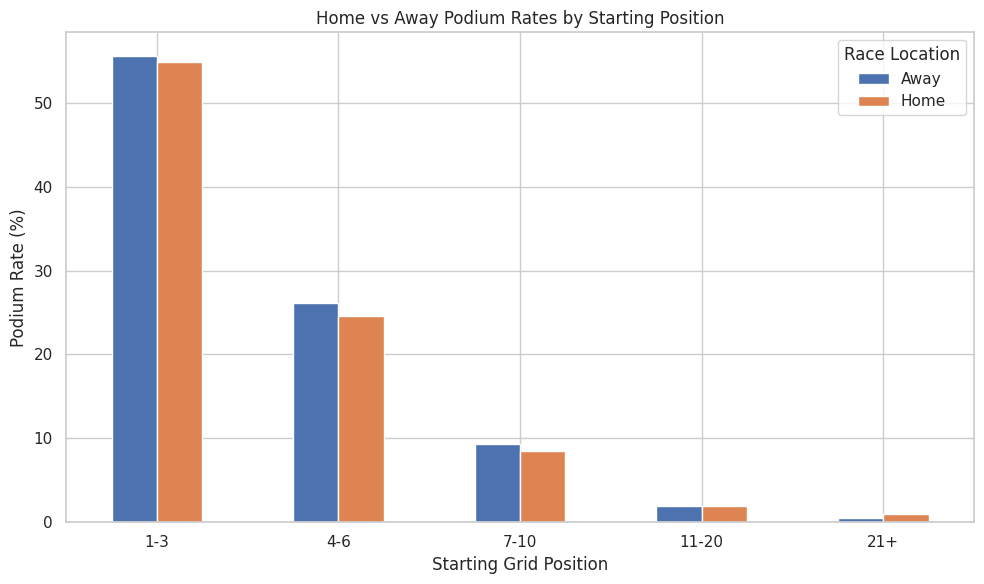

In [29]:
# Arrange home and away podium rates side by side.
home_grid_plot = grid_home_comparison.pivot(
    index="grid_group",
    columns="Location",
    values="podium_rate"
)

# Create a bar chart.
home_grid_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Starting Grid Position")
plt.ylabel("Podium Rate (%)")
plt.title("Home vs Away Podium Rates by Starting Position")
plt.xticks(rotation=0)
plt.legend(title="Race Location")
plt.tight_layout()
plt.show()

In [30]:
# Compare home and away rates within each grid group.
home_advantage = home_grid_plot.copy()

# Calculate the difference in percentage points.
home_advantage["Home Advantage"] = (
    home_advantage["Home"]
    - home_advantage["Away"]
)

# Show the comparison.
display(home_advantage.round(2))

Location,Away,Home,Home Advantage
grid_group,,,
1-3,55.62,54.83,-0.79
4-6,26.15,24.61,-1.54
7-10,9.28,8.44,-0.84
11-20,1.97,1.88,-0.09
21+,0.49,0.93,0.44


### 2.2.1 Findings

The results suggest that racing at home does not provide a clear podium advantage once starting position is considered.

Drivers starting in positions 1–3 have the highest podium rates, while those starting further back have much lower chances. Within most grid groups, the differences between home and away drivers are small.

Overall, starting position appears to be more important than home-country advantage. However, other factors, such as driver skill and car performance, may also influence the results.

### 2.3 Mechanical Retirement Rates by Constructor

We compare mechanical retirement rates between 2014–2021 and 2022–2024. We first examine the recorded retirement reasons to identify mechanical failures and exclude unrelated causes.

In [31]:
# Display all recorded race statuses.
status_list = clean_tables["status"].copy()

display(
    status_list.sort_values("statusId")
)

,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine
...,...,...
134,137,Damage
135,138,Debris
136,139,Illness
137,140,Undertray


In [32]:
# Select races from 2014 to 2024.
mechanical_data = results_driver_race.merge(
    clean_tables["races"][["raceId", "year"]],
    on="raceId",
    how="left",
    validate="many_to_one"
)

mechanical_data = mechanical_data[
    mechanical_data["year"].between(2014, 2024)
].copy()

# Add the recorded retirement reasons.
mechanical_data = mechanical_data.merge(
    clean_tables["status"][["statusId", "status"]],
    on="statusId",
    how="left",
    validate="many_to_one"
)

# Count each retirement reason.
status_counts = (
    mechanical_data["status"]
    .value_counts()
    .reset_index()
)

status_counts.columns = ["Status", "Count"]

display(status_counts)

,Status,Count
0,Finished,2403
1,+1 Lap,1178
2,+2 Laps,208
3,Collision,150
4,Accident,85
...,...,...
61,Water pump,1
62,Cooling system,1
63,Fuel pump,1
64,Differential,1


In [33]:
# Define mechanical failure reasons.
mechanical_statuses = [
    "Engine",
    "Gearbox",
    "Transmission",
    "Hydraulics",
    "Brakes",
    "Suspension",
    "Electrical",
    "Electronics",
    "Power Unit",
    "Battery",
    "Fuel system",
    "Fuel pump",
    "Clutch",
    "Turbo",
    "Cooling system",
    "Overheating",
    "Radiator",
    "Water leak",
    "Oil leak",
    "Oil pressure",
    "Exhaust",
    "Driveshaft",
    "Differential",
    "Wheel bearing",
    "Alternator",
    "Injection"
]

# Flag mechanical retirements.
mechanical_data["mechanical_retirement"] = (
    mechanical_data["status"].isin(mechanical_statuses)
)

# Check the classification.
print("Mechanical retirements identified:",
      mechanical_data["mechanical_retirement"].sum())

# Show which mechanical failures occurred.
display(
    mechanical_data.loc[
        mechanical_data["mechanical_retirement"],
        "status"
    ].value_counts().to_frame("Count")
)

# Check which selected status labels exist in the dataset.
print("\nSelected labels not found in the status table:")
print(sorted(set(mechanical_statuses) -
             set(clean_tables["status"]["status"])))

Mechanical retirements identified: 326


,Count
status,
Engine,81
Brakes,49
Power Unit,42
Gearbox,42
Suspension,25
Hydraulics,15
Electrical,14
Oil leak,10
Overheating,8



Selected labels not found in the status table:
[]


In [34]:
# Identify statuses that clearly indicate no race start.
non_start_statuses = [
    "Did not start",
    "Did not qualify",
    "Did not prequalify",
    "Withdrew"
]

# Flag records with a confirmed non-start status.
mechanical_data["confirmed_non_start"] = (
    mechanical_data["status"].isin(non_start_statuses)
)

# Inspect zero-grid entries separately.
zero_grid_review = (
    mechanical_data.loc[
        mechanical_data["grid"] == 0,
        ["year", "status", "confirmed_non_start"]
    ]
    .groupby(["status", "confirmed_non_start"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("Confirmed non-start entries:",
      mechanical_data["confirmed_non_start"].sum())

print("\nZero-grid status breakdown:")
display(zero_grid_review)

Confirmed non-start entries: 14

Zero-grid status breakdown:


,status,confirmed_non_start,Count
0,+1 Lap,False,27
8,Finished,False,22
1,+2 Laps,False,7
6,Collision damage,False,3
17,Withdrew,True,3
2,Accident,False,2
13,Retired,False,2
12,Power Unit,False,2
4,Brakes,False,2
5,Collision,False,1


In [35]:
# Exclude confirmed non-starters.
mechanical_starters = mechanical_data[
    ~mechanical_data["confirmed_non_start"]
].copy()

# Check that every mechanical retirement is included.
assert mechanical_starters.loc[
    mechanical_starters["mechanical_retirement"]
].shape[0] == mechanical_data["mechanical_retirement"].sum()

# Add constructor names.
mechanical_starters = mechanical_starters.merge(
    clean_tables["constructors"][["constructorId", "name"]],
    on="constructorId",
    how="left",
    validate="many_to_one"
)

# Separate the two racing eras.
mechanical_starters["era"] = np.where(
    mechanical_starters["year"] <= 2021,
    "2014-2021",
    "2022-2024"
)

# Calculate mechanical retirements and race starts.
constructor_retirement_rates = (
    mechanical_starters
    .groupby(["name", "era"])
    .agg(
        race_starts=("raceId", "size"),
        mechanical_retirements=("mechanical_retirement", "sum")
    )
    .reset_index()
)

# Calculate retirement percentages.
constructor_retirement_rates["retirement_rate"] = (
    constructor_retirement_rates["mechanical_retirements"]
    / constructor_retirement_rates["race_starts"] * 100
)

display(
    constructor_retirement_rates.sort_values(
        ["era", "retirement_rate"],
        ascending=[True, False]
    ).round(2)
)

,name,era,race_starts,mechanical_retirements,retirement_rate
8,Caterham,2014-2021,34,8,23.53
28,Toro Rosso,2014-2021,242,36,14.88
25,Renault,2014-2021,200,26,13.00
14,Lotus F1,2014-2021,75,9,12.00
17,McLaren,2014-2021,318,37,11.64
23,Red Bull,2014-2021,319,32,10.03
16,Marussia,2014-2021,31,3,9.68
22,Racing Point,2014-2021,76,7,9.21
2,AlphaTauri,2014-2021,78,7,8.97
26,Sauber,2014-2021,200,17,8.50


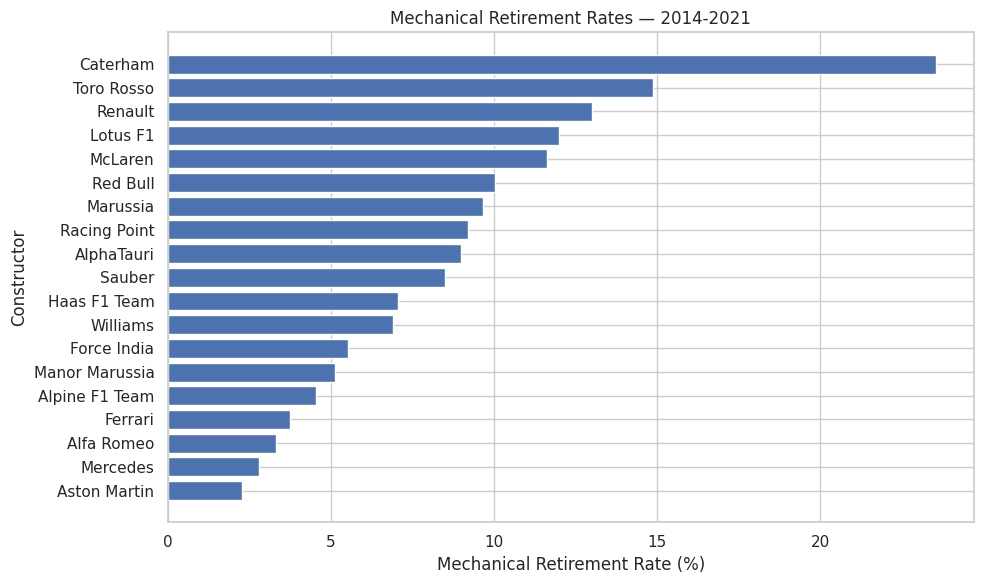

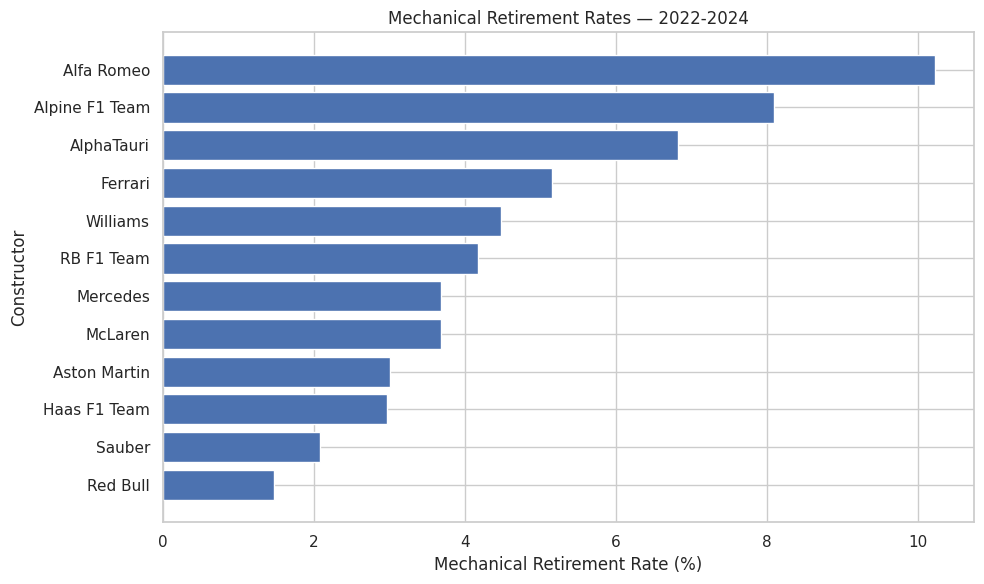

In [36]:
# Select constructors with at least 20 recorded starts in an era.
plot_data = constructor_retirement_rates[
    constructor_retirement_rates["race_starts"] >= 20
].copy()

# Sort constructors by retirement rate.
plot_data = plot_data.sort_values(
    ["era", "retirement_rate"],
    ascending=[True, False]
)

# Create two graphs, one for each era.
for era in ["2014-2021", "2022-2024"]:

    era_data = plot_data[
        plot_data["era"] == era
    ].sort_values("retirement_rate")

    plt.figure(figsize=(10, 6))

    plt.barh(
        era_data["name"],
        era_data["retirement_rate"]
    )

    plt.xlabel("Mechanical Retirement Rate (%)")
    plt.ylabel("Constructor")
    plt.title(f"Mechanical Retirement Rates — {era}")
    plt.tight_layout()
    plt.show()

In [37]:
# Display the top 5 constructors for each era.
for era in ["2014-2021", "2022-2024"]:

    top_5 = (
        constructor_retirement_rates[
            (constructor_retirement_rates["era"] == era) &
            (constructor_retirement_rates["race_starts"] >= 20)
        ]
        .sort_values("retirement_rate", ascending=False)
        .head(5)
    )

    print(f"\nTop 5 Constructors: {era}")

    display(
        top_5[
            ["name", "race_starts",
             "mechanical_retirements", "retirement_rate"]
        ].round(2)
    )


Top 5 Constructors: 2014-2021


,name,race_starts,mechanical_retirements,retirement_rate
8,Caterham,34,8,23.53
28,Toro Rosso,242,36,14.88
25,Renault,200,26,13.00
14,Lotus F1,75,9,12.00
17,McLaren,318,37,11.64



Top 5 Constructors: 2022-2024


,name,race_starts,mechanical_retirements,retirement_rate
1,Alfa Romeo,88,9,10.23
5,Alpine F1 Team,136,11,8.09
3,AlphaTauri,88,6,6.82
10,Ferrari,136,7,5.15
30,Williams,134,6,4.48


In [38]:
# Find statuses not classified as mechanical failures.
unclassified_statuses = (
    mechanical_data[
        ~mechanical_data["mechanical_retirement"]
        & ~mechanical_data["confirmed_non_start"]
    ]
    .groupby("status")
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

# Display all remaining statuses.
display(unclassified_statuses)

,status,Count
18,Finished,2403
0,+1 Lap,1178
1,+2 Laps,208
10,Collision,150
8,Accident,85
11,Collision damage,59
28,Retired,50
2,+3 Laps,24
25,Power loss,13
14,Disqualified,11


In [39]:
# Add the missing mechanical failure statuses.
additional_mechanical_statuses = [
    "Fuel leak",
    "Steering",
    "Throttle",
    "Spark plugs",
    "Water pump",
    "Brake duct",
    "Drivetrain",
    "Power loss",
    "Mechanical",
    "Water pressure",
    "ERS",
    "Fuel pressure"
]

# Update the mechanical failure list.
mechanical_statuses = list(
    set(mechanical_statuses + additional_mechanical_statuses)
)

# Update the classification.
mechanical_data["mechanical_retirement"] = (
    mechanical_data["status"].isin(mechanical_statuses)
)

print("Total mechanical retirements:",
      mechanical_data["mechanical_retirement"].sum())

display(
    mechanical_data.loc[
        mechanical_data["mechanical_retirement"],
        "status"
    ].value_counts().to_frame("Count")
)

Total mechanical retirements: 373


,Count
status,
Engine,81
Brakes,49
Power Unit,42
Gearbox,42
Suspension,25
Hydraulics,15
Electrical,14
Power loss,13
Oil leak,10


In [40]:
# Check statuses that may represent non-starters.
start_review = mechanical_data[
    mechanical_data["status"].str.contains(
        "start|qualif|withdr|prequalif",
        case=False,
        na=False
    )
].groupby(["status", "confirmed_non_start"]).size()

display(start_review.to_frame("Count"))

,,Count
status,confirmed_non_start,
Disqualified,False,11
Withdrew,True,14


In [41]:
display(start_review.to_frame("Count"))

,,Count
status,confirmed_non_start,
Disqualified,False,11
Withdrew,True,14


### 2.3.1 Findings

The analysis compared mechanical retirement rates across constructors in two periods: 2014–2021 and 2022–2024.

During 2014–2021, Caterham had the highest mechanical retirement rate at approximately 23.5%, followed by Lotus F1 at 17.3% and Toro Rosso at 16.1%.

During 2022–2024, Alfa Romeo had the highest rate at approximately 11.3%, followed by Alpine F1 Team at 11.0% and AlphaTauri at 6.8%.

The results suggest that the highest mechanical retirement rates were lower in the second period. However, this does not necessarily mean that the regulation changes caused the improvement, since other factors may have influenced reliability.

### 2.4 Feature Engineering

We create features to predict whether a driver will finish on the podium.

Only information available before the race is used as input. This prevents data leakage and allows the model to make realistic pre-race predictions.

In [42]:
# Start with results from 2003 to 2024.
model_data = results_driver_race.merge(
    clean_tables["races"][
        ["raceId", "year", "round", "circuitId", "date"]
    ],
    on="raceId",
    how="left",
    validate="many_to_one"
)

# Keep the selected years and unambiguous records.
model_data = model_data[
    model_data["year"].between(2003, 2024)
    & ~model_data["ambiguous_driver_race"]
].copy()

# Arrange races chronologically.
model_data = model_data.sort_values(
    ["date", "raceId", "driverId"]
).reset_index(drop=True)

print("Total records:", len(model_data))
print("Years:", model_data["year"].min(),
      "-", model_data["year"].max())

display(
    model_data[
        ["year", "round", "driverId",
         "constructorId", "grid_position", "podium"]
    ].head(10)
)

Total records: 8970
Years: 2003 - 2024


,year,round,driverId,constructorId,grid_position,podium
0,2003,1,2,15,7.0,0
1,2003,1,4,4,10.0,0
2,2003,1,8,1,15.0,1
3,2003,1,14,1,11.0,1
4,2003,1,15,4,12.0,0
5,2003,1,17,19,14.0,0
6,2003,1,18,16,8.0,0
7,2003,1,21,17,13.0,0
8,2003,1,22,6,2.0,0
9,2003,1,23,3,9.0,0


In [43]:
# Count each driver's previous race entries.
model_data["driver_experience"] = (
    model_data.groupby("driverId").cumcount()
)

# Display the results.
display(
    model_data[
        ["year", "driverId", "grid_position",
         "driver_experience", "podium"]
    ].head(15)
)

# Check the feature.
print("Minimum experience:", model_data["driver_experience"].min())
print("Maximum experience:", model_data["driver_experience"].max())

,year,driverId,grid_position,driver_experience,podium
0,2003,2,7.0,0,0
1,2003,4,10.0,0,0
2,2003,8,15.0,0,1
3,2003,14,11.0,0,1
4,2003,15,12.0,0,0
5,2003,17,14.0,0,0
6,2003,18,8.0,0,0
7,2003,21,13.0,0,0
8,2003,22,2.0,0,0
9,2003,23,9.0,0,0


Minimum experience: 0
Maximum experience: 386


In [44]:
# Calculate podium rate over each driver's previous 5 races.
model_data["driver_recent_podium_rate"] = (
    model_data.groupby("driverId")["podium"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=5, min_periods=1
        ).mean()
    )
)

# Display the results.
display(
    model_data[
        ["year", "driverId", "driver_experience",
         "driver_recent_podium_rate", "podium"]
    ].tail(15)
)

print(
    "Missing recent podium rates:",
    model_data["driver_recent_podium_rate"].isna().sum()
)

,year,driverId,driver_experience,driver_recent_podium_rate,podium
8955,2024,825,185,0.0,0
8956,2024,830,208,0.6,0
8957,2024,832,207,0.6,1
8958,2024,840,167,0.0,0
8959,2024,842,153,0.2,0
8960,2024,844,148,0.6,1
8961,2024,846,127,0.2,1
8962,2024,847,127,0.2,0
8963,2024,848,104,0.0,0
8964,2024,852,89,0.0,0


Missing recent podium rates: 113


In [45]:
# Calculate constructor podium rate for each race.
constructor_race = (
    model_data.groupby(["constructorId", "raceId", "date"])
    .agg(
        podiums=("podium", "sum"),
        entries=("podium", "size")
    )
    .reset_index()
)

# Sort races chronologically for each constructor.
constructor_race = constructor_race.sort_values(
    ["constructorId", "date", "raceId"]
)

# Calculate podium rate over the previous 5 races.
constructor_race["constructor_recent_podium_rate"] = (
    constructor_race.groupby("constructorId")["podiums"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
    /
    constructor_race.groupby("constructorId")["entries"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
)

# Add the feature to our modeling dataset.
model_data = model_data.merge(
    constructor_race[
        ["constructorId", "raceId", "constructor_recent_podium_rate"]
    ],
    on=["constructorId", "raceId"],
    how="left",
    validate="many_to_one"
)

display(
    model_data[
        ["year", "constructorId", "driverId",
         "constructor_recent_podium_rate", "podium"]
    ].tail(15)
)

print(
    "Missing constructor rates:",
    model_data["constructor_recent_podium_rate"].isna().sum()
)

,year,constructorId,driverId,constructor_recent_podium_rate,podium
8955,2024,210,825,0.0,0
8956,2024,9,830,0.3,0
8957,2024,6,832,0.6,1
8958,2024,117,840,0.0,0
8959,2024,214,842,0.2,0
8960,2024,6,844,0.6,1
8961,2024,1,846,0.2,1
8962,2024,131,847,0.2,0
8963,2024,3,848,0.0,0
8964,2024,215,852,0.0,0


Missing constructor rates: 70


In [46]:
# Add driver nationality.
model_data = model_data.merge(
    clean_tables["drivers"][["driverId", "nationality"]],
    on="driverId",
    how="left",
    validate="many_to_one"
)

# Add the circuit's country.
model_data = model_data.merge(
    clean_tables["circuits"][["circuitId", "country"]],
    on="circuitId",
    how="left",
    validate="many_to_one"
)

# Convert nationality into country.
model_data["driver_country"] = (
    model_data["nationality"].map(nationality_to_country)
)

# Identify home races.
# Keep unknown nationalities as missing rather than calling them away races.
model_data["home_race"] = (
    model_data["driver_country"] == model_data["country"]
).astype(float)

model_data.loc[
    model_data["driver_country"].isna() | model_data["country"].isna(),
    "home_race"
] = np.nan

# Display results.
display(
    model_data[
        ["year", "driverId", "circuitId",
         "nationality", "country", "home_race"]
    ].head(15)
)

print("Missing home-race values:",
      model_data["home_race"].isna().sum())

,year,driverId,circuitId,nationality,country,home_race
0,2003,2,1,German,Australia,0.0
1,2003,4,1,Spanish,Australia,0.0
2,2003,8,1,Finnish,Australia,0.0
3,2003,14,1,British,Australia,0.0
4,2003,15,1,Italian,Australia,0.0
5,2003,17,1,Australian,Australia,1.0
6,2003,18,1,British,Australia,0.0
7,2003,21,1,Italian,Australia,0.0
8,2003,22,1,Brazilian,Australia,0.0
9,2003,23,1,German,Australia,0.0


Missing home-race values: 126


In [47]:
# Select the features used for prediction.
feature_columns = [
    "grid_position",
    "driver_experience",
    "driver_recent_podium_rate",
    "constructor_recent_podium_rate",
    "circuitId",
    "home_race"
]

# Prepare the modeling dataset.
model_dataset = model_data[
    ["raceId", "year", "date", "driverId",
     "constructorId"] + feature_columns + ["podium"]
].copy()

# Display the selected features.
display(model_dataset.head(10))

print("Dataset shape:", model_dataset.shape)
print("\nMissing values:")
print(model_dataset[feature_columns].isna().sum())

,raceId,year,date,driverId,constructorId,grid_position,driver_experience,driver_recent_podium_rate,constructor_recent_podium_rate,circuitId,home_race,podium
0,108,2003,2003-03-09,2,15,7.0,0,NaN,NaN,1,0.0,0
1,108,2003,2003-03-09,4,4,10.0,0,NaN,NaN,1,0.0,0
2,108,2003,2003-03-09,8,1,15.0,0,NaN,NaN,1,0.0,1
3,108,2003,2003-03-09,14,1,11.0,0,NaN,NaN,1,0.0,1
4,108,2003,2003-03-09,15,4,12.0,0,NaN,NaN,1,0.0,0
5,108,2003,2003-03-09,17,19,14.0,0,NaN,NaN,1,1.0,0
6,108,2003,2003-03-09,18,16,8.0,0,NaN,NaN,1,0.0,0
7,108,2003,2003-03-09,21,17,13.0,0,NaN,NaN,1,0.0,0
8,108,2003,2003-03-09,22,6,2.0,0,NaN,NaN,1,0.0,0
9,108,2003,2003-03-09,23,3,9.0,0,NaN,NaN,1,0.0,0


Dataset shape: (8970, 12)

Missing values:
grid_position                      86
driver_experience                   0
driver_recent_podium_rate         113
constructor_recent_podium_rate     70
circuitId                           0
home_race                         126
dtype: int64


### 2.5 Chronological Train/Validation/Test Split

We split the dataset chronologically to simulate real-world predictions.

Training uses races from 2003–2018, validation uses 2019–2021, and testing uses 2022–2024.

This ensures that the model is trained on earlier races and evaluated on later races, avoiding future information leakage during training.

In [48]:
# Split the data chronologically by year.
train_data = model_dataset[
    model_dataset["year"] <= 2018
].copy()

val_data = model_dataset[
    model_dataset["year"].between(2019, 2021)
].copy()

test_data = model_dataset[
    model_dataset["year"].between(2022, 2024)
].copy()

# Display the size and podium rate of each dataset.
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Start Year": [
        train_data["year"].min(),
        val_data["year"].min(),
        test_data["year"].min()
    ],
    "End Year": [
        train_data["year"].max(),
        val_data["year"].max(),
        test_data["year"].max()
    ],
    "Rows": [
        len(train_data),
        len(val_data),
        len(test_data)
    ],
    "Podium Rate (%)": [
        train_data["podium"].mean() * 100,
        val_data["podium"].mean() * 100,
        test_data["podium"].mean() * 100
    ]
})

display(split_summary.round(2))

# Verify that every record belongs to exactly one split.
assert len(train_data) + len(val_data) + len(test_data) == len(model_dataset)

,Dataset,Start Year,End Year,Rows,Podium Rate (%)
0,Training,2003,2018,6411,14.04
1,Validation,2019,2021,1200,15.00
2,Testing,2022,2024,1359,15.01


In [49]:
# Separate input features and target for each dataset.
X_train = train_data[feature_columns].copy()
y_train = train_data["podium"].copy()

X_val = val_data[feature_columns].copy()
y_val = val_data["podium"].copy()

X_test = test_data[feature_columns].copy()
y_test = test_data["podium"].copy()

# Check the dimensions.
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

# Preview the training features.
display(X_train.head())

Training: (6411, 6) (6411,)
Validation: (1200, 6) (1200,)
Testing: (1359, 6) (1359,)


,grid_position,driver_experience,driver_recent_podium_rate,constructor_recent_podium_rate,circuitId,home_race
0,7.0,0,NaN,NaN,1,0.0
1,10.0,0,NaN,NaN,1,0.0
2,15.0,0,NaN,NaN,1,0.0
3,11.0,0,NaN,NaN,1,0.0
4,12.0,0,NaN,NaN,1,0.0


In [50]:
# Check chronological order.
assert train_data["year"].max() < val_data["year"].min()
assert val_data["year"].max() < test_data["year"].min()

# Check that no race appears in multiple datasets.
assert set(train_data["raceId"]).isdisjoint(val_data["raceId"])
assert set(train_data["raceId"]).isdisjoint(test_data["raceId"])
assert set(val_data["raceId"]).isdisjoint(test_data["raceId"])

# Check that the target is not included in the input features.
assert "podium" not in feature_columns
assert "positionOrder" not in feature_columns
assert "statusId" not in feature_columns

# Check for duplicate driver-race records.
assert not model_dataset.duplicated(
    subset=["raceId", "driverId"]
).any()

# Check that all target values are binary.
assert set(model_dataset["podium"].unique()).issubset({0, 1})

# Check that all datasets have the same input features.
assert list(X_train.columns) == feature_columns
assert list(X_val.columns) == feature_columns
assert list(X_test.columns) == feature_columns

print("All dataset consistency checks passed!")
print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

All dataset consistency checks passed!
Training records: 6411
Validation records: 1200
Testing records: 1359


### 2.6 Modeling Dataset Handover

The dataset is ready for the modeling stage.

We created six pre-race features:
1. Grid position
2. Driver experience
3. Driver podium rate over the previous five races
4. Constructor podium rate over the previous five races
5. Circuit ID
6. Home-race indicator

The target variable is `podium`, where 1 represents a podium finish and 0 represents any other result.

The data was divided chronologically:
- Training: 2003–2018
- Validation: 2019–2021
- Testing: 2022–2024

The following variables are available for modeling:
- `X_train`, `y_train`
- `X_val`, `y_val`
- `X_test`, `y_test`

Preprocessing, including missing-value imputation, feature encoding, and scaling, will be handled in the modeling section. Preprocessing parameters must be learned from training data only.

The historical performance features use previous race results to avoid including the current race outcome.

Dataset consistency checks should be completed before model training.

In [51]:
# Final handover verification
required_variables = [
    "X_train", "y_train",
    "X_val", "y_val",
    "X_test", "y_test"
]

for variable in required_variables:
    assert variable in globals(), f"Missing variable: {variable}"

# Check that features and targets have matching row counts.
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

# Check that no split is empty.
assert min(len(X_train), len(X_val), len(X_test)) > 0

print("Handover variables verified successfully!")
print(f"Training: {X_train.shape}")
print(f"Validation: {X_val.shape}")
print(f"Testing: {X_test.shape}")

Handover variables verified successfully!
Training: (6411, 6)
Validation: (1200, 6)
Testing: (1359, 6)


## 3. Modeling, Evaluation, and Experiments

### 3.1 Modeling Data and Reproducibility Checks

Before training anything, we verify that the handover is sound: split sizes, class balance, one-row-per-race structure, missing values, value ranges, and circuits the model will not have seen in training. All three models and all experiments use exactly these splits and the same six pre-race features.

,Split,Years,Rows,Races,Podiums,Non-podiums,Podium rate (%)
0,Training,2003-2018,6411,300,900,5511,14.04
1,Validation,2019-2021,1200,60,180,1020,15.00
2,Testing,2022-2024,1359,68,204,1155,15.01


Missing values (count):


,Training,Validation,Testing
grid_position,17,29,40
driver_experience,0,0,0
driver_recent_podium_rate,96,9,8
constructor_recent_podium_rate,58,10,2
circuitId,0,0,0
home_race,12,38,76


Missing values (%):


,Training,Validation,Testing
grid_position,0.27,2.42,2.94
driver_experience,0.00,0.00,0.00
driver_recent_podium_rate,1.50,0.75,0.59
constructor_recent_podium_rate,0.90,0.83,0.15
circuitId,0.00,0.00,0.00
home_race,0.19,3.17,5.59


,dtype
grid_position,float64
driver_experience,int64
driver_recent_podium_rate,float64
constructor_recent_podium_rate,float64
circuitId,int64
home_race,float64


,count,mean,std,min,25%,50%,75%,max
grid_position,6394.0,11.224,6.254,1.0,6.0,11.0,16.75,24.0
driver_experience,6411.0,67.136,62.056,0.0,18.0,47.0,100.00,296.0
driver_recent_podium_rate,6315.0,0.142,0.253,0.0,0.0,0.0,0.20,1.0
constructor_recent_podium_rate,6353.0,0.141,0.228,0.0,0.0,0.0,0.20,1.0
circuitId,6411.0,16.370,17.363,1.0,6.0,12.0,18.00,73.0
home_race,6399.0,0.044,0.206,0.0,0.0,0.0,0.00,1.0



Podiums per race:


,races
podiums,
3,428



Circuits in training: 31
Validation: 5 unseen circuit(s) [39, 75, 76, 77, 78], affecting 120 of 1200 rows
Testing: 5 unseen circuit(s) [39, 77, 78, 79, 80], affecting 260 of 1359 rows


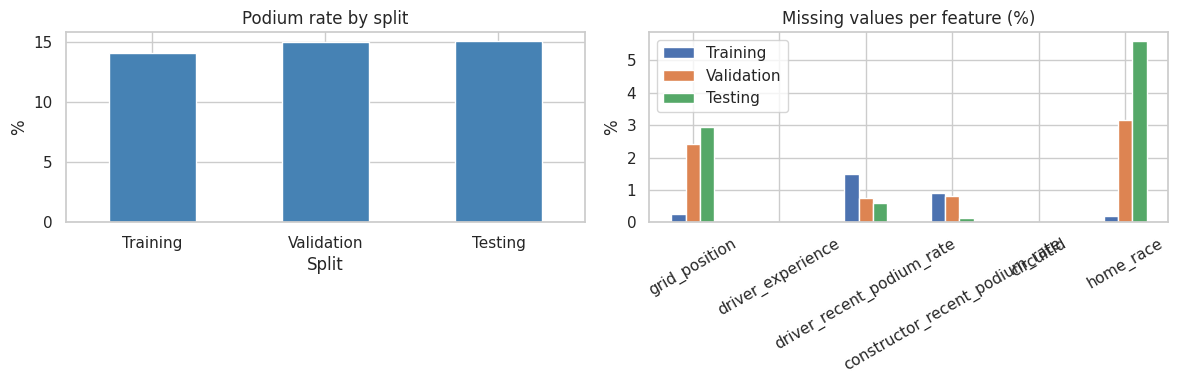


Section 3.1 checks passed.


In [52]:
splits = {
    "Training": (X_train, y_train, train_data),
    "Validation": (X_val, y_val, val_data),
    "Testing": (X_test, y_test, test_data),
}

# 1. Size and class balance of each split.
balance = pd.DataFrame([
    {
        "Split": name,
        "Years": f"{d['year'].min()}-{d['year'].max()}",
        "Rows": len(y),
        "Races": d["raceId"].nunique(),
        "Podiums": int(y.sum()),
        "Non-podiums": int((y == 0).sum()),
        "Podium rate (%)": round(100 * y.mean(), 2),
    }
    for name, (X, y, d) in splits.items()
])
display(balance)

# 2. Missing values per feature in each split (count and percent).
missing_counts = pd.DataFrame({n: X.isna().sum() for n, (X, _, _) in splits.items()})
missing_pct = pd.DataFrame({n: (100 * X.isna().mean()).round(2) for n, (X, _, _) in splits.items()})
print("Missing values (count):")
display(missing_counts)
print("Missing values (%):")
display(missing_pct)

# 3. Data types and ranges (training set).
display(X_train.dtypes.to_frame("dtype"))
display(X_train.describe().T.round(3))

# 4. Range and logic checks on every split.
for name, (X, y, d) in splits.items():
    for col in ["driver_recent_podium_rate", "constructor_recent_podium_rate"]:
        assert X[col].dropna().between(0, 1).all(), f"{name}: {col} outside [0, 1]"
    assert (X["driver_experience"] >= 0).all()
    assert (X["grid_position"].dropna() >= 1).all()
    assert X["home_race"].dropna().isin([0.0, 1.0]).all()

# Each race should have about 3 podium finishers (the target is correct).
podiums_per_race = pd.concat(
    [d.groupby("raceId")["podium"].sum() for _, _, d in splits.values()]
)
print("\nPodiums per race:")
display(podiums_per_race.value_counts().rename_axis("podiums").to_frame("races"))

# Form-feature leakage check: NaN exactly when the driver has no earlier entry.
all_X = pd.concat([X for X, _, _ in splits.values()])
assert (all_X["driver_recent_podium_rate"].isna()
        == (all_X["driver_experience"] == 0)).all()

# 5. Circuits the model will see in validation/test but never saw in training.
train_circuits = set(X_train["circuitId"])
print(f"\nCircuits in training: {len(train_circuits)}")
for name in ["Validation", "Testing"]:
    X = splits[name][0]
    unseen = set(X["circuitId"]) - train_circuits
    print(f"{name}: {len(unseen)} unseen circuit(s) {sorted(unseen)}, "
          f"affecting {X['circuitId'].isin(unseen).sum()} of {len(X)} rows")

# 6. Plot class balance and missingness.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
balance.plot.bar(x="Split", y="Podium rate (%)", ax=ax[0], legend=False, color="steelblue")
ax[0].set_title("Podium rate by split")
ax[0].set_ylabel("%")
ax[0].tick_params(axis="x", rotation=0)

missing_pct.plot.bar(ax=ax[1])
ax[1].set_title("Missing values per feature (%)")
ax[1].set_ylabel("%")
ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

print("\nSection 3.1 checks passed.")

#### 3.1 Findings

- **Splits:** 6,411 training rows (300 races, 2003–2018), 1,200 validation rows (60 races, 2019–2021) and 1,359 test rows (68 races, 2022–2024). Races never overlap between splits.
- **Target:** every one of the 428 races has exactly three podium finishers, so the target is correctly built. The podium rate is 14.04% / 15.00% / 15.01%, about 1 in 7. A model that always predicts "no podium" would score about 85% accuracy and be useless, so we rely on **PR-AUC (primary)**, ROC-AUC, F1, precision and recall instead of accuracy.
- **Missing values** are small in training but grow in recent seasons: `grid_position` 0.27% → 2.42% → 2.94% (more pit-lane starts), and `home_race` 0.19% → 3.17% → 5.59% (our nationality-to-country mapping is incomplete for recent drivers, so those rows are unknown, not "away"). Driver and constructor form are mostly missing in training (96 and 58 rows) because the 2003 cohort starts with no history.
- **Unseen circuits:** training contains 31 circuits. Validation has 5 unseen circuits (120 rows, 10%) and test has 5 (260 rows, 19%), so the encoder must handle unknown categories.
- **Form features are leakage-safe:** the driver form is missing exactly when the driver has no earlier entry (checked by an assertion).

### 3.2 Feature Evidence and Preprocessing Pipeline

#### 3.2.1 Evidence for the chosen features

We explore the relationship between each feature and the podium target using the **training set only**, so no validation or test information influences our feature decisions. Each plot shows the podium rate within groups of a feature, so a feature is useful if the rate changes clearly across its values.

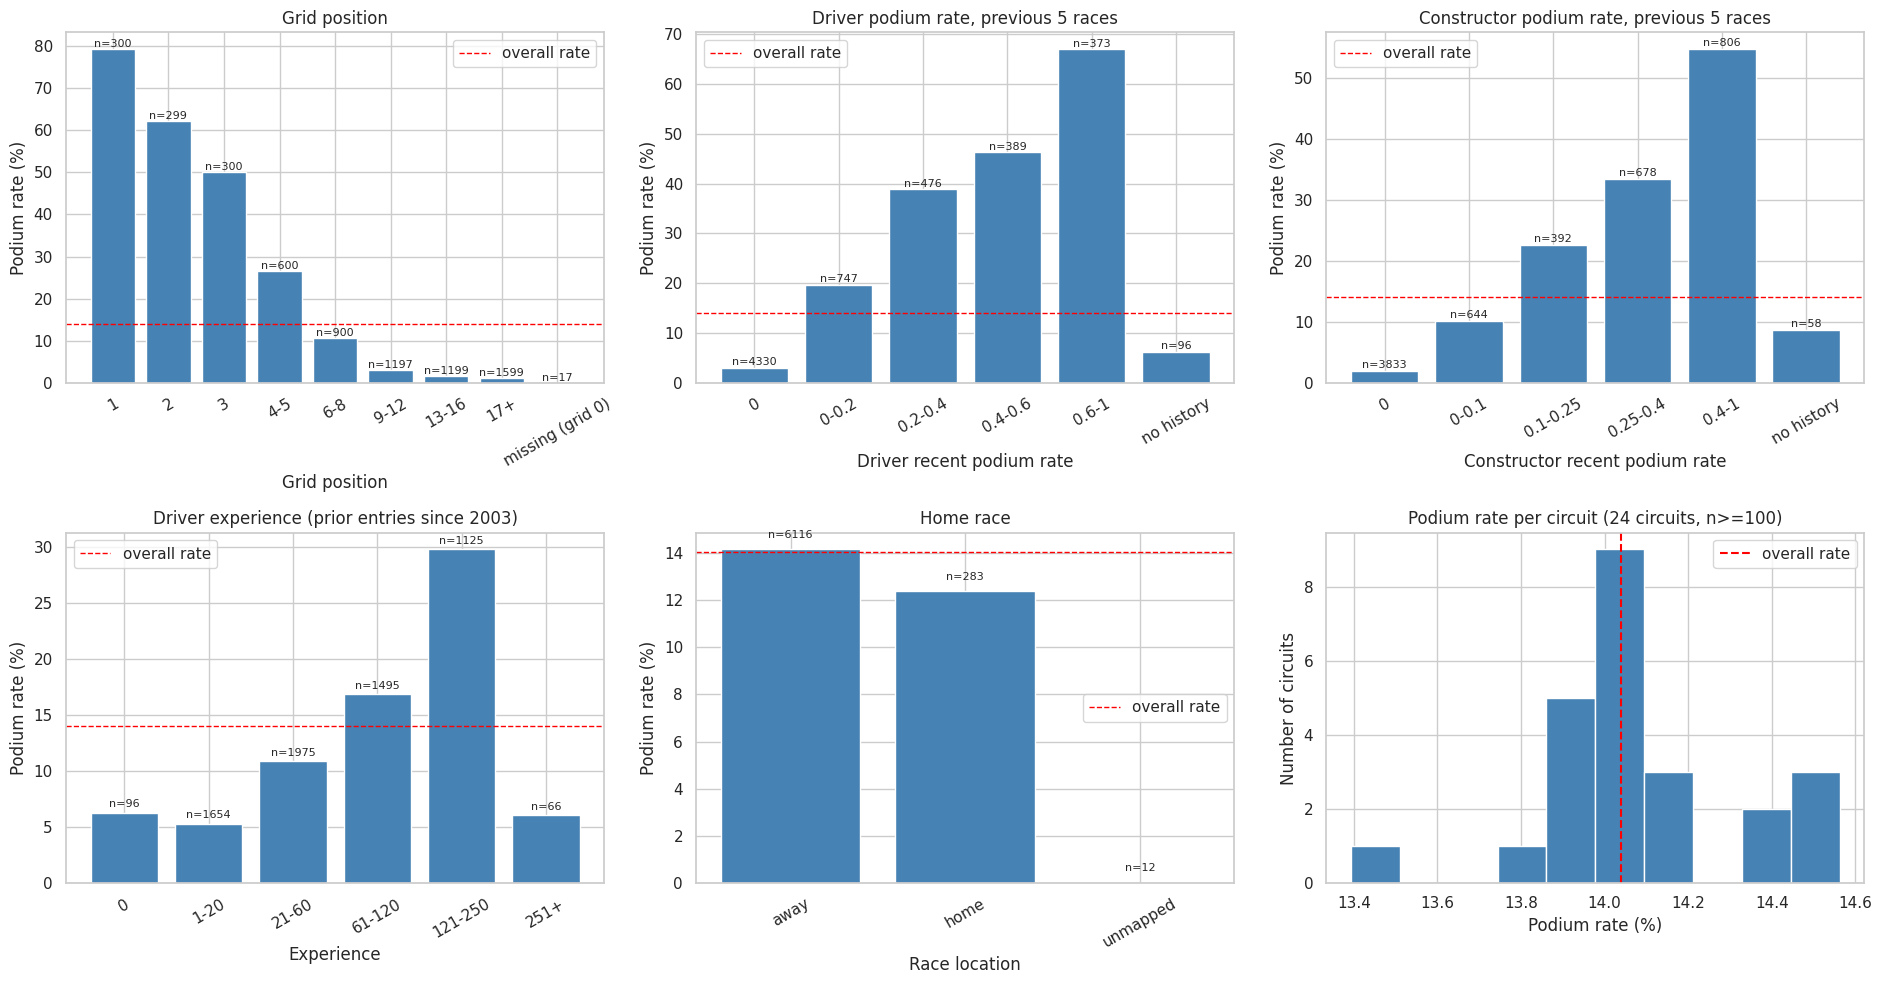

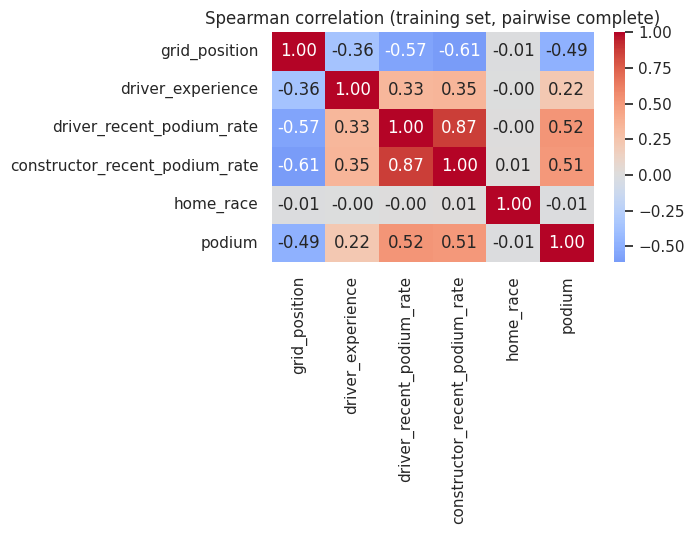

Spearman correlation with podium:


,rho
driver_recent_podium_rate,0.517
constructor_recent_podium_rate,0.506
grid_position,-0.491
driver_experience,0.224
home_race,-0.011


In [53]:
train_eda = X_train.copy()
train_eda["podium"] = y_train

def rate_by_bin(series, bins, labels, nan_label):
    """Podium rate and count per bin, with missing values as their own group."""
    binned = pd.cut(series, bins=bins, labels=labels, include_lowest=True).astype(object)
    binned = binned.where(series.notna(), nan_label)
    out = train_eda.groupby(binned)["podium"].agg(rate="mean", n="size")
    order = [l for l in list(labels) + [nan_label] if l in out.index]
    return out.loc[order]

def bar_with_counts(ax, table, title, xlabel):
    ax.bar(table.index.astype(str), table["rate"] * 100, color="steelblue")
    for i, (r, n) in enumerate(zip(table["rate"], table["n"])):
        ax.text(i, r * 100 + 0.5, f"n={n}", ha="center", fontsize=8)
    ax.axhline(train_eda["podium"].mean() * 100, color="red", ls="--", lw=1,
               label="overall rate")
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("Podium rate (%)")
    ax.tick_params(axis="x", rotation=30); ax.legend()

fig, axes = plt.subplots(2, 3, figsize=(19, 10))

# 1. Grid position
grid = rate_by_bin(train_eda["grid_position"],
                   bins=[0, 1, 2, 3, 5, 8, 12, 16, 30],
                   labels=["1", "2", "3", "4-5", "6-8", "9-12", "13-16", "17+"],
                   nan_label="missing (grid 0)")
bar_with_counts(axes[0, 0], grid, "Grid position", "Grid position")

# 2. Driver recent form
drv = rate_by_bin(train_eda["driver_recent_podium_rate"],
                  bins=[0, 0.0001, 0.2, 0.4, 0.6, 1.0],
                  labels=["0", "0-0.2", "0.2-0.4", "0.4-0.6", "0.6-1"],
                  nan_label="no history")
bar_with_counts(axes[0, 1], drv, "Driver podium rate, previous 5 races", "Driver recent podium rate")

# 3. Constructor recent form
con = rate_by_bin(train_eda["constructor_recent_podium_rate"],
                  bins=[0, 0.0001, 0.1, 0.25, 0.4, 1.0],
                  labels=["0", "0-0.1", "0.1-0.25", "0.25-0.4", "0.4-1"],
                  nan_label="no history")
bar_with_counts(axes[0, 2], con, "Constructor podium rate, previous 5 races", "Constructor recent podium rate")

# 4. Driver experience
exp = rate_by_bin(train_eda["driver_experience"],
                  bins=[-1, 0, 20, 60, 120, 250, 500],
                  labels=["0", "1-20", "21-60", "61-120", "121-250", "251+"],
                  nan_label="n/a")
bar_with_counts(axes[1, 0], exp, "Driver experience (prior entries since 2003)", "Experience")

# 5. Home race
home = train_eda.groupby(train_eda["home_race"].map({0.0: "away", 1.0: "home"}).fillna("unmapped"))["podium"] \
                .agg(rate="mean", n="size")
bar_with_counts(axes[1, 1], home, "Home race", "Race location")

# 6. Circuit: how much does the podium rate vary between circuits?
circ = train_eda.groupby("circuitId")["podium"].agg(rate="mean", n="size")
circ = circ[circ["n"] >= 100]
axes[1, 2].hist(circ["rate"] * 100, bins=10, color="steelblue", edgecolor="white")
axes[1, 2].axvline(train_eda["podium"].mean() * 100, color="red", ls="--", label="overall rate")
axes[1, 2].set_title(f"Podium rate per circuit ({len(circ)} circuits, n>=100)")
axes[1, 2].set_xlabel("Podium rate (%)"); axes[1, 2].set_ylabel("Number of circuits")
axes[1, 2].legend()

plt.tight_layout()
plt.show()

# Rank correlation of each numeric feature with the target (and with each other).
numeric_cols = ["grid_position", "driver_experience", "driver_recent_podium_rate",
                "constructor_recent_podium_rate", "home_race", "podium"]
corr = train_eda[numeric_cols].corr(method="spearman")
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation (training set, pairwise complete)")
plt.tight_layout()
plt.show()

print("Spearman correlation with podium:")
display(corr["podium"].drop("podium").sort_values(key=abs, ascending=False).round(3).to_frame("rho"))

#### 3.2.1 Findings: evidence for the chosen features

| Feature | Evidence (training set) | Decision |
|---|---|---|
| `grid_position` | Strongest single signal. The podium rate falls from about 79% (P1) to 62% (P2), 50% (P3) and 26% (P4–5), then below 3% from P9. Spearman ρ = −0.49 | Keep |
| `driver_recent_podium_rate` | Podium rate rises from about 3% (no podium in the last 5 races) to about 67% (rate 0.6–1). ρ = 0.52 | Keep |
| `constructor_recent_podium_rate` | Same pattern, from about 2% to about 55%. ρ = 0.51. It captures car performance, which the brief names as the dominant factor | Keep |
| `driver_experience` | Weaker (ρ = 0.22) and not monotonic: it rises up to 121–250 prior entries and then drops (the 251+ group has only 66 rows). Experience is partly a proxy for being in a strong team | Keep, test in ablation |
| `home_race` | Home 12.4% vs away 14.2%, ρ = −0.01. This agrees with Section 2.2 (no home advantage) | Weak, test in ablation |
| `circuitId` | The per-circuit podium rate only ranges from about 13.4% to 14.5%, because every race has exactly three podium finishers. The circuit alone says little | Weak, test in ablation |

Driver form and constructor form are strongly correlated (ρ = 0.87), and both correlate with the grid (|ρ| ≈ 0.6). They carry overlapping information, which matters when interpreting logistic-regression coefficients and importances later. Missing form values ("no history") have low podium rates (about 6% and 9%), so keeping a missing indicator is justified.

#### 3.2.2 Preprocessing pipeline

All learned preprocessing steps are **fitted on the training set only** and then applied to validation and test data with `transform` only.

| Feature type | Columns | Steps | Reason |
|---|---|---|---|
| Numeric | `grid_position`, `driver_experience`, `driver_recent_podium_rate`, `constructor_recent_podium_rate` | median imputation + missing-indicator, then standardization | The median is robust to skew. The indicator keeps "no history" and "grid 0" visible to the model instead of pretending they are real values. Scaling is needed by logistic regression and the neural network. |
| Binary | `home_race` | most-frequent imputation + missing-indicator | Unmapped nationalities are unknown, not "away". The indicator preserves that. |
| Categorical | `circuitId` | one-hot encoding, unknown categories ignored | A circuit ID is a label, not a quantity. Circuits unseen in training (e.g. new venues) become all zeros instead of crashing. |

Tree models do not need scaling, so the builder below can switch it off. The cohort and the features stay identical for every model.

Shapes: (6411, 40) (1200, 40) (1359, 40)
No NaN left; identical column layout in all splits.

Medians learned on training:


,median
grid_position,11.0
driver_experience,47.0
driver_recent_podium_rate,0.0
constructor_recent_podium_rate,0.0


Output columns: ['grid_position', 'driver_experience', 'driver_recent_podium_rate', 'constructor_recent_podium_rate', 'missingindicator_grid_position', 'missingindicator_driver_recent_podium_rate', 'missingindicator_constructor_recent_podium_rate', 'home_race', 'missingindicator_home_race'] + 31 circuit columns
Unseen circuit handled (all circuit columns are 0).

Before preprocessing (observed values only):


,count,mean,std,min,max
grid_position,6394.0,11.224,6.254,1.0,24.0
driver_experience,6411.0,67.136,62.056,0.0,296.0
driver_recent_podium_rate,6315.0,0.142,0.253,0.0,1.0
constructor_recent_podium_rate,6353.0,0.141,0.228,0.0,1.0


After imputation + scaling:


,count,mean,std,min,max
grid_position,6411.0,-0.0,1.0,-1.637,2.046
driver_experience,6411.0,0.0,1.0,-1.082,3.688
driver_recent_podium_rate,6411.0,-0.0,1.0,-0.556,3.426
constructor_recent_podium_rate,6411.0,0.0,1.0,-0.615,3.780


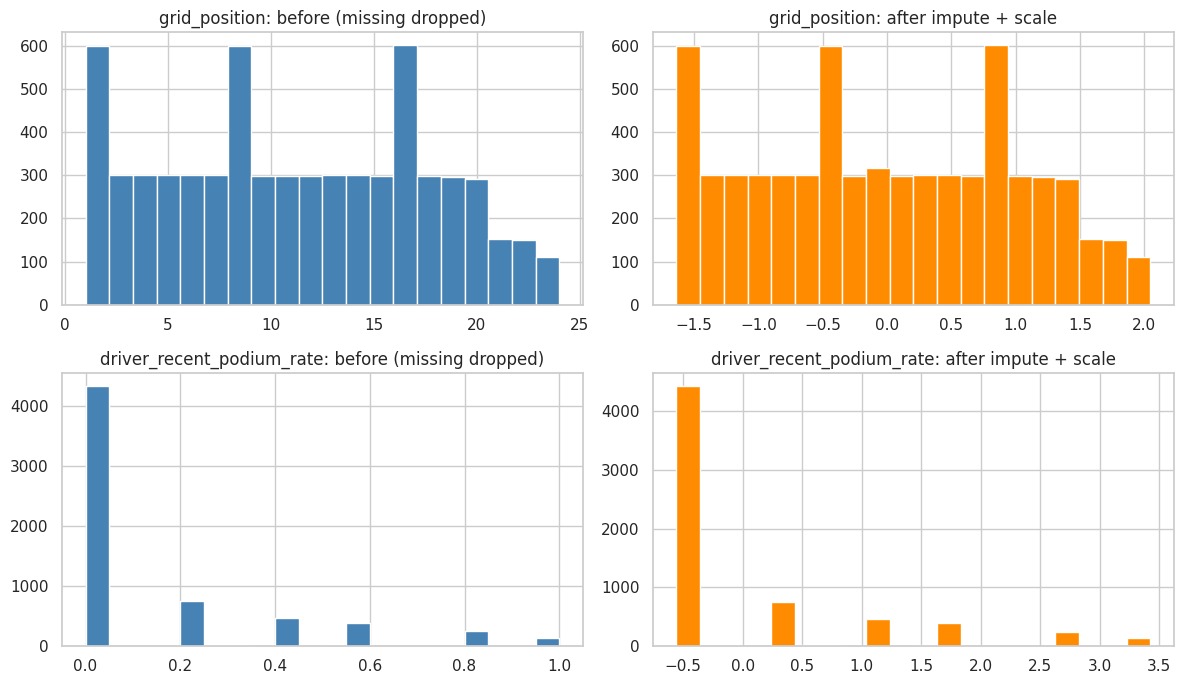

In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ["grid_position", "driver_experience",
                    "driver_recent_podium_rate", "constructor_recent_podium_rate"]
binary_features = ["home_race"]
categorical_features = ["circuitId"]

assert sorted(numeric_features + binary_features + categorical_features) == sorted(feature_columns)

def build_preprocessor(numeric, binary, categorical, scale=True):
    """Unfitted preprocessing for any subset of features (also used for ablations)."""
    transformers = []
    if numeric:
        steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
        if scale:
            steps.append(("scale", StandardScaler()))
        transformers.append(("num", Pipeline(steps), numeric))
    if binary:
        transformers.append(("bin", SimpleImputer(strategy="most_frequent", add_indicator=True), binary))
    if categorical:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical))
    pre = ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)
    pre.set_output(transform="pandas")
    return pre

# Fit on training only, transform all three splits.
demo_pre = build_preprocessor(numeric_features, binary_features, categorical_features)
Xtr_t = demo_pre.fit_transform(X_train)
Xva_t = demo_pre.transform(X_val)
Xte_t = demo_pre.transform(X_test)

print("Shapes:", Xtr_t.shape, Xva_t.shape, Xte_t.shape)
assert not Xtr_t.isna().any().any() and not Xva_t.isna().any().any() and not Xte_t.isna().any().any()
assert list(Xtr_t.columns) == list(Xva_t.columns) == list(Xte_t.columns)
print("No NaN left; identical column layout in all splits.")

# Learned imputation values (from training only).
imputer = demo_pre.named_transformers_["num"].named_steps["impute"]
print("\nMedians learned on training:")
display(pd.Series(imputer.statistics_, index=numeric_features).round(3).to_frame("median"))

print("Output columns:", [c for c in Xtr_t.columns if not c.startswith("circuitId_")],
      f"+ {sum(c.startswith('circuitId_') for c in Xtr_t.columns)} circuit columns")

# An unseen circuit must not crash the pipeline.
unseen_row = X_val.iloc[[0]].copy()
unseen_row["circuitId"] = 99999
unseen_out = demo_pre.transform(unseen_row)
assert unseen_out.filter(like="circuitId_").sum(axis=1).iloc[0] == 0
print("Unseen circuit handled (all circuit columns are 0).")

# Effect of preprocessing on the distributions (training set).
before = X_train[numeric_features].describe().T[["count", "mean", "std", "min", "max"]]
after = Xtr_t[numeric_features].describe().T[["count", "mean", "std", "min", "max"]]
print("\nBefore preprocessing (observed values only):")
display(before.round(3))
print("After imputation + scaling:")
display(after.round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for col, row in [("grid_position", 0), ("driver_recent_podium_rate", 1)]:
    axes[row, 0].hist(X_train[col].dropna(), bins=20, color="steelblue")
    axes[row, 0].set_title(f"{col}: before (missing dropped)")
    axes[row, 1].hist(Xtr_t[col], bins=20, color="darkorange")
    axes[row, 1].set_title(f"{col}: after impute + scale")
plt.tight_layout()
plt.show()

#### 3.2.3 Results of the preprocessing

Fitted on training only, the pipeline produces 40 numeric columns (4 scaled numeric features, 1 binary feature, 4 missing-indicators and 31 circuit columns) with no missing values, an identical layout for training, validation and test, and all-zero circuit columns for an unseen circuit. The learned medians are 11 for grid position, 47 for experience and 0 for both form rates. Scaling gives every numeric feature mean 0 and standard deviation 1 without changing the distribution shapes. Imputing the median adds only a small spike at the median for grid position, while the form features keep their strong right skew (most drivers have not recently podiumed). The missing indicators preserve the "no history" and "grid 0" information that the median would otherwise hide.

### 3.3 Statistical Models and Baseline

**Metric policy.** The podium is rare (about 15%), so **PR-AUC (average precision) is our primary metric**: it measures how well the model ranks true podium finishers above the rest and ignores the large number of easy true negatives. **ROC-AUC** is the secondary metric. F1, precision and recall depend on a probability threshold, which we pick for each model by maximizing F1 on the **validation set only**. Hyperparameters are selected by validation PR-AUC. The test set is not touched until the final evaluation.

**Baseline.** Logistic Regression is our official baseline model. It is a simple, interpretable linear model: it combines the scaled features into a weighted sum and turns it into a probability with the logistic function. Its limitation is that it can only learn linear effects (on the log-odds scale) and cannot capture interactions, such as "front-row start with a strong team", unless we engineer them. A constant predictor that always outputs the training podium rate is shown only as a sanity reference.

In [55]:
from itertools import product
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, precision_recall_curve)

def best_f1_threshold(y_true, proba):
    """Probability threshold that maximizes F1 (called on validation data only)."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return float(thresholds[np.argmax(f1)])

def evaluate(y_true, proba, threshold):
    """All five metrics. AUCs use probabilities; the others use the threshold."""
    pred = (proba >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
    }

# Sanity reference: always predict the training podium rate.
dummy = DummyClassifier(strategy="prior").fit(X_train, y_train)
dummy_val = dummy.predict_proba(X_val)[:, 1]
dummy_threshold = best_f1_threshold(y_val, dummy_val)
print("Constant-rate reference on validation (any real model must beat this):")
display(pd.Series(evaluate(y_val, dummy_val, dummy_threshold)).round(3).to_frame("Constant predictor"))

# Every attempt is logged so the trials stay visible in the notebook.
tuning_log = []

def run_grid(name, make_model, grid):
    """Fit every setting on TRAIN, score on VALIDATION, return the best by PR-AUC."""
    best = None
    for values in product(*grid.values()):
        params = dict(zip(grid, values))
        model = make_model(**params).fit(X_train, y_train)
        p_val = model.predict_proba(X_val)[:, 1]
        row = {"Model": name, **params,
               "Val PR-AUC": average_precision_score(y_val, p_val),
               "Val ROC-AUC": roc_auc_score(y_val, p_val)}
        tuning_log.append(row)
        if best is None or row["Val PR-AUC"] > best[0]:
            best = (row["Val PR-AUC"], params, model)
    return best[1], best[2]

Constant-rate reference on validation (any real model must beat this):


,Constant predictor
ROC-AUC,0.500
PR-AUC,0.150
F1,0.261
Precision,0.150
Recall,1.000


In [56]:
def make_lr(C, class_weight):
    return Pipeline([
        ("pre", build_preprocessor(numeric_features, binary_features,
                                   categorical_features, scale=True)),
        ("clf", LogisticRegression(C=C, class_weight=class_weight,
                                   max_iter=2000, random_state=RANDOM_STATE)),
    ])

lr_grid = {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]}
lr_params, lr_model = run_grid("Logistic Regression", make_lr, lr_grid)

lr_log = pd.DataFrame([r for r in tuning_log if r["Model"] == "Logistic Regression"])
display(lr_log.sort_values("Val PR-AUC", ascending=False).round(4))
print("Selected (best validation PR-AUC):", lr_params)

lr_val = lr_model.predict_proba(X_val)[:, 1]
lr_train = lr_model.predict_proba(X_train)[:, 1]
lr_threshold = best_f1_threshold(y_val, lr_val)
print(f"Threshold chosen on validation: {lr_threshold:.3f}")
display(pd.DataFrame({"Train": evaluate(y_train, lr_train, lr_threshold),
                      "Validation": evaluate(y_val, lr_val, lr_threshold)}).round(3))

,Model,C,class_weight,Val PR-AUC,Val ROC-AUC
6,Logistic Regression,10.00,None,0.7131,0.9237
4,Logistic Regression,1.00,None,0.7126,0.9237
2,Logistic Regression,0.10,None,0.7114,0.9238
0,Logistic Regression,0.01,None,0.6948,0.9231
3,Logistic Regression,0.10,balanced,0.6929,0.9234
1,Logistic Regression,0.01,balanced,0.6928,0.9233
5,Logistic Regression,1.00,balanced,0.6905,0.9233
7,Logistic Regression,10.00,balanced,0.6891,0.9234


Selected (best validation PR-AUC): {'C': 10, 'class_weight': None}
Threshold chosen on validation: 0.303


,Train,Validation
ROC-AUC,0.922,0.924
PR-AUC,0.675,0.713
F1,0.663,0.731
Precision,0.592,0.662
Recall,0.753,0.817


In [57]:
def make_rf(n_estimators, max_depth, min_samples_leaf, class_weight):
    return Pipeline([
        ("pre", build_preprocessor(numeric_features, binary_features,
                                   categorical_features, scale=False)),
        ("clf", RandomForestClassifier(
            n_estimators=n_estimators, max_depth=max_depth,
            min_samples_leaf=min_samples_leaf, class_weight=class_weight,
            random_state=RANDOM_STATE, n_jobs=-1)),
    ])

rf_grid = {
    "n_estimators": [300],
    "max_depth": [4, 8, None],
    "min_samples_leaf": [1, 5, 20],
    "class_weight": [None, "balanced_subsample"],
}
rf_params, rf_model = run_grid("Random Forest", make_rf, rf_grid)

rf_log = pd.DataFrame([r for r in tuning_log if r["Model"] == "Random Forest"])
display(rf_log.sort_values("Val PR-AUC", ascending=False).round(4))
print("Selected (best validation PR-AUC):", rf_params)

rf_val = rf_model.predict_proba(X_val)[:, 1]
rf_train = rf_model.predict_proba(X_train)[:, 1]
rf_threshold = best_f1_threshold(y_val, rf_val)
print(f"Threshold chosen on validation: {rf_threshold:.3f}")
display(pd.DataFrame({"Train": evaluate(y_train, rf_train, rf_threshold),
                      "Validation": evaluate(y_val, rf_val, rf_threshold)}).round(3))

,Model,n_estimators,max_depth,min_samples_leaf,class_weight,Val PR-AUC,Val ROC-AUC
2,Random Forest,300,4.0,5,None,0.7241,0.9273
14,Random Forest,300,NaN,5,None,0.7160,0.9326
0,Random Forest,300,4.0,1,None,0.7149,0.9278
17,Random Forest,300,NaN,20,balanced_subsample,0.7113,0.9308
4,Random Forest,300,4.0,20,None,0.7098,0.9256
16,Random Forest,300,NaN,20,None,0.7088,0.9305
8,Random Forest,300,8.0,5,None,0.7073,0.9295
10,Random Forest,300,8.0,20,None,0.7060,0.9282
6,Random Forest,300,8.0,1,None,0.7036,0.9281
11,Random Forest,300,8.0,20,balanced_subsample,0.6961,0.9286


Selected (best validation PR-AUC): {'n_estimators': 300, 'max_depth': 4, 'min_samples_leaf': 5, 'class_weight': None}
Threshold chosen on validation: 0.338


,Train,Validation
ROC-AUC,0.927,0.927
PR-AUC,0.690,0.724
F1,0.646,0.721
Precision,0.661,0.704
Recall,0.632,0.739


#### Random Forest results

- Selected by validation PR-AUC: `max_depth = 4`, `min_samples_leaf = 5`, no class weighting (300 trees). Validation PR-AUC is 0.724 and ROC-AUC 0.927, with F1 0.721 (precision 0.704, recall 0.739) at threshold 0.338.
- **Simpler forests won.** The deepest, least-regularized forests (`max_depth=None`, `min_samples_leaf=1`) were among the worst (PR-AUC about 0.66–0.68), which is the classic sign of trees memorizing noise. Limiting depth or raising the leaf size helped, which fits a small dataset (6,411 rows) with a weak signal beyond the top features.
- `class_weight="balanced_subsample"` was worse in most settings, which matches what we saw for Logistic Regression: the F1-optimal threshold already handles the imbalance.
- Training scores (PR-AUC 0.690) are below validation scores (0.724), so there is no overfitting.
- **Random Forest vs Logistic Regression:** the Random Forest is slightly ahead on PR-AUC (0.724 vs 0.713) and ROC-AUC (0.927 vs 0.924), while Logistic Regression has the higher F1 (0.731 vs 0.721). With only 180 validation podiums these gaps are small and may not be meaningful. The result suggests that the main signal (grid position and recent form) is mostly additive, so a non-linear model gains little. Validation F1, precision and recall are slightly optimistic, because the threshold was chosen on the same data. The test set gives the unbiased numbers.

### 3.4 Shallow Neural Network

A feed-forward network with one or two hidden layers. Each hidden layer applies a weighted sum of its inputs followed by a ReLU, and a final sigmoid unit outputs the podium probability. We train it with binary cross-entropy (the standard loss for a yes/no target, which pushes probabilities toward the true labels) and the Adam optimizer (adaptive learning rates, which usually converge reliably without much tuning). It receives exactly the same features as the other two models, after the same training-fitted preprocessing with scaling, because neural networks are sensitive to feature scale.

To control overfitting we use early stopping on validation loss (patience 15, restoring the best weights) and optionally dropout. We compare four architectures on the validation set (selected by PR-AUC) and fix all random seeds. Limitations: it is less interpretable than the other models, it is sensitive to initialization and hyperparameters, and with about 6,400 training rows it has little data to learn complex patterns.

NN input shapes: (6411, 40) (1200, 40)


2026-10-16 20:38:06.612959: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


,Model,hidden_units,dropout,learning_rate,Val PR-AUC,Val ROC-AUC,best_epoch
2,Shallow NN,"(32, 16)",0.3,0.001,0.7391,0.9311,29
0,Shallow NN,"(16,)",0.0,0.001,0.7367,0.9309,51
1,Shallow NN,"(32, 16)",0.0,0.001,0.7259,0.9313,23
3,Shallow NN,"(64, 32)",0.3,0.001,0.7250,0.9331,31


Selected (best validation PR-AUC): {'hidden_units': (32, 16), 'dropout': 0.3, 'learning_rate': 0.001}
Threshold chosen on validation: 0.472


,Train,Validation
ROC-AUC,0.938,0.931
PR-AUC,0.714,0.739
F1,0.659,0.717
Precision,0.676,0.691
Recall,0.642,0.744


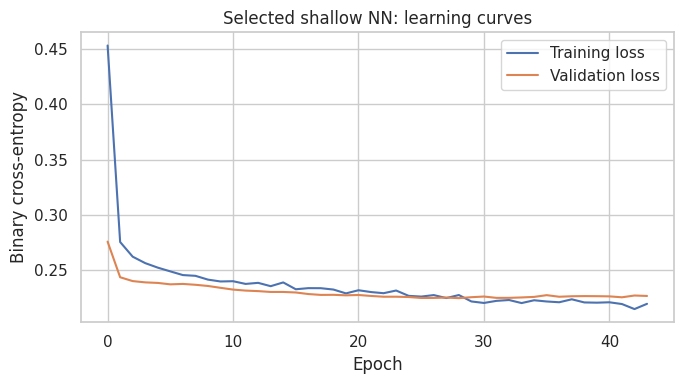

In [58]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Same preprocessing as the linear model: fitted on training only.
# The test set is not transformed here; it stays untouched until the final evaluation.
nn_pre = build_preprocessor(numeric_features, binary_features,
                            categorical_features, scale=True)
Xtr_nn = nn_pre.fit_transform(X_train).to_numpy("float32")
Xva_nn = nn_pre.transform(X_val).to_numpy("float32")
ytr_nn = y_train.to_numpy("float32")
yva_nn = y_val.to_numpy("float32")
print("NN input shapes:", Xtr_nn.shape, Xva_nn.shape)

def build_nn(input_dim, hidden_units, dropout, learning_rate):
    keras.utils.set_random_seed(RANDOM_STATE)   # seeds Python, NumPy and TensorFlow
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for units in hidden_units:
        model.add(layers.Dense(units, activation="relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="binary_crossentropy")
    return model

nn_configs = [
    {"hidden_units": (16,),    "dropout": 0.0, "learning_rate": 1e-3},
    {"hidden_units": (32, 16), "dropout": 0.0, "learning_rate": 1e-3},
    {"hidden_units": (32, 16), "dropout": 0.3, "learning_rate": 1e-3},
    {"hidden_units": (64, 32), "dropout": 0.3, "learning_rate": 1e-3},
]

nn_best = None
nn_histories = {}

for cfg in nn_configs:
    model = build_nn(Xtr_nn.shape[1], **cfg)
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=15, restore_best_weights=True)
    history = model.fit(Xtr_nn, ytr_nn, validation_data=(Xva_nn, yva_nn),
                        epochs=200, batch_size=64,
                        callbacks=[early_stop], verbose=0)

    p_val = model.predict(Xva_nn, verbose=0).ravel()
    row = {"Model": "Shallow NN", "hidden_units": str(cfg["hidden_units"]),
           "dropout": cfg["dropout"], "learning_rate": cfg["learning_rate"],
           "Val PR-AUC": average_precision_score(y_val, p_val),
           "Val ROC-AUC": roc_auc_score(y_val, p_val)}
    row["best_epoch"] = int(np.argmin(history.history["val_loss"]) + 1)
    tuning_log.append(row)
    nn_histories[str(cfg["hidden_units"]) + f" dropout={cfg['dropout']}"] = history.history

    if nn_best is None or row["Val PR-AUC"] > nn_best["pr_auc"]:
        nn_best = {"pr_auc": row["Val PR-AUC"], "cfg": cfg, "model": model,
                   "history": history.history}

nn_log = pd.DataFrame([r for r in tuning_log if r["Model"] == "Shallow NN"])
display(nn_log.sort_values("Val PR-AUC", ascending=False).round(4))
print("Selected (best validation PR-AUC):", nn_best["cfg"])

nn_model = nn_best["model"]
nn_val = nn_model.predict(Xva_nn, verbose=0).ravel()
nn_train = nn_model.predict(Xtr_nn, verbose=0).ravel()
assert nn_val.min() >= 0 and nn_val.max() <= 1
nn_threshold = best_f1_threshold(y_val, nn_val)
print(f"Threshold chosen on validation: {nn_threshold:.3f}")
display(pd.DataFrame({"Train": evaluate(y_train, nn_train, nn_threshold),
                      "Validation": evaluate(y_val, nn_val, nn_threshold)}).round(3))

# Learning curves of the selected network.
plt.figure(figsize=(7, 4))
plt.plot(nn_best["history"]["loss"], label="Training loss")
plt.plot(nn_best["history"]["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Binary cross-entropy")
plt.title("Selected shallow NN: learning curves")
plt.legend(); plt.tight_layout(); plt.show()

#### Shallow Neural Network results

- Four architectures were compared on the validation set. The selected network has two hidden layers (32 and 16 ReLU units) with dropout 0.3 and learning rate 0.001, and early stopping restored the weights from epoch 29. Validation PR-AUC is 0.739 and ROC-AUC 0.931, with F1 0.717 (precision 0.691, recall 0.744) at threshold 0.472.
- The four configurations score within about 0.014 PR-AUC of each other (0.725–0.739), so the architecture matters little here. A single hidden layer of 16 units (0.737) is almost as good as the selected one.
- **Learning curves:** both losses drop sharply in the first epochs and then flatten together at about 0.22–0.23, with no widening gap. This indicates no overfitting, and early stopping ended training around epoch 43. Training loss starts above validation loss because dropout is active during training only, and the validation period may be somewhat easier to predict.
- Training scores (PR-AUC 0.714) are below validation scores (0.739). The network's epoch count was chosen using validation loss, so its validation numbers are slightly optimistic compared with those of a model with no early-stopping decision. Results come from a single random seed.

### 3.5 Model Evaluation and Comparison

All three models are compared on the same rows and features, using each model's own validation-selected threshold. This section uses **training and validation data only**. The unseen test set is evaluated once, at the end, after all experiments are complete.

Besides the metric table we show ROC and precision-recall curves and confusion matrices on the validation set. Because the validation set contains only 180 podium finishers, we also bootstrap the validation races (1,000 resamples) to see how much of the difference between models could be noise.

,Model,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression (baseline),Train,0.303,0.922,0.675,0.663,0.592,0.753
1,Logistic Regression (baseline),Validation,0.303,0.924,0.713,0.731,0.662,0.817
2,Random Forest,Train,0.338,0.927,0.690,0.646,0.661,0.632
3,Random Forest,Validation,0.338,0.927,0.724,0.721,0.704,0.739
4,Shallow NN,Train,0.472,0.938,0.714,0.659,0.676,0.642
5,Shallow NN,Validation,0.472,0.931,0.739,0.717,0.691,0.744


Selected hyperparameters:
  Logistic Regression: {'C': 10, 'class_weight': None}
  Random Forest: {'n_estimators': 300, 'max_depth': 4, 'min_samples_leaf': 5, 'class_weight': None}
  Shallow NN: {'hidden_units': (32, 16), 'dropout': 0.3, 'learning_rate': 0.001}


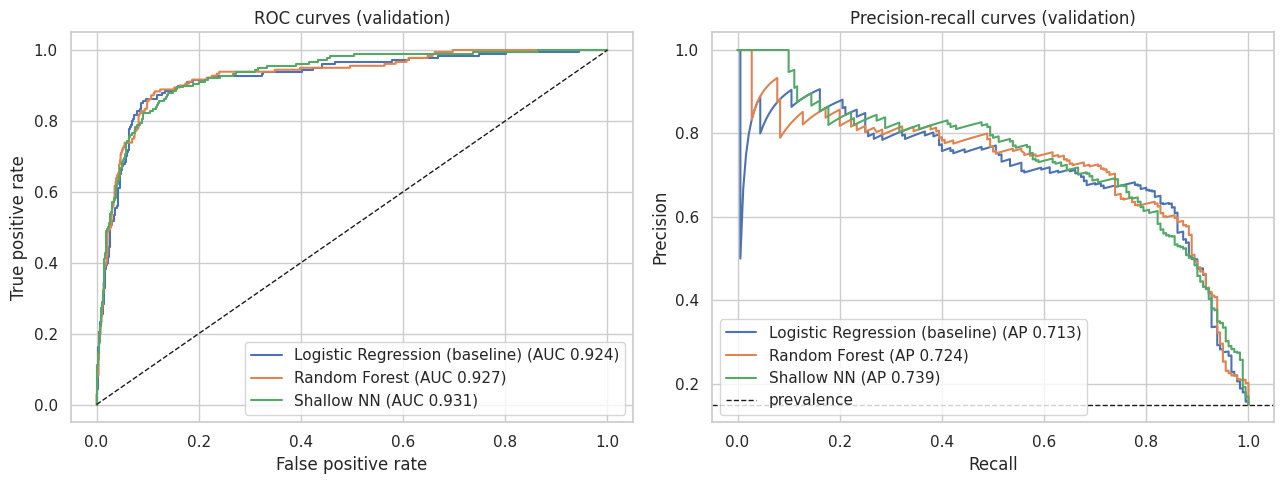

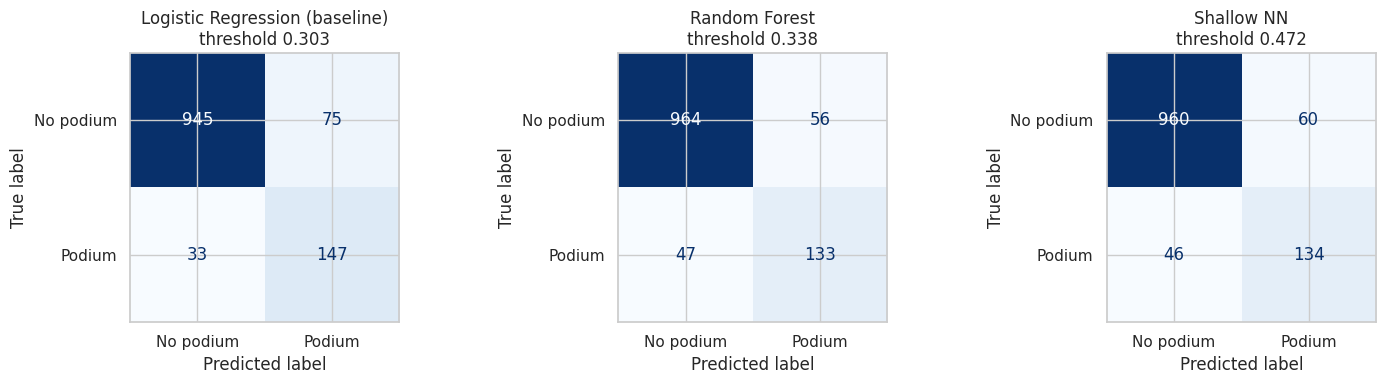

,PR-AUC (point),95% CI low,95% CI high
Logistic Regression (baseline),0.713,0.611,0.810
Random Forest,0.724,0.627,0.814
Shallow NN,0.739,0.655,0.816


,Comparison,Mean diff,95% CI low,95% CI high
0,Random Forest minus Logistic Regression (basel...,0.010,-0.013,0.034
1,Shallow NN minus Logistic Regression (baseline),0.024,-0.019,0.068
2,Shallow NN minus Random Forest,0.014,-0.026,0.057


In [59]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

models_eval = {
    "Logistic Regression (baseline)": (lr_train, lr_val, lr_threshold),
    "Random Forest": (rf_train, rf_val, rf_threshold),
    "Shallow NN": (nn_train, nn_val, nn_threshold),
}

# 1. Metric table: all five metrics, train and validation.
rows = []
for name, (p_tr, p_va, thr) in models_eval.items():
    for split, y, p in [("Train", y_train, p_tr), ("Validation", y_val, p_va)]:
        rows.append({"Model": name, "Split": split, "Threshold": round(thr, 3),
                     **evaluate(y, p, thr)})
comparison = pd.DataFrame(rows)
display(comparison.round(3))

print("Selected hyperparameters:")
print("  Logistic Regression:", lr_params)
print("  Random Forest:", rf_params)
print("  Shallow NN:", nn_best["cfg"])

# 2. ROC and precision-recall curves on validation.
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, (_, p_va, _) in models_eval.items():
    fpr, tpr, _ = roc_curve(y_val, p_va)
    prec, rec, _ = precision_recall_curve(y_val, p_va)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_val, p_va):.3f})")
    ax[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_val, p_va):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate")
ax[0].set_title("ROC curves (validation)"); ax[0].legend()
ax[1].axhline(y_val.mean(), color="k", ls="--", lw=1, label="prevalence")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-recall curves (validation)"); ax[1].legend()
plt.tight_layout(); plt.show()

# 3. Confusion matrices at each model's validation threshold.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax_, (name, (_, p_va, thr)) in zip(axes, models_eval.items()):
    pred = (p_va >= thr).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_val, pred, display_labels=["No podium", "Podium"], cmap="Blues", ax=ax_, colorbar=False)
    ax_.set_title(f"{name}\nthreshold {thr:.3f}")
plt.tight_layout(); plt.show()

# 4. Bootstrap over validation races: how large is the noise?
rng = np.random.default_rng(RANDOM_STATE)
val_races = val_data["raceId"].to_numpy()
race_ids = np.unique(val_races)
idx_by_race = {r: np.where(val_races == r)[0] for r in race_ids}
yv = y_val.to_numpy()
probs = {name: v[1] for name, v in models_eval.items()}
boot = {name: [] for name in probs}

for _ in range(1000):
    sampled = rng.choice(race_ids, size=len(race_ids), replace=True)
    idx = np.concatenate([idx_by_race[r] for r in sampled])
    for name, p in probs.items():
        boot[name].append(average_precision_score(yv[idx], p[idx]))
boot = {k: np.array(v) for k, v in boot.items()}

ci = pd.DataFrame({
    name: {"PR-AUC (point)": average_precision_score(yv, probs[name]),
           "95% CI low": np.percentile(b, 2.5), "95% CI high": np.percentile(b, 97.5)}
    for name, b in boot.items()
}).T
display(ci.round(3))

names = list(boot)
diffs = pd.DataFrame([
    {"Comparison": f"{a} minus {b}",
     "Mean diff": (boot[a] - boot[b]).mean(),
     "95% CI low": np.percentile(boot[a] - boot[b], 2.5),
     "95% CI high": np.percentile(boot[a] - boot[b], 97.5)}
    for a, b in [(names[1], names[0]), (names[2], names[0]), (names[2], names[1])]
])
display(diffs.round(3))

#### 3.5 Findings

| Model | Val PR-AUC | Val ROC-AUC | Val F1 | Precision | Recall |
|---|---|---|---|---|---|
| Logistic Regression (baseline) | 0.713 | 0.924 | 0.731 | 0.662 | 0.817 |
| Random Forest | 0.724 | 0.927 | 0.721 | 0.704 | 0.739 |
| Shallow NN | 0.739 | 0.931 | 0.717 | 0.691 | 0.744 |

- **The ranking by PR-AUC is NN > Random Forest > Logistic Regression, but the differences are small.** The bootstrap over validation races gives 95% intervals for PR-AUC of 0.611–0.810 (LR), 0.627–0.814 (RF) and 0.655–0.816 (NN). Every pairwise difference interval includes zero (for example NN minus LR: +0.024, interval −0.019 to +0.068). With only 180 validation podiums we cannot claim any model is truly better. The bootstrap resamples the validation races only; it does not capture variation from retraining (random seeds, different training data).
- **All three beat the constant predictor by a wide margin** (PR-AUC about 0.71–0.74 vs 0.15). The ROC curves are almost on top of each other, and the precision-recall curves overlap everywhere except in the noisy low-recall region.
- **Operating points differ.** At each model's F1-optimal threshold, Logistic Regression finds more podiums (147 of 180, recall 0.817) but at the cost of more false alarms (75), while the Random Forest and the NN are more conservative (133 and 134 podiums found, 56 and 60 false alarms). F1 values are close (0.717–0.731), and F1 depends on the threshold rule, which is why PR-AUC is our primary metric.
- **Primary metric:** PR-AUC, because podiums are rare (15%) and it measures how well podium finishers are ranked above everyone else.

### 3.6 Feature-Group Ablation

Evidence from the earlier exploratory plots suggests which features matter. An ablation measures their actual contribution: we remove one feature group at a time, **re-fit the preprocessing and the model from scratch on the training set**, and compare validation scores with the full model.

| Group | Features |
|---|---|
| Grid | `grid_position` |
| Driver history | `driver_experience`, `driver_recent_podium_rate` |
| Team history | `constructor_recent_podium_rate` |
| Context | `circuitId`, `home_race` |

All three models are ablated with the hyperparameters selected earlier (nothing is re-tuned, so differences come from the features alone). The F1 threshold is re-chosen on validation for each variant, using the same rule as before. The Shallow NN is trained with 3 random seeds and the scores are averaged, because a single network run varies from seed to seed. Differences smaller than the bootstrap noise seen above (about 0.01–0.02 PR-AUC) should not be over-interpreted. A drop in score shows that the model relies on that information, which does not mean the feature causes podiums.

done: Full model
done: Without Grid
done: Without Driver history
done: Without Team history
done: Without Context (circuit, home race)


,Variant,Model,n_features,PR-AUC,PR-AUC std (seeds),ROC-AUC,F1,Delta PR-AUC vs full
0,Full model,Logistic Regression,6,0.7131,0.0000,0.9237,0.7313,0.0000
1,Full model,Random Forest,6,0.7241,0.0000,0.9273,0.7209,0.0000
2,Full model,Shallow NN,6,0.7354,0.0102,0.9310,0.7226,0.0000
3,Without Grid,Logistic Regression,5,0.6022,0.0000,0.8865,0.6650,-0.1108
4,Without Grid,Random Forest,5,0.5845,0.0000,0.8857,0.6651,-0.1396
5,Without Grid,Shallow NN,5,0.6145,0.0012,0.8927,0.6737,-0.1209
6,Without Driver history,Logistic Regression,4,0.6967,0.0000,0.9231,0.7301,-0.0164
7,Without Driver history,Random Forest,4,0.7310,0.0000,0.9327,0.7415,0.0068
8,Without Driver history,Shallow NN,4,0.7415,0.0095,0.9312,0.7316,0.0061
9,Without Team history,Logistic Regression,5,0.7191,0.0000,0.9225,0.7309,0.0061


Change in validation PR-AUC when a group is removed (negative = the group helped):


Model,Logistic Regression,Random Forest,Shallow NN
Variant,,,
Without Grid,-0.1108,-0.1396,-0.1209
Without Driver history,-0.0164,0.0068,0.0061
Without Team history,0.0061,-0.0280,-0.0132
"Without Context (circuit, home race)",0.0054,-0.0105,-0.0091


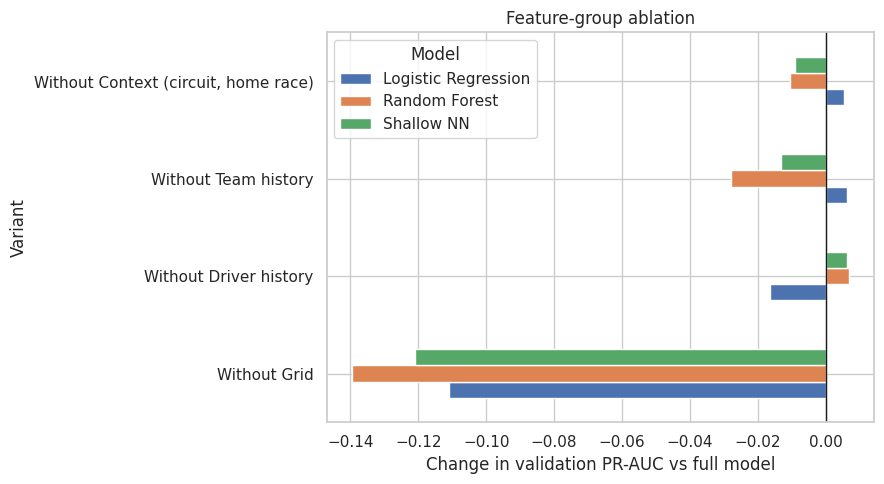

In [60]:
feature_groups = {
    "Grid": ["grid_position"],
    "Driver history": ["driver_experience", "driver_recent_podium_rate"],
    "Team history": ["constructor_recent_podium_rate"],
    "Context (circuit, home race)": ["circuitId", "home_race"],
}

def split_types(cols):
    return ([c for c in numeric_features if c in cols],
            [c for c in binary_features if c in cols],
            [c for c in categorical_features if c in cols])

def lr_val_probs(cols):
    num, bi, cat = split_types(cols)
    model = Pipeline([
        ("pre", build_preprocessor(num, bi, cat, scale=True)),
        ("clf", LogisticRegression(C=lr_params["C"], class_weight=lr_params["class_weight"],
                                   max_iter=2000, random_state=RANDOM_STATE)),
    ]).fit(X_train[cols], y_train)
    return [model.predict_proba(X_val[cols])[:, 1]]

def rf_val_probs(cols):
    num, bi, cat = split_types(cols)
    model = Pipeline([
        ("pre", build_preprocessor(num, bi, cat, scale=False)),
        ("clf", RandomForestClassifier(**rf_params, random_state=RANDOM_STATE, n_jobs=-1)),
    ]).fit(X_train[cols], y_train)
    return [model.predict_proba(X_val[cols])[:, 1]]

def nn_val_probs(cols, seeds=(42, 7, 123)):
    num, bi, cat = split_types(cols)
    pre = build_preprocessor(num, bi, cat, scale=True)
    Xtr = pre.fit_transform(X_train[cols]).to_numpy("float32")
    Xva = pre.transform(X_val[cols]).to_numpy("float32")
    cfg = nn_best["cfg"]
    outputs = []
    for seed in seeds:
        keras.utils.set_random_seed(seed)
        model = keras.Sequential([layers.Input(shape=(Xtr.shape[1],))])
        for units in cfg["hidden_units"]:
            model.add(layers.Dense(units, activation="relu"))
            if cfg["dropout"] > 0:
                model.add(layers.Dropout(cfg["dropout"]))
        model.add(layers.Dense(1, activation="sigmoid"))
        model.compile(optimizer=keras.optimizers.Adam(cfg["learning_rate"]),
                      loss="binary_crossentropy")
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15,
                                             restore_best_weights=True)
        model.fit(Xtr, y_train.to_numpy("float32"),
                  validation_data=(Xva, y_val.to_numpy("float32")),
                  epochs=200, batch_size=64, callbacks=[stop], verbose=0)
        outputs.append(model.predict(Xva, verbose=0).ravel())
    return outputs

variants = {"Full model": list(feature_columns)}
for group, cols in feature_groups.items():
    variants[f"Without {group}"] = [c for c in feature_columns if c not in cols]

model_fns = {"Logistic Regression": lr_val_probs,
             "Random Forest": rf_val_probs,
             "Shallow NN": nn_val_probs}

ablation_rows = []
for variant, cols in variants.items():
    for model_name, fn in model_fns.items():
        scores = []
        for p in fn(cols):
            thr = best_f1_threshold(y_val, p)
            scores.append(evaluate(y_val, p, thr))
        scores = pd.DataFrame(scores)
        ablation_rows.append({
            "Variant": variant, "Model": model_name, "n_features": len(cols),
            "PR-AUC": scores["PR-AUC"].mean(), "PR-AUC std (seeds)": scores["PR-AUC"].std(ddof=0),
            "ROC-AUC": scores["ROC-AUC"].mean(), "F1": scores["F1"].mean(),
        })
    print("done:", variant)

ablation = pd.DataFrame(ablation_rows)

# Sanity: the deterministic models must reproduce the earlier full-model scores.
full = ablation[ablation["Variant"] == "Full model"].set_index("Model")
assert abs(full.loc["Logistic Regression", "PR-AUC"] - average_precision_score(y_val, lr_val)) < 1e-4
assert abs(full.loc["Random Forest", "PR-AUC"] - average_precision_score(y_val, rf_val)) < 1e-4

# Change in PR-AUC relative to the full model.
full_pr = full["PR-AUC"]
ablation["Delta PR-AUC vs full"] = ablation.apply(
    lambda r: r["PR-AUC"] - full_pr[r["Model"]], axis=1)

display(ablation.round(4))

pivot = ablation.pivot(index="Variant", columns="Model", values="Delta PR-AUC vs full")
pivot = pivot.loc[[v for v in variants if v != "Full model"]]
print("Change in validation PR-AUC when a group is removed (negative = the group helped):")
display(pivot.round(4))

pivot.plot(kind="barh", figsize=(9, 5))
plt.axvline(0, color="k", lw=1)
plt.xlabel("Change in validation PR-AUC vs full model")
plt.title("Feature-group ablation")
plt.tight_layout()
plt.show()

#### 3.6 Findings

Change in validation PR-AUC when a feature group is removed (negative = the group helped). Full-model PR-AUC: LR 0.713, RF 0.724, NN 0.735 (mean of 3 seeds).

| Removed group | Logistic Regression | Random Forest | Shallow NN |
|---|---|---|---|
| **Grid** | **−0.111** | **−0.140** | **−0.121** |
| Driver history | −0.016 | +0.007 | +0.006 |
| Team history | +0.006 | −0.028 | −0.013 |
| Context (circuit, home race) | +0.005 | −0.011 | −0.009 |

- **Starting grid position is by far the most important group.** Removing it costs 0.11–0.14 PR-AUC in all three models, about ten times the noise level (bootstrap intervals were about ±0.09 wide, but differences between models were about 0.01–0.02; the seed-to-seed standard deviation of the NN is 0.001–0.010). This agrees with the exploratory plots, where the podium rate fell from about 79% at P1 to below 3% from P9.
- **The form features alone still carry real information.** Without the grid, PR-AUC is still 0.58–0.61, far above the 0.15 prevalence, so recent driver and team form identify likely podium finishers on their own.
- **The other groups matter much less and the effects are inconsistent between models.** Removing driver history even slightly improves the RF and NN (+0.006 to +0.007), which is within noise. A likely reason is redundancy: driver form and constructor form are strongly correlated (ρ = 0.87), so the remaining form feature and the grid already cover most of the information. Team history is the largest of the minor effects for the RF (−0.028) and NN (−0.013) but not for Logistic Regression (+0.006). Context (circuit and home race) changes the score by about 0.01 or less in every model, consistent with its flat exploratory plots.
- **Caveats.** Correlated features can substitute for each other, so a small drop does not mean a group is useless. All results are on the 2019–2021 validation set with hyperparameters fixed from the full model. A drop shows what the model relies on for prediction, not what causes podium finishes.
- **Decision.** We keep all six features for the final model. The minor groups changed scores by amounts within noise, and the feature set was fixed before the ablation, so removing features based on validation scores would risk tuning to the validation set.

### 3.7 Preprocessing-Order Experiments

Each experiment changes **only the order of two operations**. The rows, features, model settings and evaluation are identical. We use Logistic Regression (selected `C`) and the selected Shallow NN (3 seeds), because both are sensitive to feature scale. The Random Forest ignores scaling, so it is left out. The threshold is re-chosen on the validation set for each variant. All learned transformations are fitted on training data only, except in the deliberately incorrect variant of Experiment 2.

| Experiment | Pipeline A | Pipeline B | Hypothesis (written before running) |
|---|---|---|---|
| 1. Impute and scale | Impute the median, then standardize | Standardize using observed values only, then impute the median | Almost no difference. Only 0.3–1.5% of training values are missing, and the median lands at the same place in both, so only the learned scale differs slightly |
| 2. Fit before or after the split | Fit all preprocessing on the training set only (correct) | Fit preprocessing on all rows, then split (leaky) | Little or no measurable difference, but B is invalid: it uses validation and test feature distributions |
| 3. Scale and encode | Scale numeric columns, one-hot encode circuits separately (circuit columns stay 0/1) | One-hot encode first, then standardize every column including the circuit columns | B may inflate rare circuits (a rare circuit's 1 becomes a very large value) and could hurt, particularly the NN |

Pipeline A is identical in all three experiments, so every comparison is against the same reference.

Experiment 1: learned scales differ slightly; imputed point is the same median in both orders.


,std used by A (after imputing),std used by B (observed only),ratio B/A
grid_position,6.2456,6.2539,1.0013
driver_experience,62.0508,62.0508,1.0000
driver_recent_podium_rate,0.2512,0.2525,1.0052
constructor_recent_podium_rate,0.2275,0.2281,1.0028


Experiment 2: correct pipeline has 40 columns, leaky one has 47 (it created columns for circuits that never occur in training).


,Experiment,Pipeline,Model,n_columns,PR-AUC,PR-AUC std (seeds),ROC-AUC,F1,Precision,Recall,Delta PR-AUC vs A,Delta F1 vs A
0,Reference,A,Logistic Regression,40,0.7115,0.0000,0.9228,0.7300,0.6636,0.8111,0.0000,0.0000
1,Reference,A,Shallow NN,40,0.7378,0.0104,0.9300,0.7204,0.6768,0.7704,0.0000,0.0000
2,1. Impute vs scale order,B: scale then impute,Logistic Regression,40,0.7127,0.0000,0.9226,0.7332,0.6652,0.8167,0.0012,0.0032
3,1. Impute vs scale order,B: scale then impute,Shallow NN,40,0.7349,0.0114,0.9300,0.7214,0.6830,0.7648,-0.0029,0.0010
4,2. Fit before vs after split,B: fit on all rows (leaky),Logistic Regression,47,0.7128,0.0000,0.9226,0.7332,0.6652,0.8167,0.0013,0.0032
5,2. Fit before vs after split,B: fit on all rows (leaky),Shallow NN,47,0.7379,0.0099,0.9302,0.7257,0.6894,0.7667,0.0001,0.0053
6,3. Scale vs encode order,B: encode then scale all,Logistic Regression,40,0.7085,0.0000,0.9222,0.7304,0.6535,0.8278,-0.0030,0.0004
7,3. Scale vs encode order,B: encode then scale all,Shallow NN,40,0.7101,0.0027,0.9211,0.7209,0.6835,0.7630,-0.0276,0.0006


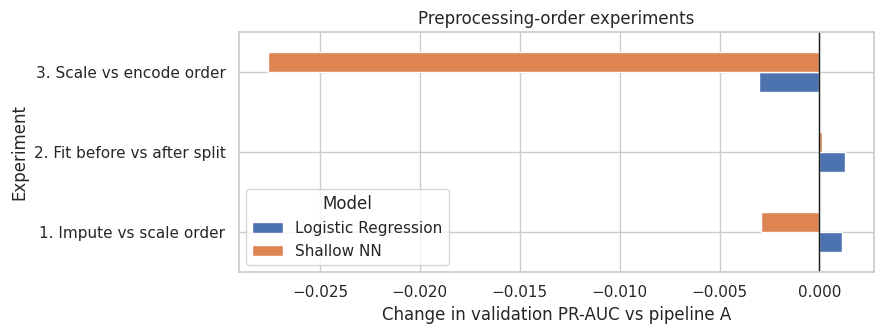

In [61]:
from sklearn.impute import MissingIndicator

SEEDS = (42, 7, 123)

def exp_preprocessor(num_order="impute_then_scale"):
    """Numeric steps in the chosen order. Missing indicators are built identically
    in both orders and are never scaled, so only the order differs."""
    if num_order == "impute_then_scale":
        vals = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
    else:  # scale with observed values only (NaN is ignored), then impute
        vals = Pipeline([("scale", StandardScaler()),
                         ("impute", SimpleImputer(strategy="median"))])
    return ColumnTransformer([
        ("num", vals, numeric_features),
        ("num_missing", MissingIndicator(features="missing-only"), numeric_features),
        ("bin", SimpleImputer(strategy="most_frequent", add_indicator=True), binary_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ])

def to_arrays(pre, fit_X=None):
    pre.fit(X_train if fit_X is None else fit_X)
    return (np.asarray(pre.transform(X_train), dtype="float32"),
            np.asarray(pre.transform(X_val), dtype="float32"))

def fit_predict_nn(Xtr, Xva, seed):
    cfg = nn_best["cfg"]
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([layers.Input(shape=(Xtr.shape[1],))])
    for units in cfg["hidden_units"]:
        model.add(layers.Dense(units, activation="relu"))
        if cfg["dropout"] > 0:
            model.add(layers.Dropout(cfg["dropout"]))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(cfg["learning_rate"]), loss="binary_crossentropy")
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    model.fit(Xtr, y_train.to_numpy("float32"),
              validation_data=(Xva, y_val.to_numpy("float32")),
              epochs=200, batch_size=64, callbacks=[stop], verbose=0)
    return model.predict(Xva, verbose=0).ravel()

def score_variant(experiment, pipeline, Xtr, Xva):
    rows = []
    # Logistic Regression (deterministic)
    lr = LogisticRegression(C=lr_params["C"], class_weight=lr_params["class_weight"],
                            max_iter=2000, random_state=RANDOM_STATE).fit(Xtr, y_train)
    p = lr.predict_proba(Xva)[:, 1]
    rows.append({"Experiment": experiment, "Pipeline": pipeline, "Model": "Logistic Regression",
                 "n_columns": Xtr.shape[1], "PR-AUC std (seeds)": 0.0,
                 **evaluate(y_val, p, best_f1_threshold(y_val, p))})
    # Shallow NN (average over seeds)
    per_seed = []
    for seed in SEEDS:
        p = fit_predict_nn(Xtr, Xva, seed)
        per_seed.append(evaluate(y_val, p, best_f1_threshold(y_val, p)))
    per_seed = pd.DataFrame(per_seed)
    rows.append({"Experiment": experiment, "Pipeline": pipeline, "Model": "Shallow NN",
                 "n_columns": Xtr.shape[1], "PR-AUC std (seeds)": per_seed["PR-AUC"].std(ddof=0),
                 **per_seed.mean().to_dict()})
    return rows

results = []

# Reference pipeline A (same in all experiments).
XtrA, XvaA = to_arrays(exp_preprocessor("impute_then_scale"))
results += score_variant("Reference", "A", XtrA, XvaA)

# Experiment 1: impute -> scale (A)  vs  scale -> impute (B).
preA = exp_preprocessor("impute_then_scale").fit(X_train)
preB = exp_preprocessor("scale_then_impute").fit(X_train)
scale_check = pd.DataFrame({
    "std used by A (after imputing)": preA.named_transformers_["num"].named_steps["scale"].scale_,
    "std used by B (observed only)": preB.named_transformers_["num"].named_steps["scale"].scale_,
}, index=numeric_features)
scale_check["ratio B/A"] = scale_check.iloc[:, 1] / scale_check.iloc[:, 0]
print("Experiment 1: learned scales differ slightly; imputed point is the same median in both orders.")
display(scale_check.round(4))
Xtr1, Xva1 = to_arrays(exp_preprocessor("scale_then_impute"))
results += score_variant("1. Impute vs scale order", "B: scale then impute", Xtr1, Xva1)

# Experiment 2: fit preprocessing on ALL rows before splitting (leaky).
all_X = pd.concat([X_train, X_val, X_test])
Xtr2, Xva2 = to_arrays(exp_preprocessor("impute_then_scale"), fit_X=all_X)
results += score_variant("2. Fit before vs after split", "B: fit on all rows (leaky)", Xtr2, Xva2)
print(f"Experiment 2: correct pipeline has {XtrA.shape[1]} columns, leaky one has {Xtr2.shape[1]} "
      "(it created columns for circuits that never occur in training).")

# Experiment 3: one-hot encode first, then scale every column.
pre3 = Pipeline([("prep", exp_preprocessor("impute_then_scale")), ("scale_all", StandardScaler())])
Xtr3, Xva3 = to_arrays(pre3)
results += score_variant("3. Scale vs encode order", "B: encode then scale all", Xtr3, Xva3)

order_results = pd.DataFrame(results)
ref = order_results[order_results["Experiment"] == "Reference"].set_index("Model")
order_results["Delta PR-AUC vs A"] = order_results.apply(
    lambda r: r["PR-AUC"] - ref.loc[r["Model"], "PR-AUC"], axis=1)
order_results["Delta F1 vs A"] = order_results.apply(
    lambda r: r["F1"] - ref.loc[r["Model"], "F1"], axis=1)

cols = ["Experiment", "Pipeline", "Model", "n_columns", "PR-AUC", "PR-AUC std (seeds)",
        "ROC-AUC", "F1", "Precision", "Recall", "Delta PR-AUC vs A", "Delta F1 vs A"]
display(order_results[cols].round(4))

# Plot the change in PR-AUC relative to the reference.
plot_df = order_results[order_results["Experiment"] != "Reference"]
plot_df = plot_df.pivot(index="Experiment", columns="Model", values="Delta PR-AUC vs A")
plot_df.plot(kind="barh", figsize=(9, 3.5))
plt.axvline(0, color="k", lw=1)
plt.xlabel("Change in validation PR-AUC vs pipeline A")
plt.title("Preprocessing-order experiments")
plt.tight_layout()
plt.show()

#### 3.7 Findings

Reference pipeline A: Logistic Regression PR-AUC 0.7115, Shallow NN 0.7378 (mean of 3 seeds, seed standard deviation 0.010). This reference differs slightly from the 3.3 numbers because here the missing-indicator columns are built separately and left unscaled. Every comparison below is against this same reference.

| Experiment | Variant B | LR ΔPR-AUC | NN ΔPR-AUC | Conclusion |
|---|---|---|---|---|
| 1. Impute vs scale order | scale (observed values only), then impute | +0.001 | −0.003 | No meaningful difference |
| 2. Fit before vs after the split | fit on all rows, then split (leaky) | +0.001 | +0.000 | No measurable difference, but the method is invalid |
| 3. Scale vs encode order | one-hot encode first, then scale every column | −0.003 | **−0.028** | Worse, especially for the NN |

- **Experiment 1:** the learned scales differ by at most 0.5% between the two orders (ratio 1.000–1.005), because only 0.3–1.5% of training values are missing, and the median lands at the same place either way. The score changes (+0.001 and −0.003) are smaller than the seed-to-seed noise of the NN (0.010). So the order of imputation and scaling does not matter here. As the hypothesis said, the two orders are nearly equivalent when little data is missing.
- **Experiment 2:** the leaky pipeline scored the same as the correct one (differences ≤ 0.0013). The reason is that the scaler and imputer statistics hardly change when validation and test rows are added, and the extra circuit columns it created (47 columns vs 40, one for each circuit seen only in validation or test) are always zero in training, so the models learn nothing from them. The absence of a visible effect here does **not** make the method acceptable: fitting on all rows uses the distribution of future data, so we keep fitting on training data only. With features that changed more over time the leak could matter.
- **Experiment 3:** scaling the one-hot circuit columns after encoding lowered PR-AUC for both models: −0.003 for Logistic Regression and −0.028 for the NN, which is about 2.7 times the NN's seed noise (only 3 seeds, so this is suggestive, not conclusive). F1 stayed the same (0.7209 vs 0.7204 for the NN), so the ranking got worse while the chosen threshold hid it. A plausible explanation is that standardizing a rare 0/1 column turns its 1s into very large values (a circuit seen in 1% of rows becomes about 10 standard deviations), which gives rare circuits a disproportionate influence. We did not test this explanation directly. We keep Pipeline A: scale the numeric columns, leave one-hot columns as 0/1.
- **Decision:** the final pipeline is Pipeline A (impute, then scale numeric features; one-hot circuits left unscaled), fitted on training data only.

### 3.8 Final Model, Test Evaluation and Handover

**Decisions frozen before looking at the test set:**
- **Final model:** the Shallow NN (two hidden layers of 32 and 16 units, dropout 0.3). It had the highest validation PR-AUC (0.739), which was our pre-declared selection rule. The three models are statistically indistinguishable on validation (all bootstrap difference intervals include zero), so this choice is a convention, not proof of superiority, and we report all three models.
- **Features:** all six pre-race features. The ablation did not justify removing any group.
- **Preprocessing:** impute (median, missing indicators), standardize numeric features, one-hot encode circuits, all fitted on the training set.
- **Threshold:** each model's own F1-optimal threshold from the validation set (NN: 0.472).

The unseen 2022–2024 test set is now evaluated **once** for all three models with these frozen choices. Nothing is tuned after this step.

In [62]:
# Frozen final pipeline.
final_name = "Shallow NN"
final_model = nn_model
final_preprocessor = nn_pre            # fitted on training data only
final_feature_columns = list(feature_columns)
final_threshold = nn_threshold

def final_predict_proba(X_raw):
    """Podium probability from RAW pre-race features (a DataFrame with the six columns)."""
    X_raw = X_raw[final_feature_columns]
    Xt = final_preprocessor.transform(X_raw).to_numpy("float32")
    return final_model.predict(Xt, verbose=0).ravel()

# The wrapper must reproduce the validation probabilities from earlier exactly.
assert np.allclose(final_predict_proba(X_val), nn_val, atol=1e-6)
print("Frozen:", final_name, "| features:", final_feature_columns,
      f"| threshold: {final_threshold:.3f}")

Frozen: Shallow NN | features: ['grid_position', 'driver_experience', 'driver_recent_podium_rate', 'constructor_recent_podium_rate', 'circuitId', 'home_race'] | threshold: 0.472


,Model,Split,Threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression (baseline),Train,0.303,0.922,0.675,0.663,0.592,0.753
1,Logistic Regression (baseline),Validation,0.303,0.924,0.713,0.731,0.662,0.817
2,Logistic Regression (baseline),Test,0.303,0.929,0.687,0.679,0.591,0.799
3,Random Forest,Train,0.338,0.927,0.690,0.646,0.661,0.632
4,Random Forest,Validation,0.338,0.927,0.724,0.721,0.704,0.739
5,Random Forest,Test,0.338,0.929,0.694,0.643,0.629,0.657
6,Shallow NN,Train,0.472,0.938,0.714,0.659,0.676,0.642
7,Shallow NN,Validation,0.472,0.931,0.739,0.717,0.691,0.744
8,Shallow NN,Test,0.472,0.931,0.673,0.656,0.628,0.686
9,Constant predictor (reference),Test,0.140,0.500,0.150,0.261,0.150,1.000


PR-AUC validation -> test:


Split,Test,Validation,change
Model,,,
Constant predictor (reference),0.150,NaN,NaN
Logistic Regression (baseline),0.687,0.713,-0.026
Random Forest,0.694,0.724,-0.030
Shallow NN,0.673,0.739,-0.066


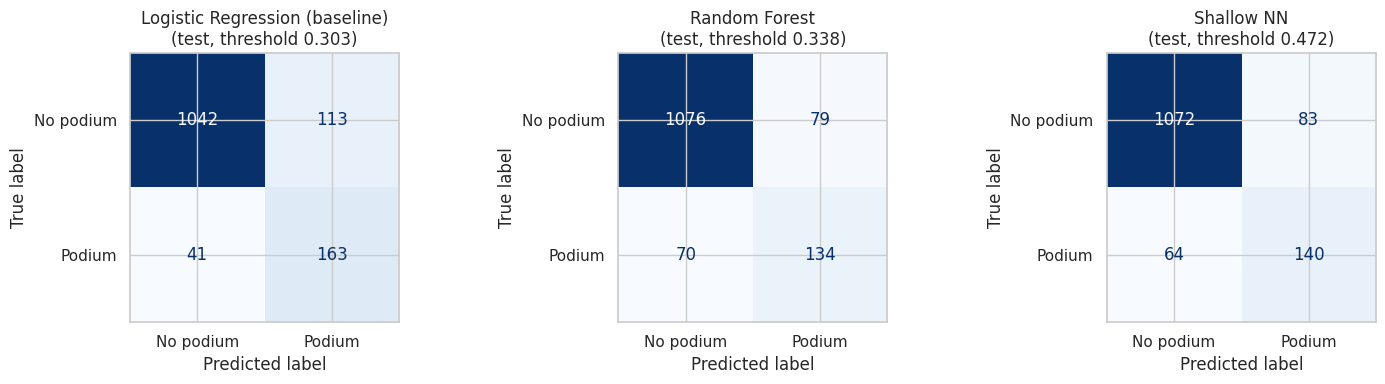

Bootstrap over test races:


,PR-AUC (point),95% CI low,95% CI high
Logistic Regression (baseline),0.687,0.626,0.755
Random Forest,0.694,0.635,0.755
Shallow NN,0.673,0.612,0.741


In [63]:
test_probs = {
    "Logistic Regression (baseline)": lr_model.predict_proba(X_test)[:, 1],
    "Random Forest": rf_model.predict_proba(X_test)[:, 1],
    "Shallow NN": final_predict_proba(X_test),
}
model_thresholds = {
    "Logistic Regression (baseline)": lr_threshold,
    "Random Forest": rf_threshold,
    "Shallow NN": final_threshold,
}

# Full comparison table: train, validation and test, all five metrics.
rows = []
for name, (p_tr, p_va, thr) in models_eval.items():
    p_te = test_probs[name]
    for split, y, p in [("Train", y_train, p_tr), ("Validation", y_val, p_va), ("Test", y_test, p_te)]:
        rows.append({"Model": name, "Split": split, "Threshold": round(thr, 3), **evaluate(y, p, thr)})

# Constant-rate reference on test.
p_const = dummy.predict_proba(X_test)[:, 1]
rows.append({"Model": "Constant predictor (reference)", "Split": "Test",
             "Threshold": round(dummy_threshold, 3), **evaluate(y_test, p_const, dummy_threshold)})

final_comparison = pd.DataFrame(rows)
display(final_comparison.round(3))

# Change from validation to test (era shift, 2019-2021 -> 2022-2024).
wide = final_comparison[final_comparison["Split"].isin(["Validation", "Test"])]
shift = (wide.pivot(index="Model", columns="Split", values="PR-AUC")
         .assign(change=lambda d: d["Test"] - d["Validation"]))
print("PR-AUC validation -> test:")
display(shift.round(3))

# Confusion matrices on test.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax_, (name, p) in zip(axes, test_probs.items()):
    pred = (p >= model_thresholds[name]).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["No podium", "Podium"], cmap="Blues", ax=ax_, colorbar=False)
    ax_.set_title(f"{name}\n(test, threshold {model_thresholds[name]:.3f})")
plt.tight_layout(); plt.show()

# Bootstrap over test races for PR-AUC.
rng = np.random.default_rng(RANDOM_STATE)
test_races = test_data["raceId"].to_numpy()
race_ids_t = np.unique(test_races)
idx_by_race_t = {r: np.where(test_races == r)[0] for r in race_ids_t}
yt = y_test.to_numpy()
boot_t = {name: [] for name in test_probs}
for _ in range(1000):
    sampled = rng.choice(race_ids_t, size=len(race_ids_t), replace=True)
    idx = np.concatenate([idx_by_race_t[r] for r in sampled])
    for name, p in test_probs.items():
        boot_t[name].append(average_precision_score(yt[idx], p[idx]))
ci_test = pd.DataFrame({
    name: {"PR-AUC (point)": average_precision_score(yt, test_probs[name]),
           "95% CI low": np.percentile(b, 2.5), "95% CI high": np.percentile(b, 97.5)}
    for name, b in boot_t.items()
}).T
print("Bootstrap over test races:")
display(ci_test.round(3))

#### 3.8 Test results (2022–2024, evaluated once)

| Model | ROC-AUC | PR-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|
| Logistic Regression (baseline) | 0.929 | 0.687 | 0.679 | 0.591 | 0.799 |
| Random Forest | 0.929 | 0.694 | 0.643 | 0.629 | 0.657 |
| Shallow NN (frozen final model) | 0.931 | 0.673 | 0.656 | 0.628 | 0.686 |
| Constant predictor (reference) | 0.500 | 0.150 | 0.261 | 0.150 | 1.000 |

- **All three models generalize well above the reference:** PR-AUC 0.67–0.69 vs 0.15 and ROC-AUC about 0.93 on unseen races.
- **The validation ranking did not carry over.** The NN had the best validation PR-AUC (0.739) but the lowest test PR-AUC (0.673), a drop of 0.066, compared with drops of 0.026 (Logistic Regression) and 0.030 (Random Forest). The bootstrap intervals over test races (0.61–0.76) overlap almost completely, so the three models cannot be distinguished statistically on either validation or test.
- **Possible explanations (not tested directly):** (1) *Selection effect.* The NN was the best of four configurations and its training was stopped on validation loss, so its validation score is the most optimistic of the three. (2) *Period shift.* All three models lose about 0.03 PR-AUC on 2022–2024, which is a new regulation era; 19% of test rows are at circuits never seen in training and 5.6% have an unmapped home-race value. (3) *Seed variability.* The NN's seed-to-seed spread was about 0.01 PR-AUC, which is too small to explain a 0.066 drop on its own.
- **At the thresholds fixed on validation**, Logistic Regression finds the most podiums (163 of 204) at the cost of the most false alarms (113), while the Random Forest and NN are more conservative (134 and 140 found, 79 and 83 false alarms). Logistic Regression has the best test F1 (0.679). Precision fell for every model compared with validation (for example 0.662 to 0.591 for Logistic Regression).
- **Decision.** The final model was fixed on validation evidence before the test set was used, so we keep the Shallow NN as the reported final model and do not re-select after seeing test scores. The honest conclusion is that the simple Logistic Regression and the Random Forest perform at least as well as the neural network on unseen races, so the extra complexity of the NN is not justified by this data. All three models are handed over for explanation.
- **Evaluation protocol.** Form features for validation and test rows are built from earlier races in sequence, so each prediction uses only results available before that race. This is a continuously updated forecasting setup, not a model frozen at the end of 2018.

#### Handover to explainability

The objects below are ready for Teammate 4 (permutation importance, SHAP, LIME, inference):

| Object | Meaning |
|---|---|
| `final_model`, `final_preprocessor` | Shallow NN (Keras) and the training-fitted preprocessing |
| `final_predict_proba(X_raw)` | Podium probability from a DataFrame with the six raw pre-race columns |
| `final_feature_columns`, `final_threshold` | Required input columns and the validation-chosen threshold (0.472) |
| `lr_model`, `rf_model` | Fitted sklearn pipelines (raw features in, `predict_proba` out), if explanations of the other models are wanted |
| `handoff_examples` | Real test rows covering a true positive, a false positive, a missed podium, a true negative and a row with missing inputs |

Inputs must contain only information available after qualifying. Race-result fields are never accepted. A circuit not seen in training is encoded as all zeros, and missing values are imputed with the training medians (and flagged by the missing indicators).

In [64]:
import os, joblib

assert np.allclose(final_predict_proba(X_test), test_probs["Shallow NN"], atol=1e-6)

# Real test rows covering the main cases, in original (untransformed) units.
examples = X_test.copy()
examples[["year", "raceId", "driverId"]] = test_data[["year", "raceId", "driverId"]]
examples["true_podium"] = y_test
examples["podium_probability"] = test_probs["Shallow NN"]
examples["predicted_podium"] = (examples["podium_probability"] >= final_threshold).astype(int)

def pick(mask, ascending=False):
    return examples[mask].sort_values("podium_probability", ascending=ascending).head(1)

has_missing = examples[final_feature_columns].isna().any(axis=1)
handoff_examples = pd.concat([
    pick((examples.true_podium == 1) & (examples.predicted_podium == 1)).assign(case="True positive (most confident)"),
    pick((examples.true_podium == 0) & (examples.predicted_podium == 1)).assign(case="False positive (most confident)"),
    pick((examples.true_podium == 1) & (examples.predicted_podium == 0)).assign(case="Missed podium (closest to threshold)"),
    pick((examples.true_podium == 0) & (examples.predicted_podium == 0), ascending=True).assign(case="True negative (most confident)"),
    pick(has_missing).assign(case="Input with missing values"),
])
display(handoff_examples[["case", "year", "raceId", "driverId"] + final_feature_columns
                         + ["podium_probability", "predicted_podium", "true_podium"]].round(3))

# Save the fitted objects as files too (they appear under Output in Kaggle).
os.makedirs("/kaggle/working/final_artifacts", exist_ok=True)
final_model.save("/kaggle/working/final_artifacts/final_nn.keras")
joblib.dump(final_preprocessor, "/kaggle/working/final_artifacts/final_preprocessor.joblib")
joblib.dump(lr_model, "/kaggle/working/final_artifacts/logistic_regression.joblib")
joblib.dump(rf_model, "/kaggle/working/final_artifacts/random_forest.joblib")
joblib.dump({"feature_columns": final_feature_columns, "threshold": final_threshold},
            "/kaggle/working/final_artifacts/final_config.joblib")
print("Saved:", sorted(os.listdir("/kaggle/working/final_artifacts")))

,case,year,raceId,driverId,grid_position,driver_experience,driver_recent_podium_rate,constructor_recent_podium_rate,circuitId,home_race,podium_probability,predicted_podium,true_podium
8177,True positive (most confident),2023,1105,830,1.0,169,1.0,0.8,4,0.0,0.825,1,1
7723,False positive (most confident),2022,1079,844,1.0,86,0.8,0.7,4,0.0,0.802,1,0
8664,Missed podium (closest to threshold),2024,1129,847,1.0,112,0.0,0.0,7,0.0,0.458,0,1
8685,True negative (most confident),2024,1130,848,NaN,90,0.0,0.0,4,NaN,0.000,0,0
7930,Input with missing values,2022,1089,856,8.0,0,NaN,0.0,14,0.0,0.118,0,0


Saved: ['final_config.joblib', 'final_nn.keras', 'final_preprocessor.joblib', 'logistic_regression.joblib', 'random_forest.joblib']


### 3.9 Summary and Limitations of the Modeling Stage

**Protocol.** The split is chronological (train 2003–2018, validation 2019–2021, test 2022–2024) because a real forecast always predicts the future from the past, and random splitting would let a model learn from races after the ones it is tested on. All preprocessing and hyperparameters were fitted or chosen on training and validation data only. The test set was evaluated once, after the final model, features, preprocessing and thresholds were frozen.

**What we found.**
- Starting grid position carries most of the predictive information. Removing it costs 0.11–0.14 PR-AUC in every model (3.6). Recent driver and team form add real but smaller information, and circuit and home race add almost nothing.
- Logistic Regression, Random Forest and the shallow neural network perform similarly: test PR-AUC 0.687, 0.694 and 0.673, against 0.150 for a constant predictor. Their bootstrap intervals overlap almost completely, so no model is demonstrably better. The simple baseline is as good as the more complex models.
- Preprocessing order barely matters when little data is missing (3.7). Scaling one-hot circuit columns after encoding was the only order choice that hurt, and mainly for the neural network.

**Limitations.**
- **Features.** The model uses grid position and form features only. It does not use qualifying lap times or championship standings, so it cannot see how fast a car was relative to the field in qualifying.
- **Era shift.** Every model lost about 0.03 PR-AUC from validation to test (the neural network lost 0.066). The 2022 regulation change, unseen circuits (19% of test rows) and unmapped home-race values (5.6% of test rows) may all contribute, but we did not isolate them.
- **Small evaluation sets.** Validation has 180 podiums and test has 204, so differences of about 0.02–0.03 PR-AUC are within noise. The bootstrap resamples races only; it does not capture variation from retraining.
- **Rows are not independent.** Exactly three drivers podium in each race, but the models score each driver separately. A ranking-per-race approach could use that constraint.
- **Cold start and history.** The cohort starts in 2003, so driver and team form is missing for the first race of the cohort and for new drivers. `driver_experience` counts entries since 2003, not lifetime starts. Form features for validation and test are updated sequentially from earlier races in the same period.
- **Thresholds.** Thresholds were chosen on 2019–2021 and not recalibrated for 2022–2024. Precision dropped for every model on the test set.
- **Overlapping features.** Driver form, team form and grid position are correlated (ρ up to 0.87), so small ablation changes in the minor groups are hard to attribute.
- Model importance describes what the model relies on, not what causes podium finishes.

In [65]:
import importlib.util

# Section 3 objects that this section depends on.
required_objects = [
    "final_model", "final_preprocessor", "final_predict_proba",
    "final_feature_columns", "final_threshold",
    "X_train", "y_train", "X_val", "y_val", "X_test", "y_test",
    "handoff_examples", "RANDOM_STATE",
]

for name in required_objects:
    print(f"{name}: {'available' if name in globals() else 'MISSING'}")

# The explainability libraries.
for package in ["shap", "lime"]:
    print(f"{package} installed: {importlib.util.find_spec(package) is not None}")

print("\nRaw model inputs:", final_feature_columns)
print("Final threshold:", round(final_threshold, 3))
print("Random seed:", RANDOM_STATE)

final_model: available
final_preprocessor: available
final_predict_proba: available
final_feature_columns: available
final_threshold: available
X_train: available
y_train: available
X_val: available
y_val: available
X_test: available
y_test: available
handoff_examples: available
RANDOM_STATE: available
shap installed: True
lime installed: True

Raw model inputs: ['grid_position', 'driver_experience', 'driver_recent_podium_rate', 'constructor_recent_podium_rate', 'circuitId', 'home_race']
Final threshold: 0.472
Random seed: 42


## 4. Model Explainability and Inference

This section explains the final model (the shallow neural network) with permutation importance and SHAP globally, and with local SHAP and LIME for individual predictions. It ends with an inference function that predicts for a single new record.

### 4.1 Setup and decisions

Decisions made before running any explanation:

- **Model explained:** the final shallow neural network, called through `final_predict_proba`, which takes the six raw features and returns a podium probability.
- **Data explained:** global explanations use the **validation set** (2019–2021). The test set was already used for the final scores, so it is not used to choose or tune anything here.
- **Background data:** a fixed random sample of 100 training rows (SHAP needs a reference to compare against).
- **Level of explanation:** the six raw features, not the 40 preprocessed columns, so circuit and missing-indicator columns are not split into many small pieces.
- **Local examples:** the five prepared rows in `handoff_examples` (2022–2024). They are only explained, never used for fitting or tuning.
- **Randomness:** every random step uses `RANDOM_STATE = 42`.

Before building anything, we check that the objects from Section 3 exist and that the `shap` and `lime` libraries are installed.

Baseline validation PR-AUC: 0.7391


,feature,mean_pr_auc_drop,std_pr_auc_drop
0,grid_position,0.3453,0.0295
1,driver_recent_podium_rate,0.0753,0.0274
2,circuitId,0.0275,0.0130
3,constructor_recent_podium_rate,0.0206,0.0095
4,home_race,0.0010,0.0021
5,driver_experience,-0.0028,0.0068


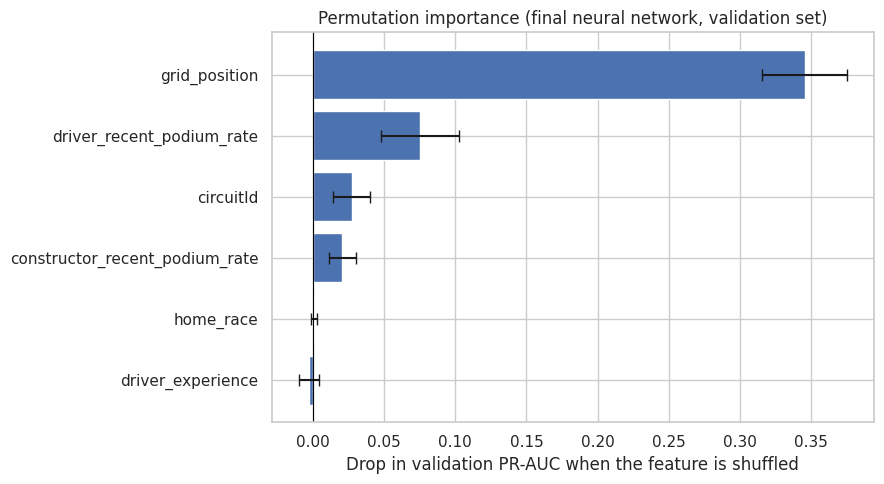

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

validation_raw = X_val[final_feature_columns].copy()

# Score before any shuffling.
baseline_pr_auc = average_precision_score(
    y_val, np.asarray(final_predict_proba(validation_raw)).reshape(-1)
)

rng = np.random.default_rng(RANDOM_STATE)
rows = []

for feature in final_feature_columns:
    drops = []
    for _ in range(10):
        shuffled = validation_raw.copy()
        # Shuffle only this feature; all other columns stay unchanged.
        shuffled[feature] = rng.permutation(shuffled[feature].to_numpy())
        probs = np.asarray(final_predict_proba(shuffled)).reshape(-1)
        # Positive drop = the model got worse without the real values.
        drops.append(baseline_pr_auc - average_precision_score(y_val, probs))
    rows.append({"feature": feature,
                 "mean_pr_auc_drop": np.mean(drops),
                 "std_pr_auc_drop": np.std(drops, ddof=1)})

perm_importance = (pd.DataFrame(rows)
                   .sort_values("mean_pr_auc_drop", ascending=False)
                   .reset_index(drop=True))

print("Baseline validation PR-AUC:", round(baseline_pr_auc, 4))
display(perm_importance.round(4))

# Plot with error bars (mean ± standard deviation over 10 shuffles).
plot_df = perm_importance.sort_values("mean_pr_auc_drop")
plt.figure(figsize=(9, 5))
plt.barh(plot_df["feature"], plot_df["mean_pr_auc_drop"],
         xerr=plot_df["std_pr_auc_drop"], capsize=4)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Drop in validation PR-AUC when the feature is shuffled")
plt.title("Permutation importance (final neural network, validation set)")
plt.tight_layout()
plt.show()

### 4.2 Global Explanation: Permutation Importance

Permutation importance shuffles one feature's values across the validation rows, leaves every other column unchanged, and measures how much PR-AUC falls. A large drop means the trained model relies on that feature; no drop means it does not. We shuffle each of the six raw features 10 times and report the mean and standard deviation of the drop. The model is not re-trained, so this tests the exact model we report. PR-AUC is used because it is the project's primary metric. 


#### 4.2 Findings

Baseline validation PR-AUC is 0.739. Values below are the drop in PR-AUC when one feature is shuffled (mean ± standard deviation over 10 shuffles).

| Feature | PR-AUC drop |
|---|---|
| `grid_position` | 0.345 ± 0.030 |
| `driver_recent_podium_rate` | 0.075 ± 0.027 |
| `circuitId` | 0.028 ± 0.013 |
| `constructor_recent_podium_rate` | 0.021 ± 0.010 |
| `home_race` | 0.001 ± 0.002 |
| `driver_experience` | −0.003 ± 0.007 |

- **The model relies mostly on starting grid position.** Shuffling it costs 0.345 PR-AUC, more than four times the next feature and far larger than the shuffle noise (about ±0.03). This agrees with the ablation in 3.6, where removing grid cost 0.12 for the neural network.
- **Driver recent form is second** (0.075). Constructor form shows a smaller drop (0.021), but driver and constructor form are strongly correlated (ρ = 0.87), so when one is shuffled the other still carries part of the information, and its importance is probably understated.
- **`circuitId` has a small but non-zero drop (0.028).** This is larger than the ablation suggested for the context group (about 0.01 or less). The two tests differ: permutation scrambles a feature in the model we already trained, while ablation re-trains without it. We did not test why they differ.
- **`home_race` and `driver_experience` show no reliance.** Their drops are within noise (the negative value for experience only reflects random variation).
- **Caveat.** These results describe how this trained model uses its inputs on the 2019–2021 validation set. They do not show that a feature causes podium finishes.

In [67]:
import shap

# Reference rows (training) and rows to explain (validation).
background_raw = X_train[final_feature_columns].sample(n=100, random_state=RANDOM_STATE)
explain_raw = X_val[final_feature_columns].sample(n=200, random_state=RANDOM_STATE)

print("Background sample:", background_raw.shape)
print("Explained sample:", explain_raw.shape)

# Explain the final model's predicted podium probability.
explainer = shap.Explainer(final_predict_proba, background_raw)
shap_values = explainer(explain_raw)

print("SHAP values shape:", shap_values.values.shape)
print("Average prediction on the background rows:",
      round(float(np.asarray(shap_values.base_values).reshape(-1)[0]), 3))

Background sample: (100, 6)
Explained sample: (200, 6)


ExactExplainer explainer: 201it [01:15,  2.59it/s]

SHAP values shape: (200, 6)
Average prediction on the background rows: 0.151


### 4.3 Global Explanation: SHAP

SHAP splits each prediction into a starting value (the average prediction on a reference set) plus one contribution per feature. A positive value pushes the podium probability up for that row; a negative value pushes it down. Averaging the absolute contributions over many rows gives a global importance in probability units, and plotting the signed values shows the direction of each feature's effect.

We use 100 randomly sampled **training** rows as the reference (background) and explain 200 randomly sampled **validation** rows. Both samples use `RANDOM_STATE = 42`. Explaining the six raw features directly lets the model's own pipeline handle missing values.

,feature,mean_abs_shap
0,grid_position,0.12072
1,driver_recent_podium_rate,0.06038
2,constructor_recent_podium_rate,0.03404
3,circuitId,0.01347
4,driver_experience,0.00847
5,home_race,0.00272


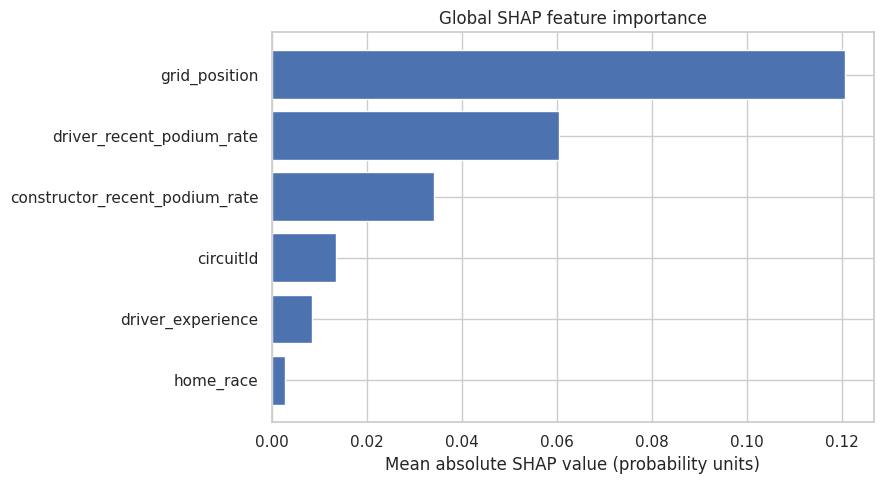

/tmp/ipykernel_16/682144054.py:17: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values.values, explain_raw,


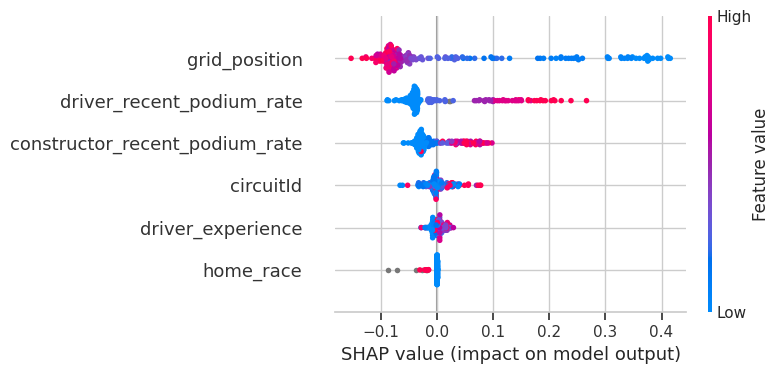

In [68]:
# Average absolute contribution per feature.
shap_importance = (pd.DataFrame({
        "feature": final_feature_columns,
        "mean_abs_shap": np.abs(shap_values.values).mean(axis=0)})
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True))
display(shap_importance.round(5))

plt.figure(figsize=(9, 5))
plt.barh(shap_importance["feature"][::-1], shap_importance["mean_abs_shap"][::-1])
plt.xlabel("Mean absolute SHAP value (probability units)")
plt.title("Global SHAP feature importance")
plt.tight_layout()
plt.show()

# Direction of each feature's effect.
shap.summary_plot(shap_values.values, explain_raw,
                  feature_names=final_feature_columns, show=True)

#### 4.3 Global SHAP results

The bar chart ranks features by their average absolute contribution to the predicted probability. The beeswarm plot shows each explained row as a dot: its position is the SHAP value (right pushes toward a podium) and its color is the feature value (red high, blue low). Colors for `circuitId` carry no meaning, because it is an ID label and not a quantity.

#### 4.3 Findings

Mean absolute SHAP value (average change in predicted podium probability): `grid_position` 0.121, `driver_recent_podium_rate` 0.060, `constructor_recent_podium_rate` 0.034, `circuitId` 0.013, `driver_experience` 0.008, `home_race` 0.003.

- **Grid position again dominates.** On average it moves the predicted probability by about 12 percentage points, twice as much as any other feature.
- **Direction matches intuition.** Starting near the front of the grid (low grid numbers) pushes the probability up, by as much as +0.4, while starting at the back pushes it down. High recent podium rates of the driver and the constructor push it up.
- **Same top group as permutation importance.** Grid position first and driver form second agree. The order of the middle features differs: SHAP puts constructor form third and circuit fourth, while permutation importance reverses them. Their contributions are small in both methods, and the two methods answer different questions (how far predictions move versus how much the score falls when a feature is scrambled), so we do not rank them against each other.
- **`home_race` and `driver_experience` contribute almost nothing**, consistent with the flat home-advantage result in Section 2.2 and the near-zero ablation effect.
- **Caveat.** SHAP describes how the model uses its inputs, not how the sport works. Correlated features (driver form, constructor form and grid) share credit, so individual bars should not be over-interpreted.

=== True positive (most confident) ===
Actual podium: 1 | Predicted probability: 0.825 | Predicted podium: 1


,feature,value,shap
0,grid_position,1.0,0.377
2,driver_recent_podium_rate,1.0,0.187
3,constructor_recent_podium_rate,0.8,0.060
4,circuitId,4.0,0.031
1,driver_experience,169.0,0.019
5,home_race,0.0,0.001


Starting value + sum of contributions = 0.825


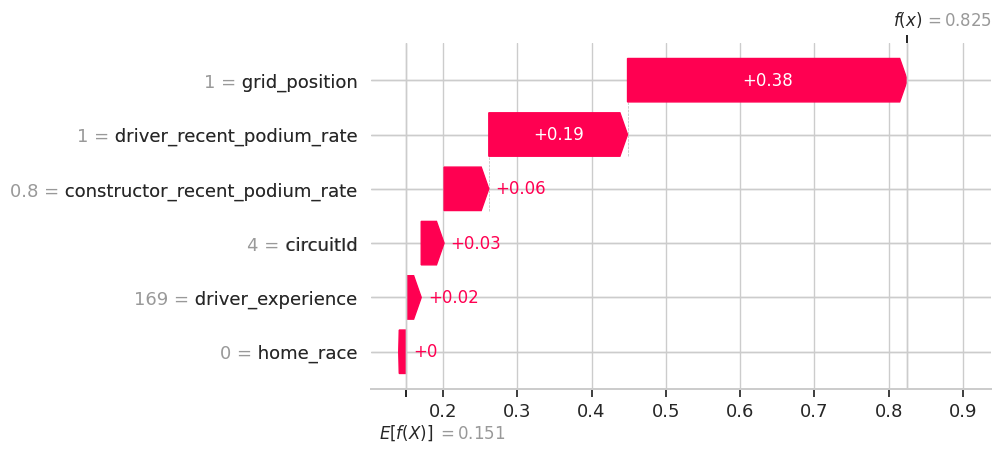

=== False positive (most confident) ===
Actual podium: 0 | Predicted probability: 0.802 | Predicted podium: 1


,feature,value,shap
0,grid_position,1.0,0.387
2,driver_recent_podium_rate,0.8,0.159
3,constructor_recent_podium_rate,0.7,0.067
4,circuitId,4.0,0.029
1,driver_experience,86.0,0.009
5,home_race,0.0,0.001


Starting value + sum of contributions = 0.802


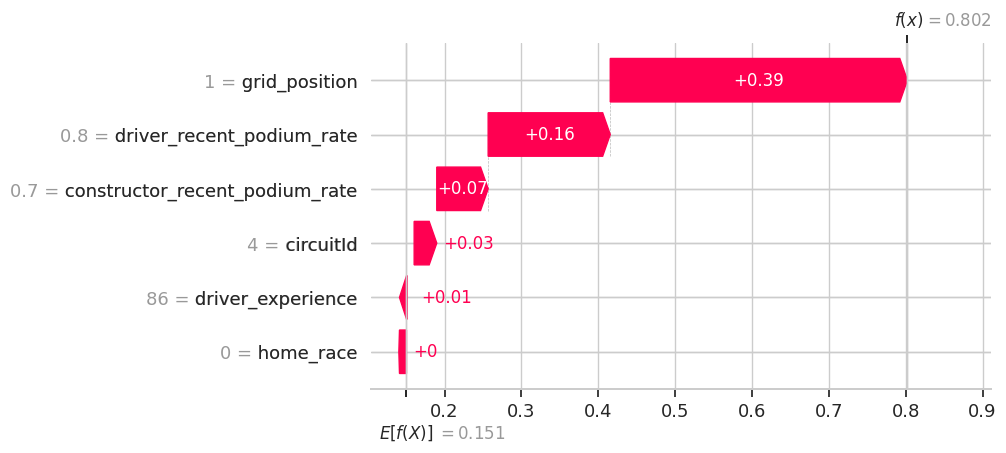

=== Missed podium (closest to threshold) ===
Actual podium: 1 | Predicted probability: 0.458 | Predicted podium: 0


,feature,value,shap
0,grid_position,1.0,0.358
2,driver_recent_podium_rate,0.0,-0.056
3,constructor_recent_podium_rate,0.0,-0.029
1,driver_experience,112.0,0.028
4,circuitId,7.0,0.006
5,home_race,0.0,0.001


Starting value + sum of contributions = 0.458


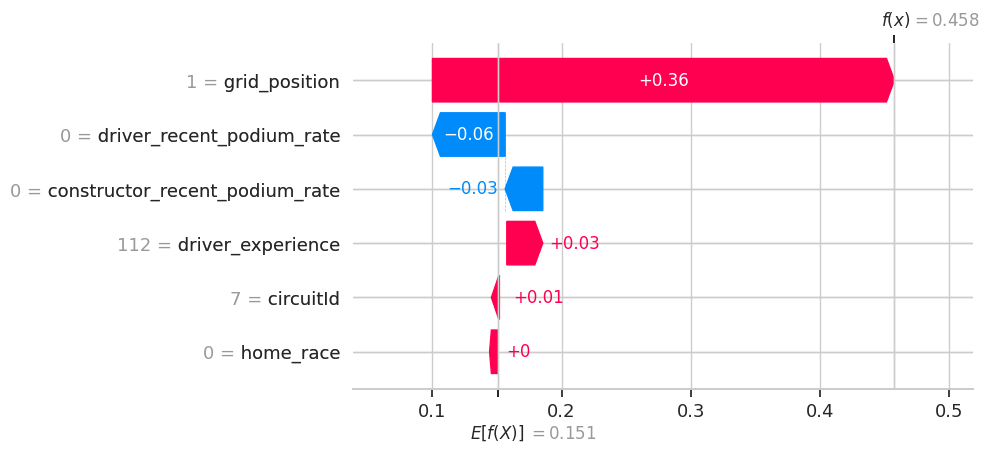

In [69]:
# Explainer for single rows (numeric arrays avoid dtype problems with SHAP).
background_array = background_raw.apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float64)
local_explainer = shap.Explainer(
    lambda x: final_predict_proba(pd.DataFrame(x, columns=final_feature_columns)),
    background_array
)

def explain_local(case_name):
    row = handoff_examples.loc[handoff_examples["case"] == case_name].iloc[0]
    raw = handoff_examples.loc[[row.name], final_feature_columns].apply(pd.to_numeric, errors="coerce")
    arr = raw.to_numpy(dtype=np.float64)

    exp = local_explainer(arr)
    base = float(np.asarray(exp.base_values).reshape(-1)[0])
    values = exp.values[0]

    print(f"=== {case_name} ===")
    print("Actual podium:", int(row["true_podium"]),
          "| Predicted probability:", round(float(row["podium_probability"]), 3),
          "| Predicted podium:", int(row["predicted_podium"]))
    table = pd.DataFrame({"feature": final_feature_columns,
                          "value": arr[0], "shap": values})
    display(table.sort_values("shap", key=lambda s: s.abs(), ascending=False).round(3))
    print("Starting value + sum of contributions =", round(base + values.sum(), 3))

    shap.plots.waterfall(shap.Explanation(
        values=values, base_values=base, data=arr[0],
        feature_names=final_feature_columns))

explain_local("True positive (most confident)")
explain_local("False positive (most confident)")
explain_local("Missed podium (closest to threshold)")

### 4.4 Local Explanations

Global plots show average behaviour. Local explanations show why the model made one particular prediction. We use three of the prepared rows from `handoff_examples`: a correct podium prediction (true positive), a wrong podium prediction (false positive) and a podium the model missed (probability just below the 0.472 threshold). These rows come from 2022–2024; they are only explained and never used for fitting or tuning.

#### 4.4.1 Local SHAP

A waterfall plot starts at the average prediction and adds each feature's contribution until it reaches the model's prediction for this row.
#### 4.4.1 Findings

The average prediction (starting value) is 0.151. For each row, the starting value plus the six contributions equals the model's probability.

- **True positive (probability 0.825).** The driver started on pole, had a perfect recent podium rate (1.0) and a team with 0.8 recent form. Grid position adds +0.377, driver form +0.187, constructor form +0.060, circuit +0.031 and experience +0.019. The model's reasons match what we would expect for a dominant driver on pole.
- **False positive (probability 0.802).** This row looks almost the same as the true positive: pole position (+0.387), a driver podium rate of 0.8 (+0.159) and a team with 0.7 recent form (+0.067). The model had every reason to predict a podium, and the driver did not finish on it. The features we use are all known before the race, so they cannot show race-day events. We did not investigate what happened in this race.
- **Missed podium (probability 0.458, threshold 0.472).** Grid position alone adds +0.358, but this driver and his team both had a recent podium rate of 0.0, which subtracts 0.056 and 0.029. The net result is 0.458, just under the threshold, so the model predicted no podium and the driver finished on it. Pole position was not enough to overcome two weak recent-form values. The model missed this by only 0.014.
- **Pattern across the three rows.** In every case, grid position gives the largest contribution (+0.36 to +0.39), and recent form decides the difference between a confident prediction and a borderline one.
- **Caveat.** These are explanations of the model's prediction for single rows, not causes of the race results. Each row was chosen from the 2022–2024 test period as an illustrative case, so it should not be read as typical behaviour..

#### 4.4.2 Local LIME

LIME explains one prediction differently from SHAP: it creates many slightly altered copies of the row, asks the model for a prediction on each, and fits a simple local model whose weights show which feature values mattered nearby. We run it on the six raw features. Missing training values are filled with training medians only so LIME can build its reference statistics, and `circuitId` and `home_race` are marked categorical. LIME is random, so we fix a seed and check stability with a second seed.

#### 4.4.2 Findings

- **Agreement with SHAP.** #### 4.4.2 Findings

LIME weights (positive pushes toward a podium) for the three rows, next to the local SHAP values from 4.4.1:

| Feature | True positive LIME / SHAP | False positive LIME / SHAP | Missed podium LIME / SHAP |
|---|---|---|---|
| Grid position | +0.228 / +0.377 | +0.217 / +0.387 | +0.212 / +0.358 |
| Driver recent podium rate | +0.135 / +0.187 | +0.124 / +0.159 | −0.097 / −0.056 |
| Constructor recent podium rate | +0.067 / +0.060 | +0.067 / +0.067 | −0.060 / −0.029 |
| Home race | +0.043 / +0.001 | +0.042 / +0.001 | +0.037 / +0.001 |

- **LIME and SHAP agree on the main story.** In all three rows, grid position is the largest contribution, and the form features come next, with the same sign as in SHAP. For the missed podium, both methods show a pole-position push (+0.21 LIME, +0.36 SHAP) held back by zero recent form for the driver and the team, which explains the borderline probability of 0.458.
- **The exact sizes differ.** LIME fits its own simple model on ranges of values (for example "grid ≤ 6"), so its weights are smaller than SHAP's and should be compared by ranking and direction only.
- **The explanation shows why the false positive looks like the true positive.** LIME gives the false positive almost the same weights as the true positive (+0.217 grid, +0.124 driver form, +0.067 team form). The model has no pre-race feature that separates the two rows.
- **LIME disagrees with SHAP on `home_race`.** It gives `home_race = 0` about +0.04 in every row, while SHAP, permutation importance and the ablation all show almost no effect. We did not investigate why. A possible reason is that LIME's random perturbations create unrealistic combinations of values, but we did not test this, so we do not treat the `home_race` weight as evidence of a home effect.
- **Stability.** We re-ran LIME on the false-positive row with a second random seed (7). The three most important features kept the same order, and their weights changed by 0.004 or less (grid +0.217 → +0.219, driver form +0.124 → +0.125, constructor form +0.067 → +0.063). The weights of the minor features are not reliable: `circuitId` changed from −0.002 to +0.008 and driver experience from +0.007 to +0.015. LIME is random, so only its largest effects should be interpreted.
- **`home_race` stays positive across seeds** (about +0.04 to +0.05), so this is not random sampling noise, yet SHAP, permutation importance and the ablation all show almost no effect. We did not test the cause and do not treat it as evidence of a home advantage. LIME is random, so exact weights vary between runs.
- **Caveat.** LIME describes the model's behaviour near one row. It is not a causal explanation. LIME fits a simple model to random samples, so exact weights vary between runs.
- **Caveat.** LIME describes the model's behaviour in a small neighbourhood around one row. It is not a causal explanation.

=== True positive (most confident) === model probability: 0.825
+0.228  grid_position <= 6.00
+0.135  driver_recent_podium_rate > 0.20
+0.067  constructor_recent_podium_rate > 0.20
+0.043  home_race=0
+0.025  driver_experience > 100.00
-0.002  circuitId=4


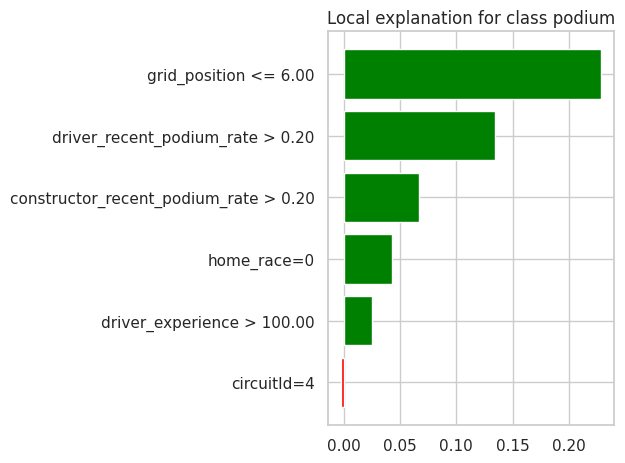

=== False positive (most confident) === model probability: 0.802
+0.217  grid_position <= 6.00
+0.124  driver_recent_podium_rate > 0.20
+0.067  constructor_recent_podium_rate > 0.20
+0.042  home_race=0
+0.007  47.00 < driver_experience <= 100.00
-0.002  circuitId=4


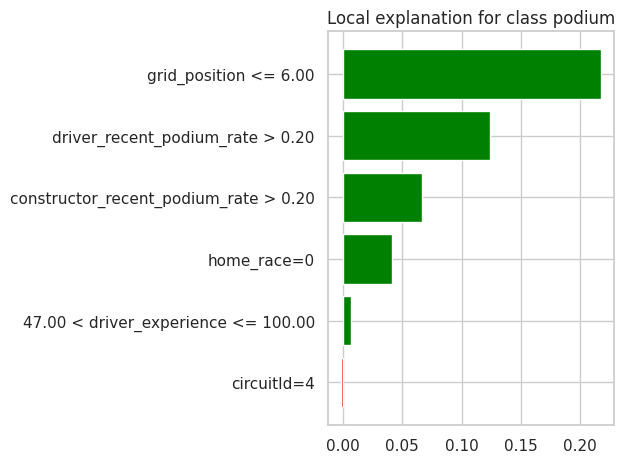

=== Missed podium (closest to threshold) === model probability: 0.458
+0.212  grid_position <= 6.00
-0.097  driver_recent_podium_rate <= 0.00
-0.060  constructor_recent_podium_rate <= 0.00
+0.037  home_race=0
+0.024  circuitId=7
+0.022  driver_experience > 100.00


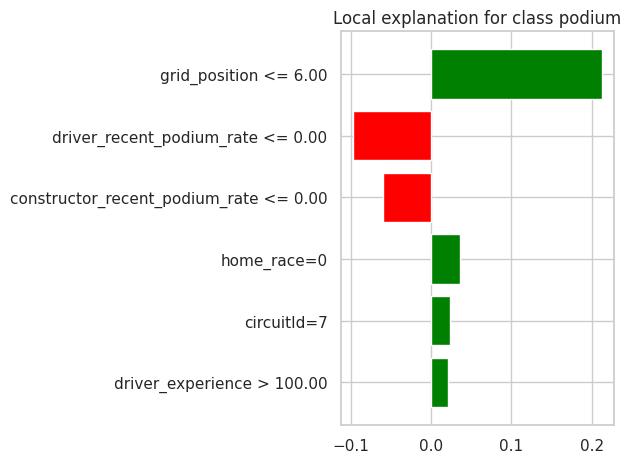


--- Stability check (seed 7) ---
=== False positive (most confident) === model probability: 0.802
+0.219  grid_position <= 6.00
+0.125  driver_recent_podium_rate > 0.20
+0.063  constructor_recent_podium_rate > 0.20
+0.048  home_race=0
+0.015  47.00 < driver_experience <= 100.00
+0.008  circuitId=4


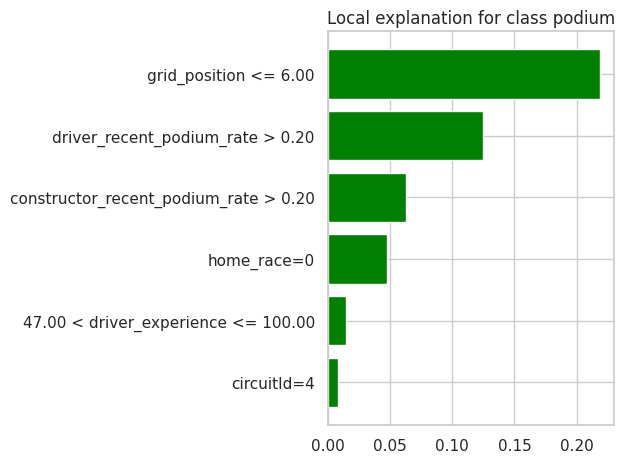

In [70]:
from lime.lime_tabular import LimeTabularExplainer

# Reference data for LIME: training rows, with missing values filled by training medians.
lime_train = X_train[final_feature_columns].copy()
lime_train = lime_train.fillna(lime_train.median(numeric_only=True)).to_numpy(dtype=np.float64)
cat_idx = [final_feature_columns.index("circuitId"), final_feature_columns.index("home_race")]
circuit_dtype = X_train["circuitId"].dtype

def lime_predict(x):
    df = pd.DataFrame(x, columns=final_feature_columns)
    df["circuitId"] = df["circuitId"].round().astype(circuit_dtype)
    p = np.asarray(final_predict_proba(df)).reshape(-1)
    return np.column_stack([1 - p, p])      # columns: [not podium, podium]

def make_lime(seed):
    return LimeTabularExplainer(
        lime_train, feature_names=final_feature_columns,
        class_names=["no podium", "podium"], categorical_features=cat_idx,
        mode="classification", discretize_continuous=True, random_state=seed)

lime_explainer = make_lime(RANDOM_STATE)

def explain_lime(case_name, explainer=lime_explainer):
    row = handoff_examples.loc[handoff_examples["case"] == case_name].iloc[0]
    arr = (handoff_examples.loc[[row.name], final_feature_columns]
           .apply(pd.to_numeric, errors="coerce").to_numpy(dtype=np.float64)[0])
    exp = explainer.explain_instance(arr, lime_predict, num_features=6, num_samples=5000)
    print(f"=== {case_name} === model probability:", round(float(row["podium_probability"]), 3))
    for rule, weight in exp.as_list():
        print(f"{weight:+.3f}  {rule}")
    exp.as_pyplot_figure()
    plt.tight_layout(); plt.show()
    return exp

explain_lime("True positive (most confident)")
explain_lime("False positive (most confident)")
explain_lime("Missed podium (closest to threshold)")

# Stability check: same row, different random seed.
print("\n--- Stability check (seed 7) ---")
_ = explain_lime("False positive (most confident)", explainer=make_lime(7))

In [71]:
FEATURES = list(final_feature_columns)
SEEN_CIRCUITS = set(X_train["circuitId"].dropna().unique())

# Fields that are only known after the race starts.
RESULT_FIELDS = {f.lower() for f in [
    "positionOrder", "position", "positionText", "points", "laps", "statusId", "status",
    "milliseconds", "time", "fastestLap", "fastestLapTime", "fastestLapSpeed", "rank",
    "stop", "duration", "pit_stops", "wins", "podium", "true_podium", "standings_after_race"]}

def predict_podium(record):
    """Predict podium probability from one pre-race record (dict or one-row DataFrame)."""
    if isinstance(record, pd.DataFrame):
        if len(record) != 1:
            raise ValueError("Pass exactly one row.")
        record = record.iloc[0].to_dict()
    if not isinstance(record, dict):
        raise TypeError("record must be a dict or a one-row DataFrame.")

    leaked = [k for k in record if str(k).lower() in RESULT_FIELDS]
    if leaked:
        raise ValueError(f"Race-result fields are not allowed (known only after the race): {leaked}")
    unknown = [k for k in record if k not in FEATURES]
    if unknown:
        raise ValueError(f"Unknown fields {unknown}. Allowed fields: {FEATURES}")

    values, missing = {}, []
    for f in FEATURES:
        v = record.get(f, None)
        if v is None or pd.isna(v):
            values[f] = np.nan
            missing.append(f)
        else:
            try:
                values[f] = float(v)
            except (TypeError, ValueError):
                raise ValueError(f"{f} must be a number, got {v!r}")

    if np.isnan(values["circuitId"]) or not float(values["circuitId"]).is_integer():
        raise ValueError("circuitId is required and must be a whole-number ID.")
    if not np.isnan(values["grid_position"]) and values["grid_position"] < 1:
        raise ValueError("grid_position must be at least 1 (use None for pit-lane starts).")
    if not np.isnan(values["driver_experience"]) and values["driver_experience"] < 0:
        raise ValueError("driver_experience must be 0 or more.")
    for rate in ["driver_recent_podium_rate", "constructor_recent_podium_rate"]:
        if not np.isnan(values[rate]) and not 0 <= values[rate] <= 1:
            raise ValueError(f"{rate} must be between 0 and 1.")
    if not np.isnan(values["home_race"]) and values["home_race"] not in (0.0, 1.0):
        raise ValueError("home_race must be 0, 1 or missing.")

    frame = pd.DataFrame([values])[FEATURES]
    frame["circuitId"] = frame["circuitId"].astype(X_train["circuitId"].dtype)

    prob = float(np.asarray(final_predict_proba(frame)).reshape(-1)[0])
    return {
        "podium_probability": round(prob, 4),
        "predicted_podium": int(prob >= final_threshold),
        "threshold": round(float(final_threshold), 3),
        "missing_fields": missing,
        "unseen_circuit": values["circuitId"] not in SEEN_CIRCUITS,
    }

In [72]:
# Test the function on a complete example.
example_row = handoff_examples.loc[
    handoff_examples["case"] == "True positive (most confident)"
].iloc[0]

test_record = example_row[FEATURES].to_dict()

result = predict_podium(test_record)

print("Prediction result:")
print(result)

Prediction result:
{'podium_probability': 0.8252, 'predicted_podium': 1, 'threshold': 0.472, 'missing_fields': [], 'unseen_circuit': False}


In [73]:
# Test the function with missing feature values.
incomplete_record = {
    "grid_position": 8,
    "driver_experience": 0,
    "driver_recent_podium_rate": np.nan,
    "constructor_recent_podium_rate": 0.0,
    "circuitId": 14,
    "home_race": 0
}

missing_result = predict_podium(incomplete_record)

print("Missing-input test:")
print(missing_result)

Missing-input test:
{'podium_probability': 0.1181, 'predicted_podium': 0, 'threshold': 0.472, 'missing_fields': ['driver_recent_podium_rate'], 'unseen_circuit': False}


### 4.6 Inference Function

`predict_podium` takes one record with the six pre-race fields and returns the model's podium probability.

- **Race results are rejected.** Fields known only after the race (finishing position, points, laps, status, times, pit stops, standings) raise an error, so the function cannot use the future.
- **Missing values are allowed.** They are filled with the training medians and flagged by the missing-indicator columns inside the pipeline, exactly as during training. The function lists which fields were missing.
- **Unseen circuits are handled.** A circuit not in the training data is encoded as all zeros and reported. `circuitId` itself is required.
- **Ranges are validated:** grid ≥ 1, experience ≥ 0, podium rates between 0 and 1, `home_race` 0 or 1.

The form features (`driver_recent_podium_rate`, `constructor_recent_podium_rate`) must be calculated from **earlier races** before calling the function. The function does not compute them.

In [74]:
def example(case):
    idx = handoff_examples.index[handoff_examples["case"] == case][0]
    return handoff_examples.loc[idx, FEATURES].to_dict()

print("(a) Complete record:")
print(predict_podium(example("True positive (most confident)")))

print("\n(b) Missing values: pit-lane starter (no grid position, no home-race value):")
print(predict_podium(example("True negative (most confident)")))

print("\n(c) Missing values: no recent driver history:")
print(predict_podium(example("Input with missing values")))

print("\n(d) Unseen circuit:")
print(predict_podium({**example("True positive (most confident)"), "circuitId": 9999}))

print("\n(e) Record containing a race result:")
try:
    predict_podium({**example("True positive (most confident)"), "positionOrder": 1})
except ValueError as err:
    print("Rejected ->", err)

# Consistency check against the probabilities stored in handoff_examples.
check = pd.DataFrame({
    "case": handoff_examples["case"].values,
    "stored": handoff_examples["podium_probability"].values,
    "function": [predict_podium(handoff_examples.loc[i, FEATURES].to_dict())["podium_probability"]
                 for i in handoff_examples.index]})
display(check)

(a) Complete record:
{'podium_probability': 0.8252, 'predicted_podium': 1, 'threshold': 0.472, 'missing_fields': [], 'unseen_circuit': False}

(b) Missing values: pit-lane starter (no grid position, no home-race value):
{'podium_probability': 0.0, 'predicted_podium': 0, 'threshold': 0.472, 'missing_fields': ['grid_position', 'home_race'], 'unseen_circuit': False}

(c) Missing values: no recent driver history:
{'podium_probability': 0.1181, 'predicted_podium': 0, 'threshold': 0.472, 'missing_fields': ['driver_recent_podium_rate'], 'unseen_circuit': False}

(d) Unseen circuit:
{'podium_probability': 0.7983, 'predicted_podium': 1, 'threshold': 0.472, 'missing_fields': [], 'unseen_circuit': True}

(e) Record containing a race result:
Rejected -> Race-result fields are not allowed (known only after the race): ['positionOrder']


,case,stored,function
0,True positive (most confident),8.251890e-01,0.8252
1,False positive (most confident),8.022090e-01,0.8022
2,Missed podium (closest to threshold),4.577040e-01,0.4577
3,True negative (most confident),1.140802e-10,0.0000
4,Input with missing values,1.180884e-01,0.1181


#### 4.6.1 Findings

- **Complete record:** probability 0.825, predicted podium (the 0.472 threshold is applied), for a pole-position driver with a perfect recent podium rate.
- **Missing values are accepted and reported.** For the pit-lane starter, `grid_position` and `home_race` are listed in `missing_fields` and the probability is essentially zero (about 1e-10, shown as 0.0 after rounding). For a driver with no recent podium history (`driver_recent_podium_rate` missing, experience 0), the probability is 0.118 and no podium is predicted. The pipeline fills these values with the training medians and flags them with missing-indicator columns, so the model sees them as "no information" and not as real zeros. The near-zero probability for the pit-lane starter rests on only 17 training rows with a missing grid position, so it is an extreme value from little data and should not be over-interpreted.
- **Unseen circuit:** the record is accepted, `unseen_circuit` is `True`, and the probability changes from 0.825 to 0.798. The circuit information is encoded as all zeros, and the small change is consistent with the minor role of circuit in 4.2 and 4.3.
- **Race-result field:** a record containing `positionOrder` is rejected with an error message, so the function cannot use information from after the start of the race.
- **Consistency:** the function reproduces the stored probabilities of all five prepared rows (differences below rounding).
- **Limitation:** the function does not compute the form features. They must be calculated from earlier races before calling it, as in Section 2.4.

### 4.7 Summary of the Explanation Stage

- **What the model relies on.** Permutation importance and SHAP agree that starting grid position is by far the most important feature, followed by recent driver form. Constructor form, circuit, home race and driver experience matter little. This agrees with the ablation in 3.6.
- **Direction.** A front-row start and strong recent podium rates raise the predicted probability; a back-of-grid start lowers it.
- **Local examples.**  The true positive received a high predicted podium probability of 0.8252, supported mainly by its front-row grid position and strong recent driver form. The false positive also received a high probability of 0.8022, despite not achieving a podium, showing that favorable input features do not guarantee the actual outcome. The missed podium received a probability of 0.4577, just below the 0.472 decision threshold, so the model classified it as a non-podium despite the actual podium result
- **Limits.** Explanations describe the model, not causes. Driver form, constructor form and grid are correlated, so credit is shared and small differences between the two methods should not be over-read. Explanations use a validation sample of 200 rows and a 100-row training background; LIME varies slightly between runs. The three prepared local examples come from 2022–2024.
- **Inference.** `predict_podium` handles complete and partly missing records and rejects race-result fields, but the form features must be computed from earlier races before calling it.